# GraMM-RAG — Phase C evidence notebook

Every table and figure from Gate C onward, regenerated inline from archived artefacts.
Companion to `gramm-rag-3benchmarks/joint_3benchmarks.ipynb`, which covers T-C0 (A1-A5)
and T-C1.

| Section | Content |
|---|---|
| 1 | Gate C — five systems, two benchmarks |
| 2 | Union arm and the size-matched control |
| 3 | Stratified report + the abstention confound check |
| 4 | B'-3 selective risk at matched coverage |
| 5 | B'-3 calibration of the utility function |
| 6 | Attribute decomposition (C/S/T) + AUC invariant |
| 7 | Graph provenance census (C-30) |
| 9 | **WP-1 graph bracket — GraMM vs LightRAG** |
| 10 | **Joint comparison table + WP-4 radar figures** |
| 11 | **All-metric comparison, conversion frontier, stratum trade-off** |
| 12 | **Gate A stratification across every comparator (dimension A)** |
| 13 | **Length-bin conversion curves, every system (dimension B)** |
| 14 | **Per-type / per-evidence-source stratification (dimension C)** |
| 15 | **Conversion efficiency with CIs (dimension D)** |
| 16 | **S1 - LightRAG on DocBench: pre-registered prediction falsified** |
| 17 | **Rank stability across benchmarks (G-2)** |
| 18 | **Mechanism for the abstention inversion (G-5)** |
| 19 | **WP-3 generator-side abstention - all three signals FAIL** |
| 20 | **D-1 gold-page diagnostic (separate study)** |
| 8 | Cost gate (C-31 / falsifier) |


In [1]:
import json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
%matplotlib inline
# ONE arm->colour map for the whole notebook: colour follows the ENTITY, never its rank.
# Validated with the dataviz validator (OKLab/CVD), both modes, all checks PASS for the seven
# comparators (worst CVD dE 9.1 light / 8.4 dark; worst normal-vision 19.6 / 19.3). It replaces
# a tab10 map that FAILED: GraMM<->Flat-vector normal-vision dE 13.3 (<15), MS GraphRAG outside
# the lightness band, and GraMM coloured differently in section 1 (#4C72B0) and section 10
# (#1f77b4). Flat-vector is neutral gray ON PURPOSE -- it is the control, not a ninth identity --
# so it trips only the chroma floor by design, and carries a dashed stroke as secondary encoding.
ARM_COL = {'GraMM-RAG':'#2a78d6', 'LightRAG 1.5.7':'#eb6834', 'RAG-Anything 1.2.8':'#1baf7a',
           'MS GraphRAG 2.7.2':'#eda100', 'ColPali':'#e87ba4', 'ColPali size-matched':'#008300',
           'Union(CP\u222aGraMM)':'#4a3aa7', 'Flat-vector':'#8a8984'}
for _k, _v in list(ARM_COL.items()):   # short aliases used by the gate-era sections
    ARM_COL.setdefault({'GraMM-RAG':'GraMM','Flat-vector':'Flat'}.get(_k, _k), _v)
ARM_DASH = {'Flat-vector': (0, (4, 2)), 'Flat': (0, (4, 2))}   # control = dashed
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10,
                     'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True})
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60)
ROOT = Path.cwd()
SC, CO, PR = ROOT/'scores', ROOT/'cost', ROOT/'provenance'
FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)
RES = ROOT/'tables'; RES.mkdir(exist_ok=True)
ARCH = ROOT.parent/'gramm-rag-3benchmarks'/'data'
def J(p): return json.loads(Path(p).read_text())
print('artefacts:', sorted(p.name for p in SC.glob('*.json'))[:4], '...')

artefacts: ['attr_decomp_docbench.json', 'attr_decomp_mmlongbench.json', 'attr_decomp_mmlongbench_gate.json', 'bprime3_calibration.json'] ...


## 1. Gate C — does GraMM's localisation advantage survive a strong retriever?

Only retrieval differs: identical parse, context assembly, prompt (PROMPT_V=3),
generator (`gpt-4.1-mini` + page images at dpi=120), scorers and judge (`gpt-4-turbo`).

In [2]:
rows = []
mb = J(ARCH/'mmlongbench/baseline_vector_mmlb.json')
mg = J(ARCH/'mmlongbench/gramm_mmlongbench_s42.json')
db = J(ARCH/'docbench/baseline_vector_docbench.json')
dg = J(ARCH/'docbench/gramm_docbench_s42.json')
cm = J(SC/'colpali_scores_mmlongbench.json'); cd = J(SC/'colpali_scores_docbench.json')
rows = [
 {'Benchmark':'MMLongBench','Metric':'ctx-hit','Flat':round(cm['ctx_hit_rate_baseline'],4),
  'GraMM':round(cm['ctx_hit_rate_gramm'],4),'ColPali':round(cm['ctx_hit_rate'],4)},
 {'Benchmark':'MMLongBench','Metric':'ANLS','Flat':round(mb['metrics']['anls'],4),
  'GraMM':round(mg['metrics']['anls'],4),'ColPali':round(cm['anls'],4)},
 {'Benchmark':'DocBench','Metric':'quote-recall@5','Flat':round(cd['quote_recall@5_baseline'],4),
  'GraMM':round(cd['quote_recall@5_gramm'],4),'ColPali':round(cd['quote_recall@5'],4)},
 {'Benchmark':'DocBench','Metric':'judge acc','Flat':round(db['judge']['judge_accuracy'],4),
  'GraMM':round(dg['judge']['judge_accuracy'],4),'ColPali':round(cd['judge_accuracy'],4)},
]
t1 = pd.DataFrame(rows)
print('=== Table 1 — Gate C ===('); display(t1); t1.to_csv(RES/'t1_gate_c.csv', index=False)
print()
print('DRIFT CHECK (archived controls reproduced before any ColPali number was used):')
assert abs(cm['ctx_hit_rate_baseline']-0.2327)<5e-4 and abs(cm['ctx_hit_rate_gramm']-0.4344)<5e-4
assert abs(cd['quote_recall@5_baseline']-0.3959)<5e-4 and abs(cd['quote_recall@5_gramm']-0.4534)<5e-4
print('  ctx-hit 0.2327/0.4344 and quote-recall@5 0.3959/0.4534  OK')
print(f"  run integrity: MMLB empty={cm['n_empty']} fail={cm['n_failures']} | "
      f"DocBench empty={cd['n_empty']} fail={cd['n_failures']} judgefail={cd['judge_failures']}")

=== Table 1 — Gate C ===(


,Benchmark,Metric,Flat,GraMM,ColPali
0,MMLongBench,ctx-hit,0.2327,0.4344,0.7995
1,MMLongBench,ANLS,0.3189,0.3522,0.4683
2,DocBench,quote-recall@5,0.3959,0.4534,0.5986
3,DocBench,judge acc,0.4728,0.5327,0.7740



DRIFT CHECK (archived controls reproduced before any ColPali number was used):
  ctx-hit 0.2327/0.4344 and quote-recall@5 0.3959/0.4534  OK
  run integrity: MMLB empty=0 fail=0 | DocBench empty=0 fail=0 judgefail=0


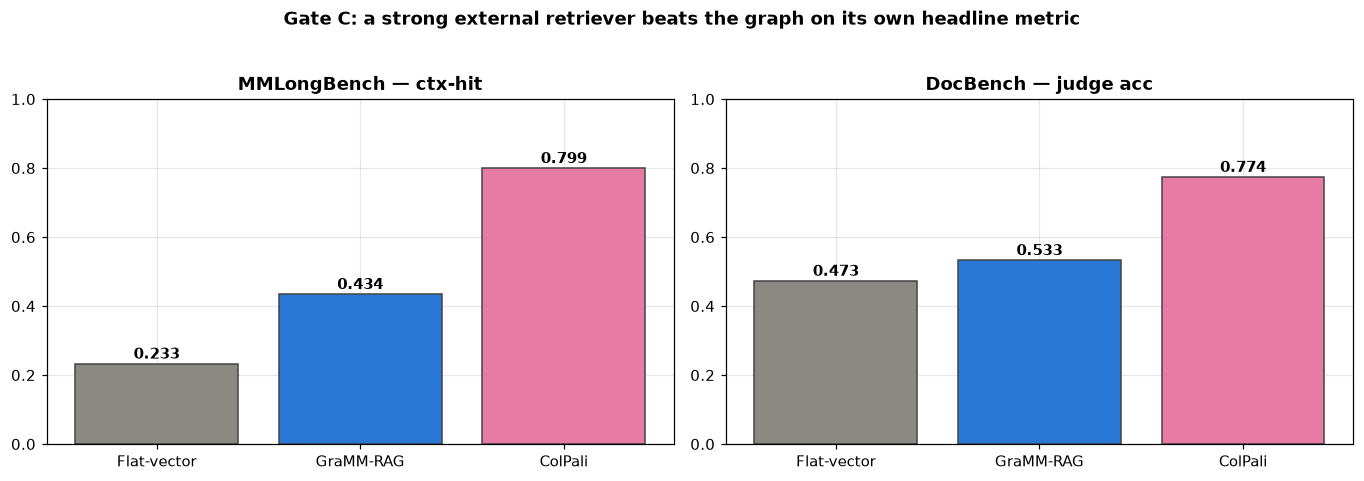

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
for ax, (bench, met) in zip(axes, [('MMLongBench','ctx-hit'),('DocBench','judge acc')]):
    r = t1[(t1.Benchmark==bench)&(t1.Metric==met)].iloc[0]
    v = [r['Flat'], r['GraMM'], r['ColPali']]
    b = ax.bar(['Flat-vector','GraMM-RAG','ColPali'], v,
               color=[ARM_COL['Flat'],ARM_COL['GraMM'],ARM_COL['ColPali']], edgecolor='#444')
    for bb, vv in zip(b, v):
        ax.text(bb.get_x()+bb.get_width()/2, vv+0.015, f'{vv:.3f}', ha='center',
                fontweight='bold')
    ax.set_title(f'{bench} — {met}', fontweight='bold'); ax.set_ylim(0, 1.0)
plt.suptitle('Gate C: a strong external retriever beats the graph on its own headline metric',
             fontweight='bold', y=1.03)
plt.tight_layout(); plt.savefig(FIG/'pc_fig1_gate_c.png', bbox_inches='tight'); plt.show()

## 2. Union arm and the size-matched control

The union of GraMM and ColPali pages averages 5.22 pages against 3 for each single arm,
so it is uninterpretable alone. The control gives ColPali the **same budget of its own
pages**, separating *more pages* from *complementary pages*.

In [4]:
sr = J(SC/'stratified_report.json')
rows = []
for bench in ('mmlongbench','docbench'):
    for sysn, d in sr[bench].items():
        rows.append({'Benchmark':bench,'System':sysn,
                     'pooled':round(d['pooled'],4),'answerable':round(d['answerable'],4),
                     'unanswerable':round(d['unanswerable'],4)})
t2 = pd.DataFrame(rows)
print('=== Table 2 — all five systems, by stratum ==='); display(t2)
t2.to_csv(RES/'t2_union_and_systems.csv', index=False)
print()
for bench in ('mmlongbench','docbench'):
    u = sr[bench].get('Union(CP∪GraMM)',{}).get('answerable')
    m = sr[bench].get('ColPali size-matched',{}).get('answerable')
    if u and m:
        verdict = 'control BEATS union' if m>u else 'union beats control'
        print(f'  {bench}: union {u:.4f} vs size-matched {m:.4f}  -> {verdict}')
print()
print('Same budget, different composition: the graph pages dilute relative to ColPali\'s')
print('own next-ranked pages. Without the control this reads as complementarity.')

=== Table 2 — all five systems, by stratum ===


,Benchmark,System,pooled,answerable,unanswerable
0,mmlongbench,Flat-vector,0.3189,0.1841,0.7869
1,mmlongbench,GraMM-RAG,0.3522,0.2436,0.7295
2,mmlongbench,ColPali,0.4683,0.4745,0.4467
3,mmlongbench,Union(CP∪GraMM),0.4628,0.4804,0.4016
4,mmlongbench,ColPali size-matched,0.4811,0.5017,0.4098
5,mmlongbench,LightRAG 1.5.7,0.3376,0.2199,0.7459
6,mmlongbench,RAG-Anything 1.2.8,0.3850,0.3401,0.5410
7,mmlongbench,MS GraphRAG 2.7.2,0.3201,0.1998,0.7377
8,mmlongbench,Flat-vector (k=3),0.3229,0.1987,0.7541
9,docbench,Flat-vector,0.4728,0.4458,0.6855



  mmlongbench: union 0.4804 vs size-matched 0.5017  -> control BEATS union
  docbench: union 0.7965 vs size-matched 0.7935  -> union beats control

Same budget, different composition: the graph pages dilute relative to ColPali's
own next-ranked pages. Without the control this reads as complementarity.


## 3. Stratified reporting and the abstention confound

**Reporting rule (enforced, not advisory).** On both corpora the gold answer to an
unanswerable question *is* a statement of non-availability, so accuracy on that stratum
and abstention rate are **one measurement in two units**. Never present them as
independent evidence.

In [5]:
rows=[]
for bench in ('mmlongbench','docbench'):
    for sysn,d in sr[bench].items():
        rows.append({'Benchmark':bench,'System':sysn,
            'dec|unans':round(d['decline_unans'],3),'dec|ans':round(d['decline_ans'],3),
            'abstention bal.acc':round(d['abstention_balanced_acc'],3)})
t3=pd.DataFrame(rows); print('=== Table 3 — abstention as a detector of unanswerable ===')
display(t3); t3.to_csv(RES/'t3_abstention.csv', index=False)
print()
for bench in ('mmlongbench','docbench'):
    b=[sr[bench][s]['abstention_balanced_acc'] for s in ('Flat-vector','GraMM-RAG','ColPali')]
    trend='decreasing' if b[0]>b[2] else 'increasing'
    print(f'  {bench}: Flat {b[0]:.3f} -> GraMM {b[1]:.3f} -> ColPali {b[2]:.3f}  ({trend})')
print()
print('The benchmarks DISAGREE in sign, so no monotone scaling law is available.')
print('An earlier version reported one; it came from a decline matcher that missed')
print('\'does not contain/include\' and understated DocBench 17x (C-27).')

=== Table 3 — abstention as a detector of unanswerable ===


,Benchmark,System,dec|unans,dec|ans,abstention bal.acc
0,mmlongbench,Flat-vector,0.791,0.166,0.812
1,mmlongbench,GraMM-RAG,0.734,0.122,0.806
2,mmlongbench,ColPali,0.463,0.041,0.711
3,mmlongbench,Union(CP∪GraMM),0.434,0.045,0.695
4,mmlongbench,ColPali size-matched,0.447,0.035,0.706
5,mmlongbench,LightRAG 1.5.7,0.758,0.130,0.814
6,mmlongbench,RAG-Anything 1.2.8,0.566,0.067,0.749
7,mmlongbench,MS GraphRAG 2.7.2,0.754,0.128,0.813
8,mmlongbench,Flat-vector (k=3),0.758,0.140,0.809
9,docbench,Flat-vector,0.702,0.297,0.703



  mmlongbench: Flat 0.812 -> GraMM 0.806 -> ColPali 0.711  (decreasing)
  docbench: Flat 0.703 -> GraMM 0.750 -> ColPali 0.785  (increasing)

The benchmarks DISAGREE in sign, so no monotone scaling law is available.
An earlier version reported one; it came from a decline matcher that missed
'does not contain/include' and understated DocBench 17x (C-27).


## 4. B'-3 — selective risk on the answerable stratum, at matched coverage

Un-gameable: a policy that buys unanswerable accuracy by abstaining more pays for it in
coverage here. Confidence is one uniform instrument (ColQwen2 MaxSim) applied to
whatever pages each system chose.

In [6]:
sr3 = J(SC/'bprime3_selective_risk.json')
rows=[]
for bench,d in sr3.items():
    for sysn,v in d.items():
        r={'Benchmark':bench,'System':sysn,'conf|ans':round(v['conf_ans'],3),
           'conf|unans':round(v['conf_unans'],3),'AUC':round(v['auc'],3)}
        r.update({f'risk@cov{k}':round(v['risk_at'][k],3) for k in ('1.0','0.8','0.6','0.4')})
        rows.append(r)
t4=pd.DataFrame(rows); print('=== Table 4 — selective risk (lower is better) ===')
display(t4); t4.to_csv(RES/'t4_selective_risk.csv', index=False)

=== Table 4 — selective risk (lower is better) ===


,Benchmark,System,conf|ans,conf|unans,AUC,risk@cov1.0,risk@cov0.8,risk@cov0.6,risk@cov0.4
0,mmlongbench,Flat,17.903,17.578,0.534,0.816,0.794,0.782,0.767
1,mmlongbench,GraMM,18.936,18.485,0.537,0.756,0.726,0.719,0.700
2,mmlongbench,ColPali,21.184,20.817,0.536,0.526,0.488,0.468,0.481
3,docbench,Flat,16.564,12.414,0.779,0.554,0.528,0.517,0.464
4,docbench,GraMM,17.295,12.519,0.798,0.491,0.467,0.454,0.408
5,docbench,ColPali,18.928,13.472,0.811,0.206,0.164,0.127,0.139


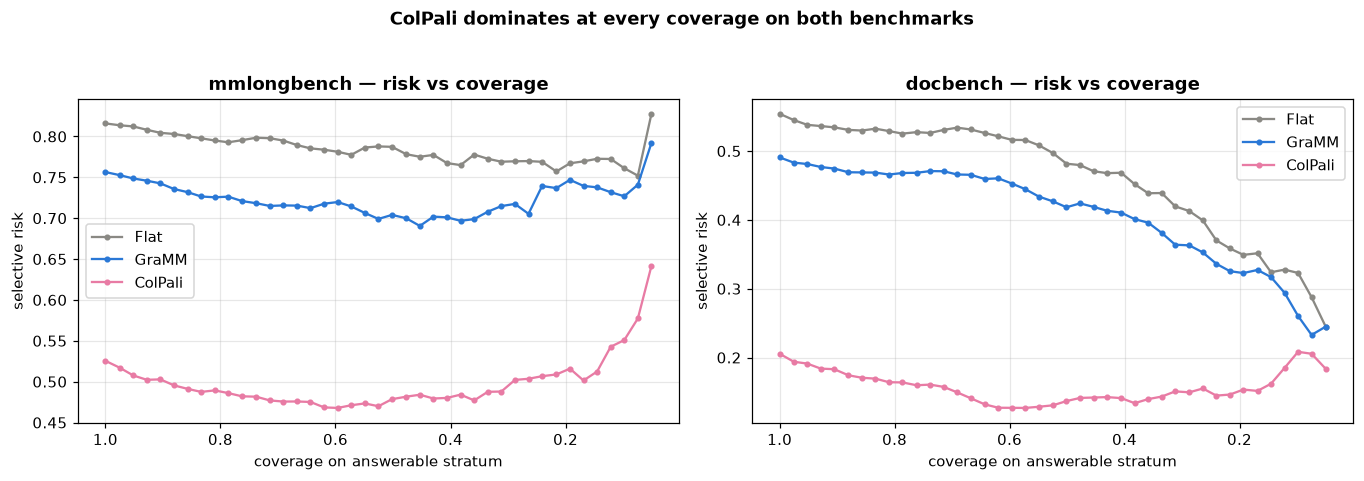

In [7]:
fig, axes = plt.subplots(1,2, figsize=(12.5,4.2))
for ax,(bench,d) in zip(axes, sr3.items()):
    for sysn,c in ((k, ARM_COL[k]) for k in ('Flat','GraMM','ColPali')):
        cur=d[sysn]['curve']
        if not cur: continue
        cur=sorted(cur); ax.plot([c0 for c0,_ in cur],[r for _,r in cur],'-o',ms=3,
                                 color=c,label=sysn)
    ax.set_xlabel('coverage on answerable stratum'); ax.set_ylabel('selective risk')
    ax.set_title(f'{bench} — risk vs coverage', fontweight='bold'); ax.legend()
    ax.invert_xaxis()
plt.suptitle('ColPali dominates at every coverage on both benchmarks',
             fontweight='bold', y=1.03)
plt.tight_layout(); plt.savefig(FIG/'pc_fig2_selective_risk.png', bbox_inches='tight'); plt.show()

## 5. B'-3 — calibrating the Multi-attribute Utility Function

Reported against ceilings, never an unbounded target (Rule 10). `achieved_gen` is
**GraMM's generator's achieved** balanced accuracy on identical context — not a ceiling:
ColPali's reaches 0.785 on DocBench, above GraMM's 0.750.

In [8]:
cal = J(SC/'bprime3_calibration.json')
rows=[]
for bench,d in cal.items():
    r={'Benchmark':bench,'AUC of U':round(d['auc_U'],3),
       'shipped tau=0':round(d['shipped_tau0'],3),
       'global tau CV':round(d['global_tau_cv'],3)}
    for k,v in d['per_stratum_cv'].items(): r[f'per-stratum ({k})']=round(v,3)
    # the JSON predates the ceiling_gen -> achieved_gen rename; accept either key
    _ag = d.get('achieved_generator', d.get('ceiling_generator'))
    r['ceiling_U']=round(d['ceiling_U'],3); r['achieved_gen']=round(_ag,3)
    rows.append(r)
t5=pd.DataFrame(rows); print('=== Table 5 — abstention policies on U ==='); display(t5)
t5.to_csv(RES/'t5_calibration.csv', index=False)
print()
print('Per-stratum calibration is NOT supported: identical to global on DocBench, and')
print('inconsistent in SIGN across stratifications on MMLongBench (noise).')
print('The shipped policy (tau=0, 0 refusals) scores 0.500 -- chance -- on both.')

=== Table 5 — abstention policies on U ===


,Benchmark,AUC of U,shipped tau=0,global tau CV,per-stratum (doc_type),per-stratum (len_bin),ceiling_U,achieved_gen,per-stratum (type)
0,mmlongbench,0.557,0.5,0.552,0.573,0.529,0.560,0.806,NaN
1,docbench,0.723,0.5,0.673,NaN,0.669,0.686,0.750,0.673



Per-stratum calibration is NOT supported: identical to global on DocBench, and
inconsistent in SIGN across stratifications on MMLongBench (noise).
The shipped policy (tau=0, 0 refusals) scores 0.500 -- chance -- on both.


## 6. Attribute decomposition — does ANY reweighting of C/S/T detect answerability?

Marginal AUC answers *were our weights wrong*; the cross-validated joint logistic answers
*does any reweighting work*. The **AUC(x)+AUC(-x)=1 invariant** is asserted below — its
violation is what exposed C-29.

In [9]:
rows=[]
for bench in ('mmlongbench','docbench'):
    d=J(SC/f'attr_decomp_{bench}.json')
    rows.append({'Benchmark':bench,'n':d['n'],
      'C':round(d['auc_coverage'],3),'S':round(d['auc_similarity'],3),
      'T':round(d['auc_temporal'],3),'U (shipped)':round(d['auc_U'],3),
      'joint CV':round(d['joint_cv_auc'],3),
      'gate':('PASS' if d['gate_pass'] else 'FAIL'),
      'excluded':d.get('n_excluded_boundary',0)})
t6=pd.DataFrame(rows); print('=== Table 6 — attribute decomposition ==='); display(t6)
t6.to_csv(RES/'t6_attribute_decomposition.csv', index=False)
print()
for _,r in t6.iterrows():
    best=max(r['C'],r['S'],r['T'])
    assert r['joint CV']>=best-1e-9, (
        f"Rule 8 violated on {r['Benchmark']}: joint {r['joint CV']} < best marginal {best}")
    print(f"  {r['Benchmark']}: joint {r['joint CV']:.3f} >= best marginal {best:.3f}  OK (Rule 8)")
print()
print('S and T are at chance on both corpora; C alone accounts for the discrimination.')
print('NOTE: a fixed weighting (aC+bS) can EXCEED the fitted joint on AUC -- logistic')
print('regression optimises log-loss, not AUC. That is not a Rule 8 violation.')

=== Table 6 — attribute decomposition ===


,Benchmark,n,C,S,T,U (shipped),joint CV,gate,excluded
0,mmlongbench,1091,0.568,0.507,0.484,0.556,0.568,PASS,3
1,docbench,1102,0.717,0.565,0.499,0.723,0.728,PASS,0



  mmlongbench: joint 0.568 >= best marginal 0.568  OK (Rule 8)
  docbench: joint 0.728 >= best marginal 0.717  OK (Rule 8)

S and T are at chance on both corpora; C alone accounts for the discrimination.
NOTE: a fixed weighting (aC+bS) can EXCEED the fitted joint on AUC -- logistic
regression optimises log-loss, not AUC. That is not a Rule 8 violation.


## 7. Graph provenance census (C-30)

`RUN_CONFIG` never stamped the graph. Chapter 3 claims 8 typed edges and a trained HGT;
before this census the archive could confirm neither.

In [10]:
gp = J(PR/'graph_provenance.json')
rows=[]
rels = sorted(gp['mmlongbench']['edge_type_counts'])
for rel in rels:
    r={'relation':rel,'model-extracted':rel in gp['mmlongbench']['model_extracted_types']}
    for b in ('mmlongbench','docbench'):
        c=gp[b]['edge_type_counts'][rel]
        r[f'{b} %docs']=c['pct_docs']; r[f'{b} median']=c['median']
    rows.append(r)
t7=pd.DataFrame(rows); print('=== Table 7 — edge-type census ==='); display(t7)
t7.to_csv(RES/'t7_edge_census.csv', index=False)
hb=gp['hgt_behavioural_mmlongbench']
print()
print(f"  HGT behavioural: trained APPA@10 {hb['appa10_trained']} vs fresh-init "
      f"{hb['appa10_fresh_init']} (delta {hb['delta']:+.3f}, n={hb['n']}) -> {hb['verdict']}")
print(f"  degenerate types: MMLB {gp['mmlongbench']['degenerate_types']} | "
      f"DocBench {gp['docbench']['degenerate_types']}")
print(f"  8 defined, {8-len(set(gp['mmlongbench']['degenerate_types'])|set(gp['docbench']['degenerate_types']))}"
      f" contributing on both corpora")

=== Table 7 — edge-type census ===


,relation,model-extracted,mmlongbench %docs,mmlongbench median,docbench %docs,docbench median
0,caption,False,5.9,0,2.6,0
1,coref,False,98.5,1870,98.3,1766
2,crosspage,False,98.5,1592,76.0,1630
3,hierarchy,False,100.0,122,100.0,78
4,kg,True,72.6,28,90.8,38
5,reading_order,False,100.0,75,100.0,63
6,spatial,False,64.4,1,40.6,0
7,temporal,False,69.6,42,88.2,506



  HGT behavioural: trained APPA@10 0.806 vs fresh-init 0.448 (delta +0.358, n=67) -> PASS
  degenerate types: MMLB ['caption'] | DocBench ['spatial', 'caption']
  8 defined, 6 contributing on both corpora


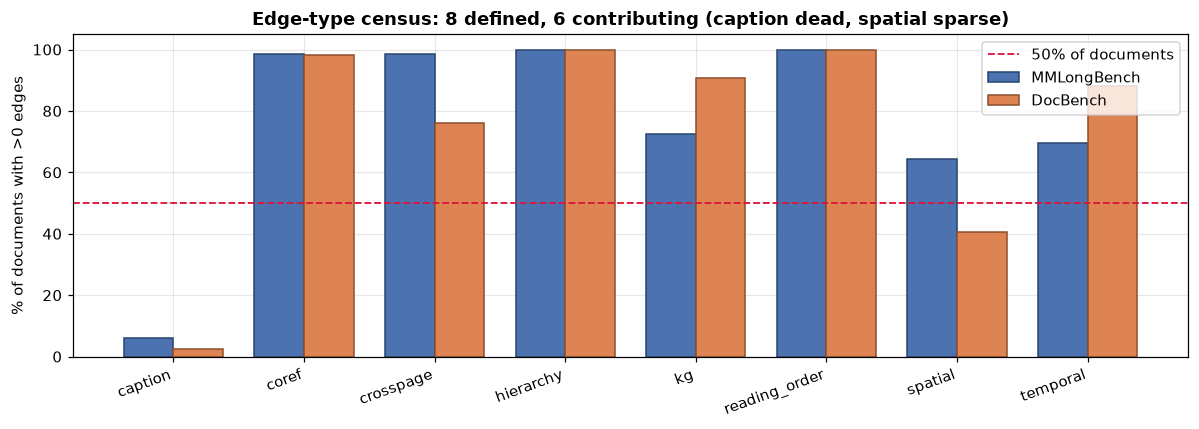

In [11]:
fig, ax = plt.subplots(figsize=(11,4))
x=np.arange(len(rels)); w=0.38
mm=[gp['mmlongbench']['edge_type_counts'][r]['pct_docs'] for r in rels]
dd=[gp['docbench']['edge_type_counts'][r]['pct_docs'] for r in rels]
ax.bar(x-w/2, mm, w, label='MMLongBench', color='#4C72B0', edgecolor='#28456e')
ax.bar(x+w/2, dd, w, label='DocBench', color='#DD8452', edgecolor='#8c4f2c')
ax.axhline(50, color='crimson', ls='--', lw=1.2, label='50% of documents')
ax.set_xticks(x); ax.set_xticklabels(rels, rotation=20, ha='right')
ax.set_ylabel('% of documents with >0 edges')
ax.set_title('Edge-type census: 8 defined, 6 contributing (caption dead, spatial sparse)',
             fontweight='bold'); ax.legend()
plt.tight_layout(); plt.savefig(FIG/'pc_fig3_edge_census.png', bbox_inches='tight'); plt.show()

## 8. Cost gate — the pre-registered falsifier

Falsifier, written before measurement: *if GraMM's total preparation exceeds ColPali's,
the general cost claim is withdrawn.*

In [12]:
hgt=J(CO/'hgt_training.json'); e5=J(CO/'e5_10pct.json')
cq=J(CO/'colpali_query.json'); gq=J(CO/'cost_measurements.json')
PAGES=20530
cp_embed=(116.8+262.5)/60
gm_parse=0.7*PAGES/3600
gm_e5=e5['total_hours_using_mean']
gm_hgt=hgt['total_hgt_A100_h']
gm=gm_parse+gm_e5+gm_hgt
t8=pd.DataFrame([
 {'System':'ColPali','stage':'render (CPU)','A100-h':round((10.2+17.7)/60,2)},
 {'System':'ColPali','stage':'embed + index','A100-h':round(cp_embed,2)},
 {'System':'GraMM','stage':'MinerU parse','A100-h':round(gm_parse,2)},
 {'System':'GraMM','stage':'E5 node embed','A100-h':round(gm_e5,2)},
 {'System':'GraMM','stage':'HGT training','A100-h':round(gm_hgt,2)},
])
print('=== Table 8 — preparation, 20,530 corpus pages ==='); display(t8)
t8.to_csv(RES/'t8_cost_preparation.csv', index=False)
print()
print(f'  ColPali total : {cp_embed:.2f} A100-h')
print(f'  GraMM total   : {gm:.2f} A100-h  (SigLIP + edge construction still unmeasured)')
print(f'  ratio         : {gm/cp_embed:.2f}x   excess {gm-cp_embed:+.2f} A100-h')
fired = gm > cp_embed
print()
print(f'  FALSIFIER {"FIRED -> general cost claim WITHDRAWN" if fired else "did not fire"}')
d=cq['colpali_query_ms']['median']-gq['gramm_query_ms']['median']
print(f'  query saving {d:.0f} ms -> crossover at {(gm-cp_embed)*3.6e6/d:,.0f} queries')

=== Table 8 — preparation, 20,530 corpus pages ===


,System,stage,A100-h
0,ColPali,render (CPU),0.46
1,ColPali,embed + index,6.32
2,GraMM,MinerU parse,3.99
3,GraMM,E5 node embed,0.67
4,GraMM,HGT training,4.64



  ColPali total : 6.32 A100-h
  GraMM total   : 9.31 A100-h  (SigLIP + edge construction still unmeasured)
  ratio         : 1.47x   excess +2.99 A100-h

  FALSIFIER FIRED -> general cost claim WITHDRAWN
  query saving 31 ms -> crossover at 347,305 queries


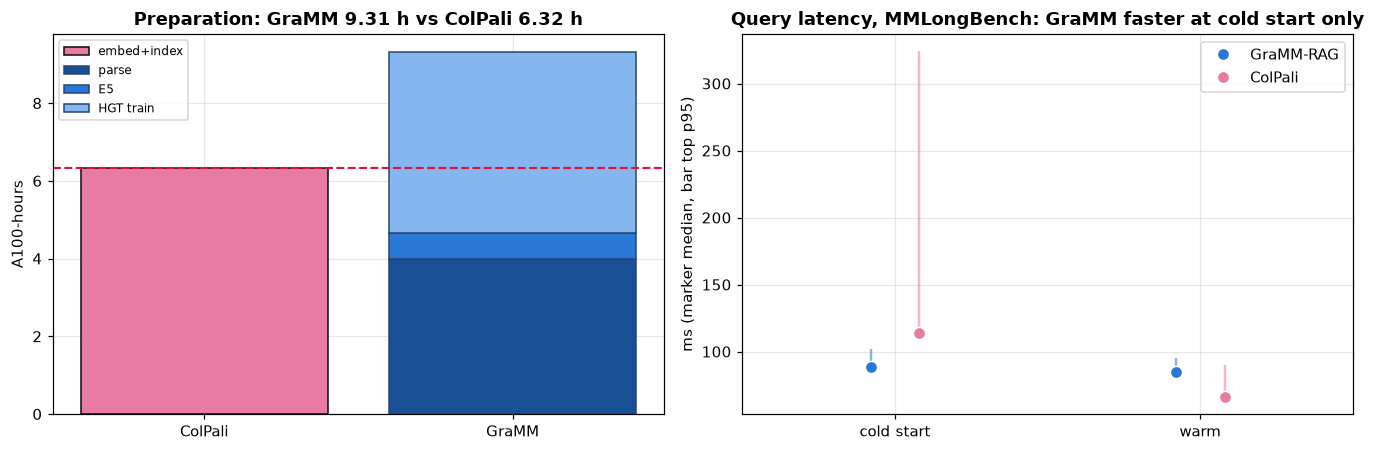

In [13]:
fig, axes = plt.subplots(1,2, figsize=(12.5,4.2))
ax=axes[0]
ax.bar(['ColPali'],[cp_embed], color=ARM_COL['ColPali'], edgecolor='#0b0b0b', label='embed+index')
b=0
for lab,v,c in (('parse',gm_parse,'#184f95'),('E5',gm_e5,'#2a78d6'),('HGT train',gm_hgt,'#86b6ef')):
    ax.bar(['GraMM'],[v], bottom=[b], color=c, edgecolor='#28456e', label=lab); b+=v
ax.axhline(cp_embed, color='crimson', ls='--', lw=1.4)
ax.set_ylabel('A100-hours'); ax.legend(fontsize=8)
ax.set_title(f'Preparation: GraMM {gm:.2f} h vs ColPali {cp_embed:.2f} h', fontweight='bold')
ax=axes[1]
# This panel first plotted a single PRE-cost-gate measurement under the title 'GraMM wins, and is
# far more predictable' -- the general query-time claim the cost gate WITHDREW (ColPali is faster
# warm on both corpora). It now plots the cost gate's own cold AND warm cells, so the surviving
# claim -- faster and more predictable at COLD START ONLY -- is visible rather than asserted.
_L = json.loads(Path('/work/gramm-rag-colpali/cost/query_latency_v2.json').read_text())['cells']
for sk, lab in (('gramm','GraMM-RAG'), ('colpali','ColPali')):
    for j, st in enumerate(('cold','warm')):
        c = _L[f'{sk}|mmlongbench|{st}']; xx = j + (-0.08 if sk == 'gramm' else 0.08)
        ax.vlines(xx, c['median'], c['p95'], color=ARM_COL[lab], lw=1.6, alpha=.55)
        ax.plot(xx, c['median'], marker='o', ms=8, ls='none', color=ARM_COL[lab], mec='white',
                label=lab if j == 0 else None)
ax.set_xticks([0, 1]); ax.set_xticklabels(['cold start', 'warm']); ax.set_xlim(-0.5, 1.5)
ax.set_ylabel('ms (marker median, bar top p95)')
ax.set_title('Query latency, MMLongBench: GraMM faster at cold start only', fontweight='bold')
ax.legend()
plt.tight_layout(); plt.savefig(FIG/'pc_fig4_cost.png', bbox_inches='tight'); plt.show()

## 9. WP-1 Tier 1 — the graph bracket (GraMM vs LightRAG, MMLongBench)

The advisor directive's comparison: a **matched** comparison against an external
graph-RAG system rather than against this project's internal control.

Scope per `GATE_G_RESULT.md`: MMLongBench only. The $10 cost gate was **not raised**;
DocBench ($18.00) and the RAG-Anything arm ($136.73) were priced out to Tier 3.

Only retrieval differs: identical MinerU parse (via the canonical
`mapper.elements_to_text`), 3-page budget, prompt builder, generator and scorer.
LightRAG runs `hybrid`, pre-registered before any quality number existed, with one
store per document (C-35/C-36).

In [14]:
import json, numpy as np
from pathlib import Path
from math import comb

ARCH = Path('/work/gramm-rag-3benchmarks/data/mmlongbench')
RET  = Path('/work/gramm-rag-colpali/retrieval')
base  = json.loads((ARCH/'baseline_vector_mmlb.json').read_text())
gramm = json.loads((ARCH/'gramm_mmlongbench_s42.json').read_text())
lr    = json.loads((RET/'lightrag_retrieval_mmlongbench.json').read_text())
gold, ans = base['gold_pages'], base['is_answerable']

def ctx_flags(cp):
    'Canonical ctx-hit predicate: exclude unanswerable AND empty gold_pages (C-8/C-9).'
    return np.array([1 if any(g in cp[i] for g in gold[i]) else 0
                     for i in range(len(gold)) if ans[i] and gold[i]])

G = ctx_flags(gramm['context_pages'])
L = ctx_flags(lr['context_pages'])
B = ctx_flags(base['context_pages'])
print(f'ctx-hit  n={len(G)}   GraMM {G.mean():.4f}   LightRAG {L.mean():.4f}   Flat {B.mean():.4f}')

# DRIFT CHECK (Rule 8): archived figures must reproduce before anything is believed.
assert abs(G.mean() - 0.4344) < 5e-4, f'GraMM ctx-hit drift: {G.mean()}'
assert abs(B.mean() - 0.2327) < 5e-4, f'baseline ctx-hit drift: {B.mean()}'
assert len(G) == 838, f'ctx-hit denominator changed: {len(G)}'
print('drift check OK: archived ctx-hit reproduced (0.2327 / 0.4344), n=838')

# C-80: the page-matched control, on the same predicate and the same 838 questions. The
# archived k=2 arm above is kept because the drift check pins the published numbers; the
# contrast that carries weight is the one against a control reading the same three pages.
_f3 = Path('/work/gramm-rag-colpali/generation/flatk3_gen_mmlongbench.json')
B3 = ctx_flags(json.loads(_f3.read_text())['context_pages']) if _f3.exists() else None
if B3 is not None:
    print(f'ctx-hit  page-matched control (k=3): {B3.mean():.4f}  '
          f'(k=2 control {B.mean():.4f}; the third page is worth {B3.mean()-B.mean():+.4f})')

ctx-hit  n=838   GraMM 0.4344   LightRAG 0.2816   Flat 0.2327
drift check OK: archived ctx-hit reproduced (0.2327 / 0.4344), n=838
ctx-hit  page-matched control (k=3): 0.2780  (k=2 control 0.2327; the third page is worth +0.0453)


### 9.1 Localisation — paired bootstrap + exact McNemar
2,000 resamples, seed 42. McNemar is the exact two-sided binomial on discordant pairs.

In [15]:
rng = np.random.default_rng(42)
def paired(a, b, n=2000):
    d = a - b
    bs = d[rng.integers(0, len(d), (n, len(d)))].mean(axis=1)
    return d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
def mcnemar(a, b):
    n10 = int(((a==1)&(b==0)).sum()); n01 = int(((a==0)&(b==1)).sum())
    N = n01 + n10
    if not N: return n10, n01, 1.0
    k = min(n01, n10)
    return n10, n01, min(1.0, 2*sum(comb(N, j) for j in range(k+1))/(2**N))

print(f"{'contrast':24s}{'delta':>10s}{'95% CI':>24s}{'McNemar p':>13s}")
_rows = [('GraMM - LightRAG', G, L), ('LightRAG - Flat k=2', L, B), ('GraMM - Flat k=2', G, B)]
if B3 is not None:
    _rows += [('GraMM - Flat k=3 *', G, B3), ('LightRAG - Flat k=3 *', L, B3)]
for nm, a, b in _rows:
    m, lo, hi = paired(a, b); n10, n01, pv = mcnemar(a, b)
    star = '*' if (lo > 0 or hi < 0) else ' '
    print(f'{nm:24s}{m:>+10.4f}   [{lo:+.4f},{hi:+.4f}]{star}{pv:>12.3g}   b={n10} c={n01}')
print('\n* after a CI = it excludes zero. A * in the CONTRAST NAME marks the page-matched')
print('control (C-80): the k=2 rows reproduce the published M9 figures and are kept for that,')
print('but a GraMM-vs-control claim is made against the k=3 row.')

contrast                     delta                  95% CI    McNemar p
GraMM - LightRAG           +0.1527   [+0.1134,+0.1945]*    7.67e-12   b=240 c=112
LightRAG - Flat k=2        +0.0489   [+0.0095,+0.0871]*      0.0139   b=153 c=112
GraMM - Flat k=2           +0.2017   [+0.1730,+0.2303]*     6.8e-42   b=178 c=9
GraMM - Flat k=3 *         +0.1563   [+0.1241,+0.1874]*    3.79e-23   b=160 c=29
LightRAG - Flat k=3 *      +0.0036   [-0.0346,+0.0418]        0.901   b=131 c=128

* after a CI = it excludes zero. A * in the CONTRAST NAME marks the page-matched
control (C-80): the k=2 rows reproduce the published M9 figures and are kept for that,
but a GraMM-vs-control claim is made against the k=3 row.


### 9.2 Answer quality — the same contrast on ANLS, stratified
The localisation win above does **not** carry through. Reported stratified because
pooled-only numbers are not acceptable for this project.

In [16]:
import sys; sys.path.insert(0, '/work/gramm-rag-mmlongbench')
from src.evaluation.metrics import anls_score
GEN = Path('/work/gramm-rag-colpali/generation')
lrg = json.loads((GEN/'lightrag_gen_mmlongbench.json').read_text())
golds = base['golds']
sc = {'Flat-vector': base['predictions'], 'GraMM-RAG': gramm['predictions'],
      'LightRAG 1.5.7': lrg['predictions']}
S = {k: np.array([anls_score(p, t) for p, t in zip(v, golds)]) for k, v in sc.items()}
A = np.array([i for i, x in enumerate(ans) if x])
U = np.array([i for i, x in enumerate(ans) if not x])
print(f"{'system':18s}{'pooled':>9s}{'answerable':>12s}{'unanswerable':>14s}")
for k, v in S.items():
    print(f'{k:18s}{v.mean():>9.4f}{v[A].mean():>12.4f}{v[U].mean():>14.4f}')

print(f"\n{'contrast':26s}{'answerable':>26s}{'unanswerable':>26s}")
for k in ('LightRAG 1.5.7', 'Flat-vector'):
    row = f'{k} - GraMM-RAG'
    out = ''
    for idx in (A, U):
        m, lo, hi = paired(S[k][idx], S['GraMM-RAG'][idx])
        out += f'  {m:+.4f} [{lo:+.4f},{hi:+.4f}]' + ('*' if (lo>0 or hi<0) else ' ')
    print(f'{row:26s}{out}')
print('\n* after a CI = it excludes zero. A * in the CONTRAST NAME marks the page-matched')
print('control (C-80): the k=2 rows reproduce the published M9 figures and are kept for that,')
print('but a GraMM-vs-control claim is made against the k=3 row.')

system               pooled  answerable  unanswerable
Flat-vector          0.3189      0.1841        0.7869
GraMM-RAG            0.3522      0.2436        0.7295
LightRAG 1.5.7       0.3376      0.2199        0.7459

contrast                                  answerable              unanswerable
LightRAG 1.5.7 - GraMM-RAG  -0.0236 [-0.0573,+0.0093]   +0.0164 [-0.0533,+0.0820] 
Flat-vector - GraMM-RAG     -0.0595 [-0.0822,-0.0367]*  +0.0574 [+0.0205,+0.0984]*

* after a CI = it excludes zero. A * in the CONTRAST NAME marks the page-matched
control (C-80): the k=2 rows reproduce the published M9 figures and are kept for that,
but a GraMM-vs-control claim is made against the k=3 row.


### 9.3 The power limit, stated before the reader asks

The answer-quality null is a **failure to reject, not a demonstration of equivalence**,
and the design cannot rule out a practically meaningful difference. The cell below
compares the CI's upper bound against GraMM's own established margin over flat-vector.

In [17]:
m, lo, hi = paired(S['GraMM-RAG'][A], S['LightRAG 1.5.7'][A])
gramm_margin = S['GraMM-RAG'].mean() - S['Flat-vector'].mean()
print(f'GraMM - LightRAG (answerable): {m:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]')
print(f"GraMM's established margin over flat-vector (pooled ANLS): {gramm_margin:+.4f}")
print(f'\nCI upper bound {hi:+.4f} vs that margin {gramm_margin:+.4f}: '
      f"{'EXCEEDS -- a practically meaningful difference is NOT excluded' if hi > gramm_margin else 'within'}")
print('\nSo the null bounds the effect only loosely: the data are compatible with GraMM')
print('being better by more than its entire advantage over the internal control.')
print('Scope limit: ONE benchmark. DocBench was cut for budget (Gate G), which is a')
print('scope limit, not evidence of generality.')

GraMM - LightRAG (answerable): +0.0236  95% CI [-0.0074, +0.0567]
GraMM's established margin over flat-vector (pooled ANLS): +0.0334

CI upper bound +0.0567 vs that margin +0.0334: EXCEEDS -- a practically meaningful difference is NOT excluded

So the null bounds the effect only loosely: the data are compatible with GraMM
being better by more than its entire advantage over the internal control.
Scope limit: ONE benchmark. DocBench was cut for budget (Gate G), which is a
scope limit, not evidence of generality.


### 9.4 Page-provenance integrity
LightRAG does not track pages, so pages are **recovered** by matching returned chunk
text back to the ingested text. That mapping's quality is measured, never assumed.

In [18]:
al = [x for x in lr['alignment_rate'] if x is not None]
al_s = sorted(al); q = lambda p: al_s[int(p*(len(al_s)-1))]
print(f'alignment  n={len(al)}  mean {np.mean(al):.4f}  p10 {q(.10):.4f}  '
      f'median {q(.50):.4f}  p90 {q(.90):.4f}')
print(f'  below 0.5: {sum(1 for x in al if x<0.5)}   exactly 0: {sum(1 for x in al if x==0)}')
print('  distribution is BIMODAL: attribution recovers ~99% or exactly nothing.')
print('  The 18 zero-attribution questions are left as MISSES, not back-filled.')
assert lr['RUN_CONFIG']['LIGHTRAG_MODE'] == 'hybrid'
assert lr['RUN_CONFIG']['MODE_PREREGISTERED'] is True
assert L.mean() != G.mean(), 'retrieval-differs assertion: adapter not routing LightRAG'
print('\nRUN_CONFIG:', json.dumps(lr['RUN_CONFIG'], indent=1)[:600])

alignment  n=1091  mean 0.9765  p10 0.9901  median 0.9949  p90 0.9966
  below 0.5: 18   exactly 0: 18
  distribution is BIMODAL: attribution recovers ~99% or exactly nothing.
  The 18 zero-attribution questions are left as MISSES, not back-filled.

RUN_CONFIG: {
 "RETRIEVER": "lightrag",
 "LIGHTRAG_VERSION": "1.5.7",
 "LIGHTRAG_MODE": "hybrid",
 "MODE_PREREGISTERED": true,
 "RETRIEVAL_SCOPE": "per-document store (C-35)",
 "LLM_MODEL": "gpt-4o-mini",
 "EMB_MODEL": "text-embedding-3-small",
 "TOPK": 3,
 "PAGE_ATTRIBUTION": "chunk->ingested-text shingle map",
 "PAGE_RANKING": "LightRAG chunk relevance order; mass breaks ties (C-37)",
 "SHINGLE_CHARS": 50,
 "INDEX_STRIDE": 1,
 "PROBE_STRIDE": 50,
 "BENCHMARK": "mmlongbench"
}


## 10. Joint comparison — every system, both benchmarks

The single table the write-up quotes from. **LightRAG now has both corpora.** Its DocBench
arm was originally priced out at Gate G ($18.00 against a $10 ceiling); the 2026-09-07 and
2026-09-18 envelope amendments funded it, and it is measured, not absent.

Localisation is `ctx-hit` on MMLongBench and `quote-recall@5` on DocBench — different
metrics, so the column is comparable *within* a benchmark and not across.

In [19]:
import json
from pathlib import Path
SC = Path('/work/gramm-rag-colpali/scores')
sr = json.loads((SC/'stratified_report.json').read_text())

# Localisation, read from each arm's own score file -- never retyped.
# Localisation for EVERY arm from ONE uniform source: scores/cell_table.json, which scores
# every arm on the pages its own generator saw. The previous version hard-coded GraMM and
# flat-vector (0.2327/0.4344, 0.3959/0.4534) beside a loop that read the comparators from
# their score files -- and the two DocBench constants were the top-5 RETRIEVED page texts,
# a different pipeline stage from every other arm in the same column (C-77 i).
_CT = json.loads((SC/'cell_table.json').read_text())
_LK = {'mmlongbench': 'ctx-hit (n=838)', 'docbench': 'quote-recall@5 (n=730)'}
LOC = {b: {arm: row[_LK[b]] for arm, row in _CT[b]['rows'].items()} for b in _LK}
assert abs(LOC['mmlongbench']['Flat-vector'] - 0.2327) < 5e-4 and \
       abs(LOC['mmlongbench']['GraMM-RAG'] - 0.4344) < 5e-4, 'MMLongBench ctx-hit drifted'
print('localisation source: cell_table.json (uniform, generator-context pages for every arm)')

for b, locname in (('mmlongbench','ctx-hit'), ('docbench','quote-recall@5')):
    print(f"\n=== {b} ===")
    print(f"{'system':22s}{'overall':>9s}{'answerable':>12s}{'unanswerable':>14s}"
          f"{locname:>16s}{'balAcc':>9s}")
    for s, d in sr[b].items():
        loc = LOC[b].get(s)
        ls = f'{loc:.4f}' if loc is not None else 'n/a'
        print(f"{s:22s}{d['pooled']:>9.4f}{d['answerable']:>12.4f}"
              f"{d['unanswerable']:>14.4f}{ls:>16s}{d['abstention_balanced_acc']:>9.3f}")
print('\nLightRAG: both corpora (DocBench arm funded by the envelope amendments; cut at Gate G originally).')
print('balAcc and the unanswerable column are ONE measurement in two units (rule 7).')

localisation source: cell_table.json (uniform, generator-context pages for every arm)

=== mmlongbench ===
system                  overall  answerable  unanswerable         ctx-hit   balAcc
Flat-vector              0.3189      0.1841        0.7869          0.2327    0.812
GraMM-RAG                0.3522      0.2436        0.7295          0.4344    0.806
ColPali                  0.4683      0.4745        0.4467          0.7995    0.711
Union(CP∪GraMM)          0.4628      0.4804        0.4016          0.8461    0.695
ColPali size-matched     0.4811      0.5017        0.4098          0.8461    0.706
LightRAG 1.5.7           0.3376      0.2199        0.7459          0.2816    0.814
RAG-Anything 1.2.8       0.3850      0.3401        0.5410          0.5465    0.749
MS GraphRAG 2.7.2        0.3201      0.1998        0.7377          0.2482    0.813
Flat-vector (k=3)        0.3229      0.1987        0.7541          0.2780    0.809

=== docbench ===
system                  overall  answerable  

### 10.1 `fig_radar_quality` — answer quality, localisation and abstention
Raw metric values, all axes 0-1, higher is better. Supersedes the style mockup
`GraphRAG_baseline/figures/radar_quality.png`.

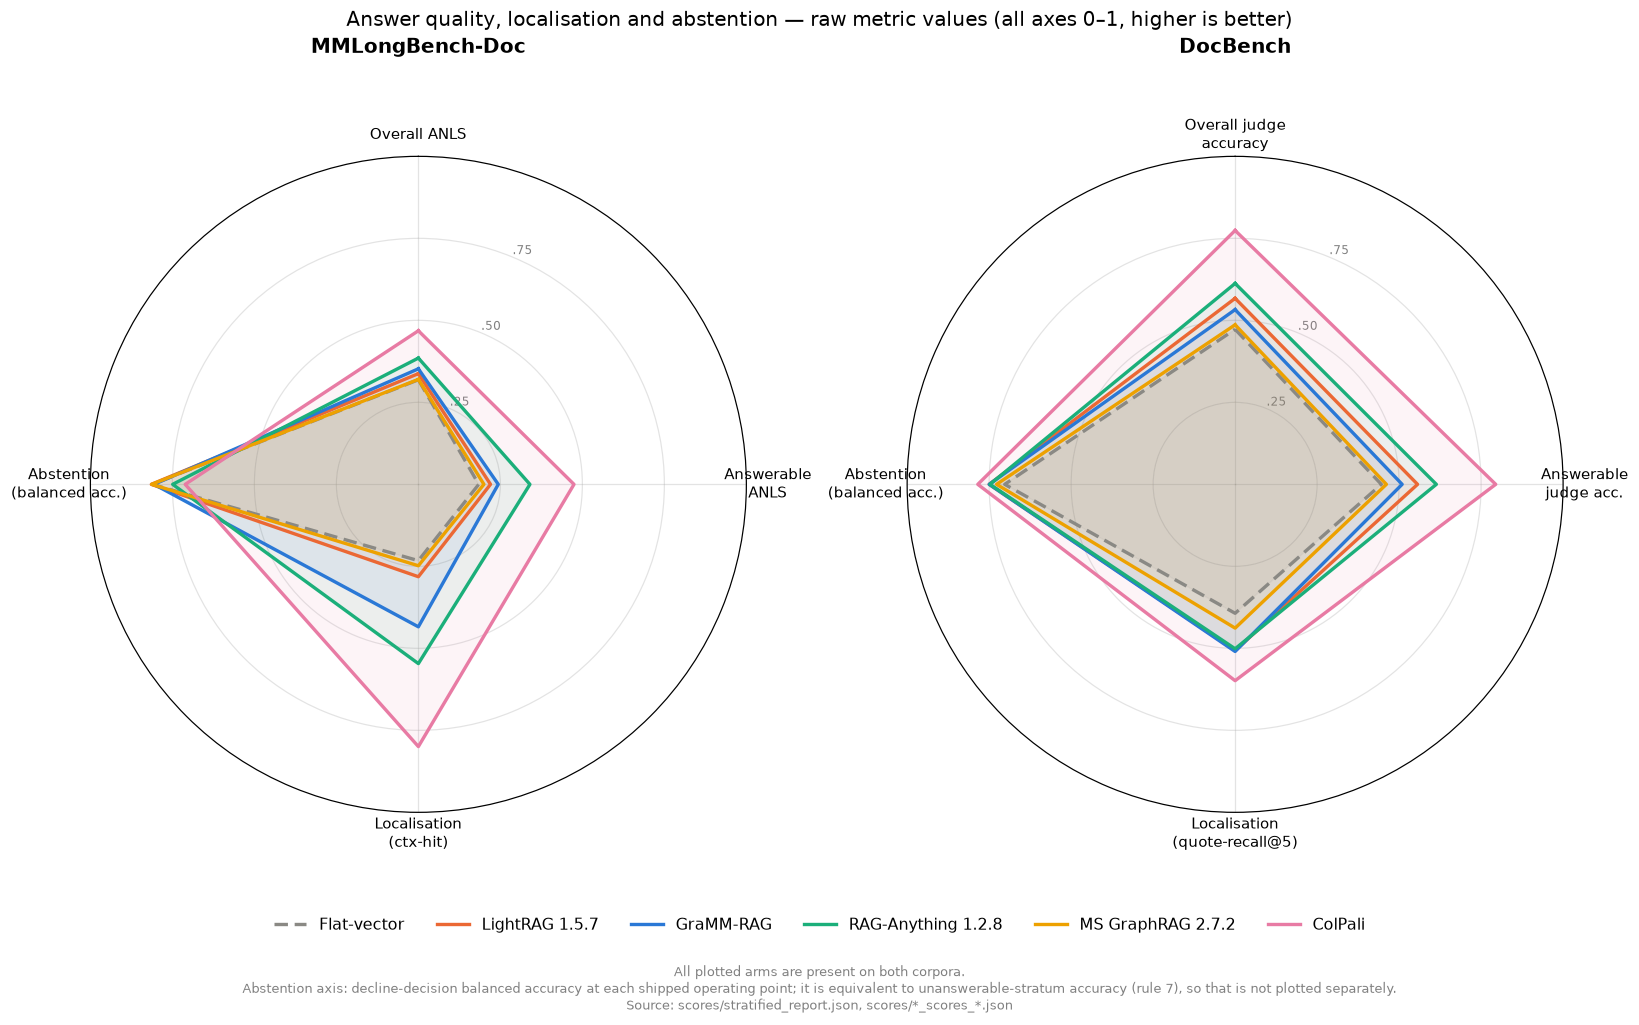

wrote /work/GraphRAG_baseline/figures/fig_radar_quality.png


In [20]:
import numpy as np, matplotlib.pyplot as plt
FIG = Path('/work/GraphRAG_baseline/figures'); FIG.mkdir(parents=True, exist_ok=True)

PLOT = ['Flat-vector', 'LightRAG 1.5.7', 'GraMM-RAG', 'RAG-Anything 1.2.8',
        'MS GraphRAG 2.7.2', 'ColPali']
import collections as _c
# defaultdict, so registering a new arm upstream cannot crash a figure on a
# missing colour -- a palette is presentation, and should never gate a result.
COL  = _c.defaultdict(lambda: '#8a8984', ARM_COL)
PANEL = [('mmlongbench','MMLongBench-Doc',
          ['Overall ANLS','Answerable\nANLS','Localisation\n(ctx-hit)',
           'Abstention\n(balanced acc.)']),
         ('docbench','DocBench',
          ['Overall judge\naccuracy','Answerable\njudge acc.',
           'Localisation\n(quote-recall@5)','Abstention\n(balanced acc.)'])]

fig, axes = plt.subplots(1, 2, figsize=(15, 8), subplot_kw=dict(polar=True))
for ax, (b, title, labels) in zip(axes, PANEL):
    ang = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist()
    ang += ang[:1]
    for s in PLOT:
        if s not in sr[b] or LOC[b].get(s) is None:
            continue                      # absent arm is OMITTED, never imputed
        d = sr[b][s]
        v = [d['pooled'], d['answerable'], LOC[b][s], d['abstention_balanced_acc']]
        v += v[:1]
        ax.plot(ang, v, color=COL[s], lw=2.2, label=s, linestyle=ARM_DASH.get(s, '-'))
        ax.fill(ang, v, color=COL[s], alpha=0.08)
    ax.set_theta_offset(np.pi/2); ax.set_theta_direction(-1)   # match mockup style
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels, fontsize=10)
    ax.set_ylim(0, 1); ax.set_yticks([.25,.5,.75])
    ax.set_yticklabels(['.25','.50','.75'], fontsize=8, color='grey')
    ax.set_title(title, fontsize=13, fontweight='bold', pad=42, y=1.06)
    ax.grid(alpha=.35)
h, l = axes[0].get_legend_handles_labels()
h2, l2 = axes[1].get_legend_handles_labels()
for hh, ll in zip(h2, l2):
    if ll not in l: h.append(hh); l.append(ll)
# ncol tracks the arm count: a fixed 4 wrapped to a second row once a fifth arm
# was registered, and the wrapped row landed on top of the axis labels.
fig.legend(h, l, loc='lower center', ncol=len(l), frameon=False, fontsize=10.5,
           bbox_to_anchor=(0.5, -0.085))
fig.suptitle('Answer quality, localisation and abstention \u2014 raw metric values '
             '(all axes 0\u20131, higher is better)', fontsize=13)
# Caption is DERIVED. The hand-written version said 'LightRAG is absent from
# DocBench' while the DocBench panel was plotting LightRAG -- S1 supplied that arm
# and the sentence was never retired, so the figure contradicted itself in print.
_absent = {b: [s for s in PLOT if s not in sr[b] or LOC[b].get(s) is None]
           for b, _t, _l in PANEL}
_note = ('  '.join(f'{s} is absent from {b} and is omitted, not imputed.'
                   for b, ss in _absent.items() for s in ss)
         or 'All plotted arms are present on both corpora.')
fig.text(0.5, -0.155,
         _note + '\n'
         'Abstention axis: decline-decision balanced accuracy at each shipped operating '
         'point; it is equivalent to unanswerable-stratum accuracy (rule 7), so that is '
         'not plotted separately.\n'
         'Source: scores/stratified_report.json, scores/*_scores_*.json',
         ha='center', fontsize=8.5, color='grey')
plt.tight_layout()
fig.savefig(FIG/'fig_radar_quality.png', dpi=150, bbox_inches='tight')
plt.show()
print('wrote', FIG/'fig_radar_quality.png')

### 10.2 `fig_radar_resource` — measured serving and resource profile
Min-max scaled between the plotted systems (higher = better); raw values in the axis
labels. **Only the two GPU-served systems appear here** -- GraMM and ColPali. LightRAG,
RAG-Anything and MS GraphRAG *were* measured (work order B, 24 cells + the S5
decomposition), but they are API-mediated: 0 A100-hours to prepare and 0 GiB peak query
GPU. On this radar's ratio-to-the-better-system scaling, zero would read as a perfect
score on two axes, when their cost has moved to API spend rather than vanished. That is a
capex/opex trade-off, not dominance, so they get their own figure in section 10.3.

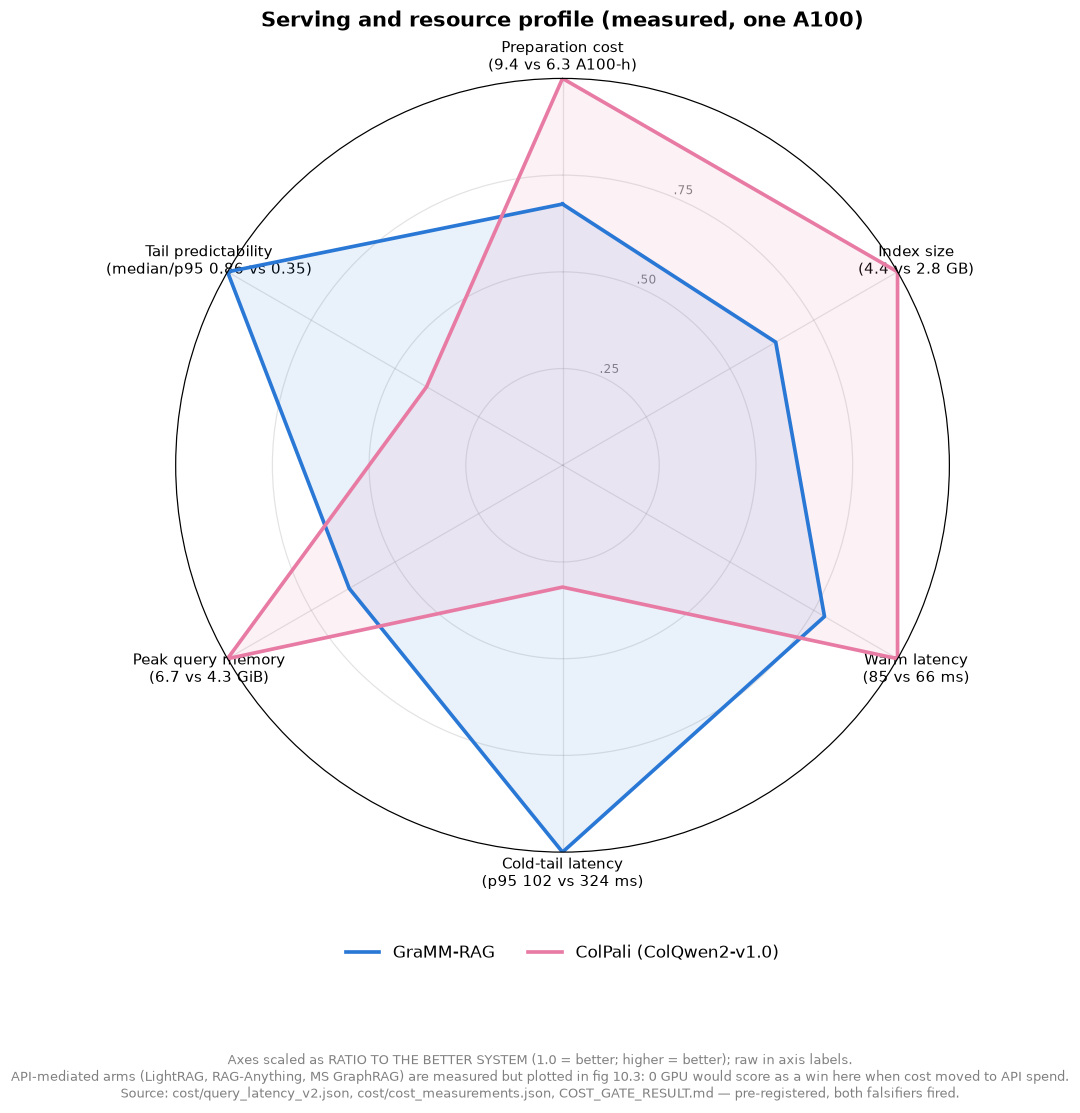

wrote /work/GraphRAG_baseline/figures/fig_radar_resource.png


In [21]:
lat = json.loads(Path('/work/gramm-rag-colpali/cost/query_latency_v2.json').read_text())
cm  = json.loads(Path('/work/gramm-rag-colpali/cost/cost_measurements.json').read_text())
C = lat['cells']
def cell(sys_, b, r): return C[f'{sys_}|{b}|{r}']

# Raw measured values. 'higher is better' is applied by INVERTING cost-like axes, and
# each axis label carries the raw numbers so the scaling cannot hide the direction.
AX = [('Preparation cost',      '9.4 vs 6.3 A100-h',      9.36,  6.32,  False),
      ('Index size',            '4.4 vs 2.8 GB',          4.4,   2.8,   False),
      ('Warm latency',          '%.0f vs %.0f ms' % (cell('gramm','mmlongbench','warm')['median'],
                                                     cell('colpali','mmlongbench','warm')['median']),
       cell('gramm','mmlongbench','warm')['median'],
       cell('colpali','mmlongbench','warm')['median'], False),
      ('Cold-tail latency',     'p95 %.0f vs %.0f ms' % (cell('gramm','mmlongbench','cold')['p95'],
                                                         cell('colpali','mmlongbench','cold')['p95']),
       cell('gramm','mmlongbench','cold')['p95'],
       cell('colpali','mmlongbench','cold')['p95'], False),
      ('Peak query memory',     '%.1f vs %.1f GiB' % (cell('gramm','mmlongbench','cold')['peak_gpu_gib'],
                                                      cell('colpali','mmlongbench','cold')['peak_gpu_gib']),
       cell('gramm','mmlongbench','cold')['peak_gpu_gib'],
       cell('colpali','mmlongbench','cold')['peak_gpu_gib'], False),
      ('Tail predictability',   'median/p95 %.2f vs %.2f' % (
           1/cell('gramm','mmlongbench','cold')['p95_over_median'],
           1/cell('colpali','mmlongbench','cold')['p95_over_median']),
       1/cell('gramm','mmlongbench','cold')['p95_over_median'],
       1/cell('colpali','mmlongbench','cold')['p95_over_median'], True)]

# RATIO-TO-BEST, not min-max. With exactly two systems min-max scaling forces every
# axis to 0 or 1 -- the winner 1, the loser 0, whatever the margin -- so polygon area
# would encode HOW MANY axes a system wins while appearing to encode BY HOW MUCH.
# That is the C-10 defect (a chart whose visual grammar claims more than the data).
# Ratio-to-best keeps the margin visible: 1.0 is the better system, and the other sits
# at its true proportion.
labels, g, c = [], [], []
for name, raw, gv, cv, higher_better in AX:
    labels.append(f'{name}\n({raw})')
    if higher_better:
        best = max(gv, cv); sc = lambda x: x / best if best else 0.0
    else:
        best = min(gv, cv); sc = lambda x: best / x if x else 0.0
    g.append(sc(gv)); c.append(sc(cv))

ang = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist(); ang += ang[:1]
fig, ax = plt.subplots(figsize=(9.5, 9), subplot_kw=dict(polar=True))
for vals, lab, col in ((g,'GraMM-RAG',ARM_COL['GraMM-RAG']), (c,'ColPali (ColQwen2-v1.0)',ARM_COL['ColPali'])):
    v = vals + vals[:1]
    ax.plot(ang, v, color=col, lw=2.4, label=lab); ax.fill(ang, v, color=col, alpha=.10)
ax.set_theta_offset(np.pi/2); ax.set_theta_direction(-1)       # match mockup style
ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels, fontsize=9.5)
ax.set_ylim(0, 1); ax.set_yticks([.25,.5,.75])
ax.set_yticklabels(['.25','.50','.75'], fontsize=8, color='grey'); ax.grid(alpha=.35)
ax.set_title('Serving and resource profile (measured, one A100)',
             fontsize=14, fontweight='bold', pad=34)
# Legend placed BELOW, not right: the style mockup clipped its own legend off the canvas.
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=2,
          frameon=False, fontsize=11)
fig.text(0.5, -0.115,
         'Axes scaled as RATIO TO THE BETTER SYSTEM (1.0 = better; higher = better); raw '
         'in axis labels.\nAPI-mediated arms (LightRAG, RAG-Anything, MS GraphRAG) are measured '
         'but plotted in fig 10.3: 0 GPU would score as a win here when cost moved to API spend.\n'
         'Source: cost/query_latency_v2.json, cost/cost_measurements.json, '
         'COST_GATE_RESULT.md \u2014 pre-registered, both falsifiers fired.',
         ha='center', fontsize=8.5, color='grey')
plt.tight_layout()
fig.savefig(FIG/'fig_radar_resource.png', dpi=150, bbox_inches='tight')
plt.show()
print('wrote', FIG/'fig_radar_resource.png')

### 10.3 `fig_resource_api` — serving profile of the API-mediated arms
Measured in work order B: 3 arms x 2 corpora x {warm, cold} x 2 occurrences (palindrome order,
for drift), n = 500 timed queries per cell, 20 warm-up queries discarded and counted.
**Cold** opens the document's store inside the timed region; **warm** times the query alone.

**MS GraphRAG is shown context-only.** `api.local_search` always generates an answer; the other
two arms expose context-only retrieval. B' timed the generation leg on the same `perf_counter`
clock and subtracted it (two earlier instruments failed -- one over-subtracted across two clocks,
one timed async-generator creation at ~1 ns -- both caught by a physical floor, not a guard).

**Peak query GPU is 0 for all three, structurally** -- the GraphRAG container has no
`/dev/nvidia*` device -- and preparation is 0 A100-hours. Their cost is API spend (opex), which
GraMM and ColPali convert into GPU hours (capex). That is the trade this figure exists to show.

corpus      arm                 state  median s   p95 s  tail   drift  GPU index GiB   $/query
mmlongbench LightRAG 1.5.7      warm      0.246   0.488  1.98  -0.005    0     12.00  7.30e-07
mmlongbench LightRAG 1.5.7      cold      1.811   2.168  1.20  +0.094    0     12.00  7.30e-07
mmlongbench RAG-Anything 1.2.8  warm      0.295   0.528  1.79  -0.005    0      2.32  7.30e-07
mmlongbench RAG-Anything 1.2.8  cold      0.402   1.038  2.58  +0.013    0      2.32  7.30e-07
mmlongbench MS GraphRAG 2.7.2   warm      0.240   0.368  1.53  -0.081    0      3.60  1.37e-03
mmlongbench MS GraphRAG 2.7.2   cold      0.268   0.379  1.42  -0.023    0      3.60  1.37e-03
docbench    LightRAG 1.5.7      warm      0.247   0.391  1.58  +0.019    0      2.68  5.90e-07
docbench    LightRAG 1.5.7      cold      0.346   1.161  3.35  +0.039    0      2.68  5.90e-07
docbench    RAG-Anything 1.2.8  warm      0.251   0.454  1.81  +0.025    0      4.43  5.90e-07
docbench    RAG-Anything 1.2.8  cold      0.370   

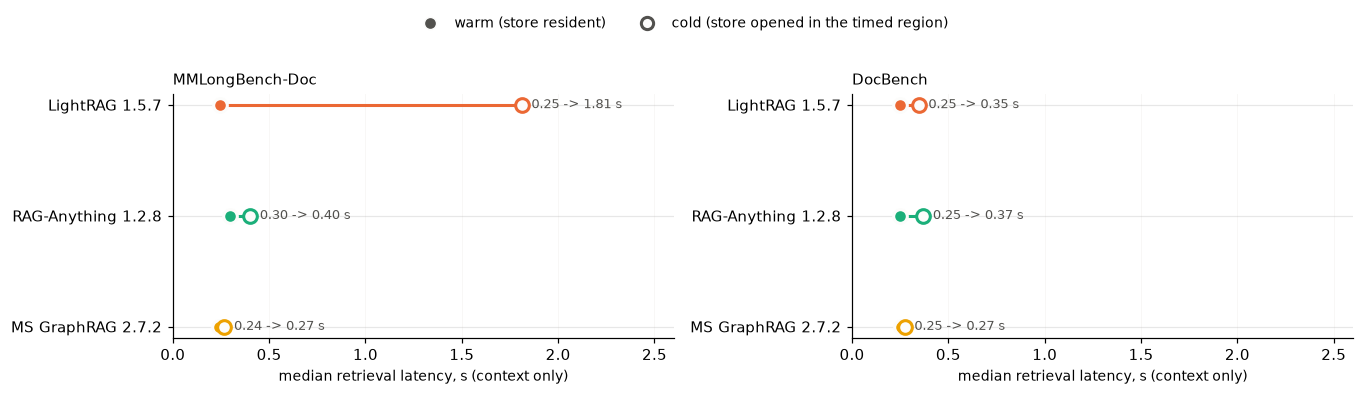

In [22]:
RC = Path('/work/gramm-rag-graphbracket/tier1/_resource_cells')
def cell(arm, b, st, occ=1):
    return json.loads((RC/f'{arm}_{b}_{st}_occ{occ}.json').read_text())
def dec(b, st):
    return json.loads((RC/f'DECOMP_s5_{b}_{st}.json').read_text())
API = [('lightrag','LightRAG 1.5.7'), ('s2','RAG-Anything 1.2.8'), ('s5','MS GraphRAG 2.7.2')]
# Index size is MEASURED HERE, prefix-filtered, not read from the cell JSON: B's first pass summed
# the whole stores/ dir, and RAG-Anything and MS GraphRAG keep both corpora in one dir, so it
# reported the two-corpus total for each (6.74 / 4.87 GiB; actual 2.32 & 4.43 / 3.62 & 1.29).
# ...and it is PRECOMPUTED on vol3 and shipped, not measured at render time. Measuring disk here
# made the package disagree with itself: the stores are excluded as bulk data, an empty glob
# summed to 0.00 GiB, and every index size read zero -- with no error -- in the cold-start test.
_idx = json.loads((Path('/work/gramm-rag-colpali/scores')/'package_precomputed.json')
                  .read_text())['index_gib']              # FileNotFoundError if absent
def idx_gib(arm, b):
    v = _idx[f'{arm}|{b}']                                # KeyError if absent -- never a 0
    assert v > 0, f'index size {arm}/{b} is {v} -- a zero here is missing data, not a small index'
    return v
print(f"{'corpus':12s}{'arm':20s}{'state':6s}{'median s':>9s}{'p95 s':>8s}{'tail':>6s}"
      f"{'drift':>8s}{'GPU':>5s}{'index GiB':>10s}{'$/query':>10s}")
rows = {}
for b in ('mmlongbench','docbench'):
    for arm, lab in API:
        for st in ('warm','cold'):
            c1, c2 = cell(arm,b,st,1), cell(arm,b,st,2)
            if arm == 's5':                     # context-only, single-clock (B')
                d = dec(b, st); med, p95 = d['context_only_median_s'], d['context_only_p95_s']
            else:
                med, p95 = c1['median_s'], c1['p95_s']
            drift = c2['median_s'] - c1['median_s']       # palindrome occurrence 2 - 1
            rows[(b, lab, st)] = (med, p95)
            gib = idx_gib(arm, b)
            print(f"{b:12s}{lab:20s}{st:6s}{med:>9.3f}{p95:>8.3f}{p95/med:>6.2f}{drift:>+8.3f}"
                  f"{'0':>5s}{gib:>10.2f}{c1['api_cost_per_query_usd']:>10.2e}")
print('\n$/query for LightRAG and RAG-Anything is EMBEDDING-ONLY (~7e-07): their on-disk LLM')
print('response cache, populated by the accuracy runs, absorbed keyword extraction (llm_calls = 0).')
print('These are cache-warm service costs, not first-query costs -- a cold cache would add LLM calls.')
print('MS GraphRAG rows are CONTEXT-ONLY (generation subtracted on one clock); its tail is an')
print('upper bound. drift = occurrence 2 minus occurrence 1 on the same cell (OpenAI-side load).')

# Dumbbell: the job is 'what does each arm pay for a cold start' -- one row per arm, warm
# (filled) to cold (open), colour follows the arm. One panel per corpus; latency only, so one axis.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.4), sharex=True)
for ax, b, title in ((axes[0],'mmlongbench','MMLongBench-Doc'), (axes[1],'docbench','DocBench')):
    for yi, (arm, lab) in enumerate(API):
        w, c = rows[(b, lab, 'warm')][0], rows[(b, lab, 'cold')][0]
        col = ARM_COL[lab]
        ax.plot([w, c], [yi, yi], color=col, linewidth=2, zorder=2)
        ax.scatter([w], [yi], s=80, color=col, edgecolor='#fcfcfb', linewidth=2, zorder=3)
        ax.scatter([c], [yi], s=80, facecolor='#fcfcfb', edgecolor=col, linewidth=2, zorder=3)
        ax.text(max(w, c) + 0.05, yi, f'{w:.2f} -> {c:.2f} s', va='center', fontsize=8.5,
                color='#52514e')
    ax.set_yticks(range(len(API))); ax.set_yticklabels([l for _, l in API])
    ax.set_title(title, fontsize=10, loc='left'); ax.invert_yaxis()
    ax.grid(axis='x', color='#e6e5e0', linewidth=0.6); ax.set_axisbelow(True)
    for sp in ('top','right'): ax.spines[sp].set_visible(False)
    ax.set_xlabel('median retrieval latency, s (context only)', fontsize=9)
axes[0].set_xlim(0, 2.6)
from matplotlib.lines import Line2D
fig.legend([Line2D([],[],ls='none',marker='o',ms=8,mfc='#52514e',mec='#fcfcfb'),
            Line2D([],[],ls='none',marker='o',ms=8,mfc='#fcfcfb',mec='#52514e',mew=2)],
           ['warm (store resident)', 'cold (store opened in the timed region)'],
           loc='upper center', ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.savefig(FIG/'fig_resource_api.png', bbox_inches='tight'); plt.show()

## 11. ctx-hit vs answer quality vs abstention — every system, both benchmarks

Three questions that one chart cannot answer together, so three charts:

| figure | question |
|---|---|
| `fig_metric_comparison` | what does each system score on each metric? |
| `fig_conversion_frontier` | does better localisation *become* better answers? |
| `fig_stratum_tradeoff` | what is each system's answerable/unanswerable operating point? |

The third is the one that decides whether GraMM's position is a deficit or a different
operating point, and it is not visible in any pooled number.

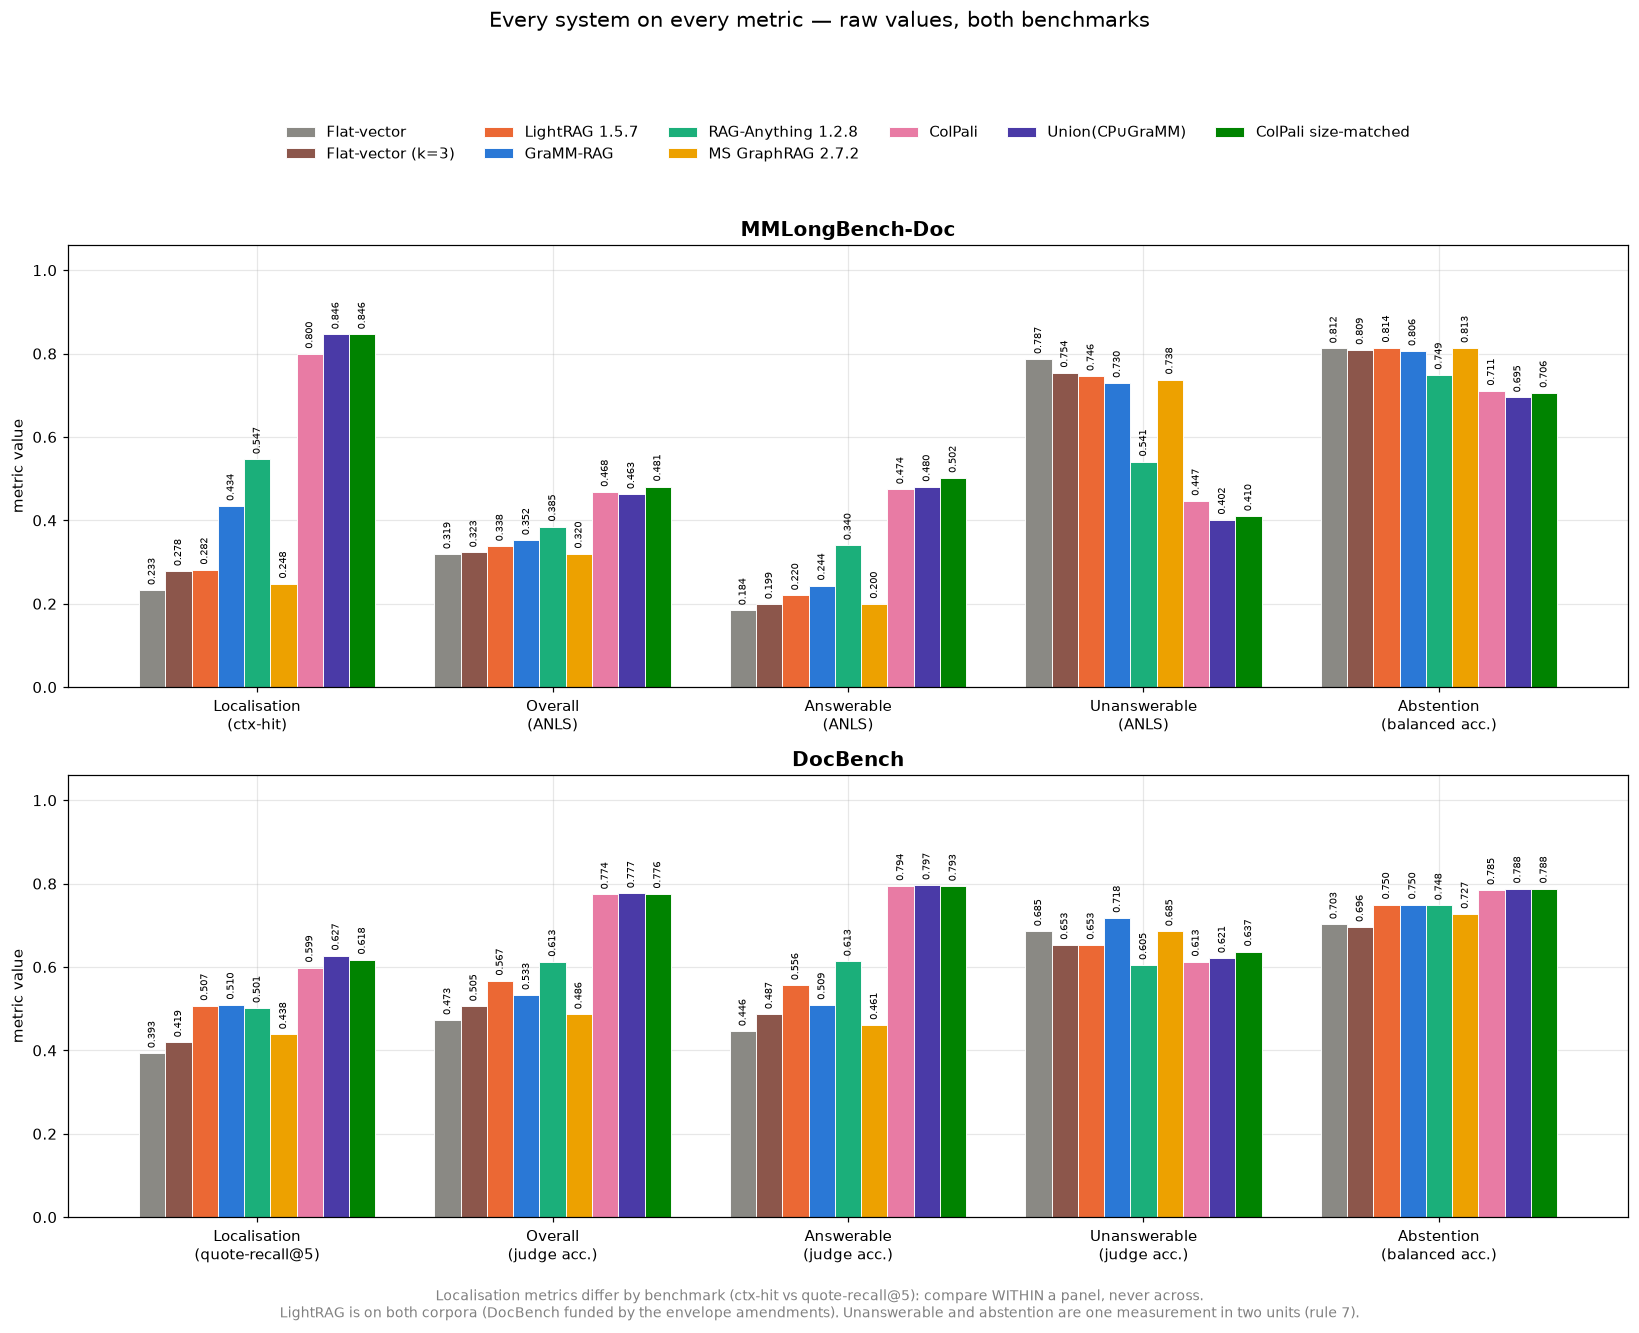

wrote /work/GraphRAG_baseline/figures/fig_metric_comparison.png


In [23]:
SYS = ['Flat-vector','Flat-vector (k=3)','LightRAG 1.5.7','GraMM-RAG','RAG-Anything 1.2.8',
       'MS GraphRAG 2.7.2','ColPali','Union(CP\u222aGraMM)','ColPali size-matched']
import collections as _c
CC  = _c.defaultdict(lambda: '#8c564b',
      ARM_COL)
BEN = [('mmlongbench','MMLongBench-Doc','ctx-hit','ANLS'),
       ('docbench','DocBench','quote-recall@5','judge acc.')]

fig, axes = plt.subplots(2, 1, figsize=(15, 11))
for ax, (b, title, locname, qname) in zip(axes, BEN):
    present = [s for s in SYS if s in sr[b] and LOC[b].get(s) is not None]
    metrics = [(f'Localisation\n({locname})', lambda s,b=b: LOC[b][s]),
               (f'Overall\n({qname})',        lambda s,b=b: sr[b][s]['pooled']),
               (f'Answerable\n({qname})',     lambda s,b=b: sr[b][s]['answerable']),
               (f'Unanswerable\n({qname})',   lambda s,b=b: sr[b][s]['unanswerable']),
               ('Abstention\n(balanced acc.)',lambda s,b=b: sr[b][s]['abstention_balanced_acc'])]
    x = np.arange(len(metrics)); w = 0.8/len(present)
    for i, s in enumerate(present):
        vals = [f(s) for _, f in metrics]
        bars = ax.bar(x + i*w - 0.4 + w/2, vals, w, label=s, color=CC[s],
                      edgecolor='white', linewidth=0.6)
        for bb, v in zip(bars, vals):
            ax.text(bb.get_x()+bb.get_width()/2, v+0.012, f'{v:.3f}',
                    ha='center', va='bottom', fontsize=6.6, rotation=90)
    ax.set_xticks(x); ax.set_xticklabels([m for m,_ in metrics], fontsize=10)
    ax.set_ylim(0, 1.06); ax.set_ylabel('metric value'); ax.grid(axis='y', alpha=.3)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_axisbelow(True)
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, 1.30), ncol=6,
               frameon=False, fontsize=9.5)
fig.suptitle('Every system on every metric \u2014 raw values, both benchmarks',
             fontsize=14, y=1.05)
fig.text(0.5, -0.03,
         'Localisation metrics differ by benchmark (ctx-hit vs quote-recall@5): compare '
         'WITHIN a panel, never across.\nLightRAG is on both corpora (DocBench funded by the envelope amendments). '
         'Unanswerable and abstention are one measurement in two units (rule 7).',
         ha='center', fontsize=9, color='grey')
plt.tight_layout()
fig.savefig(FIG/'fig_metric_comparison.png', dpi=150, bbox_inches='tight')
plt.show(); print('wrote', FIG/'fig_metric_comparison.png')

### 11.1 `fig_conversion_frontier` — does localisation become answer quality?

x = localisation, y = pooled answer quality. The **dashed** line joins the page-matched
control to the best-localising system that exists **outside this project**; the **dotted**
line joins it to the best-localising arm overall, which is one we built (Union or ColPali
size-matched). Anchoring only on the derived arm would define the conversion rate every
system is read against by a hybrid nobody ships, so both are drawn and named. A system
**above** a line converts better than that trend; **below**, worse.

Conversion efficiency is reported as **eta = dQuality / dLocalisation** against the
**page-matched** flat-vector control (k=3, C-80). It is a ratio of two noisy differences
with no CI, so it is read as a descriptive slope, not a test. The archived k=2 control is
still plotted as its own point: the gap between the two control points is the page budget,
and no eta measured against the k=2 arm is quotable.

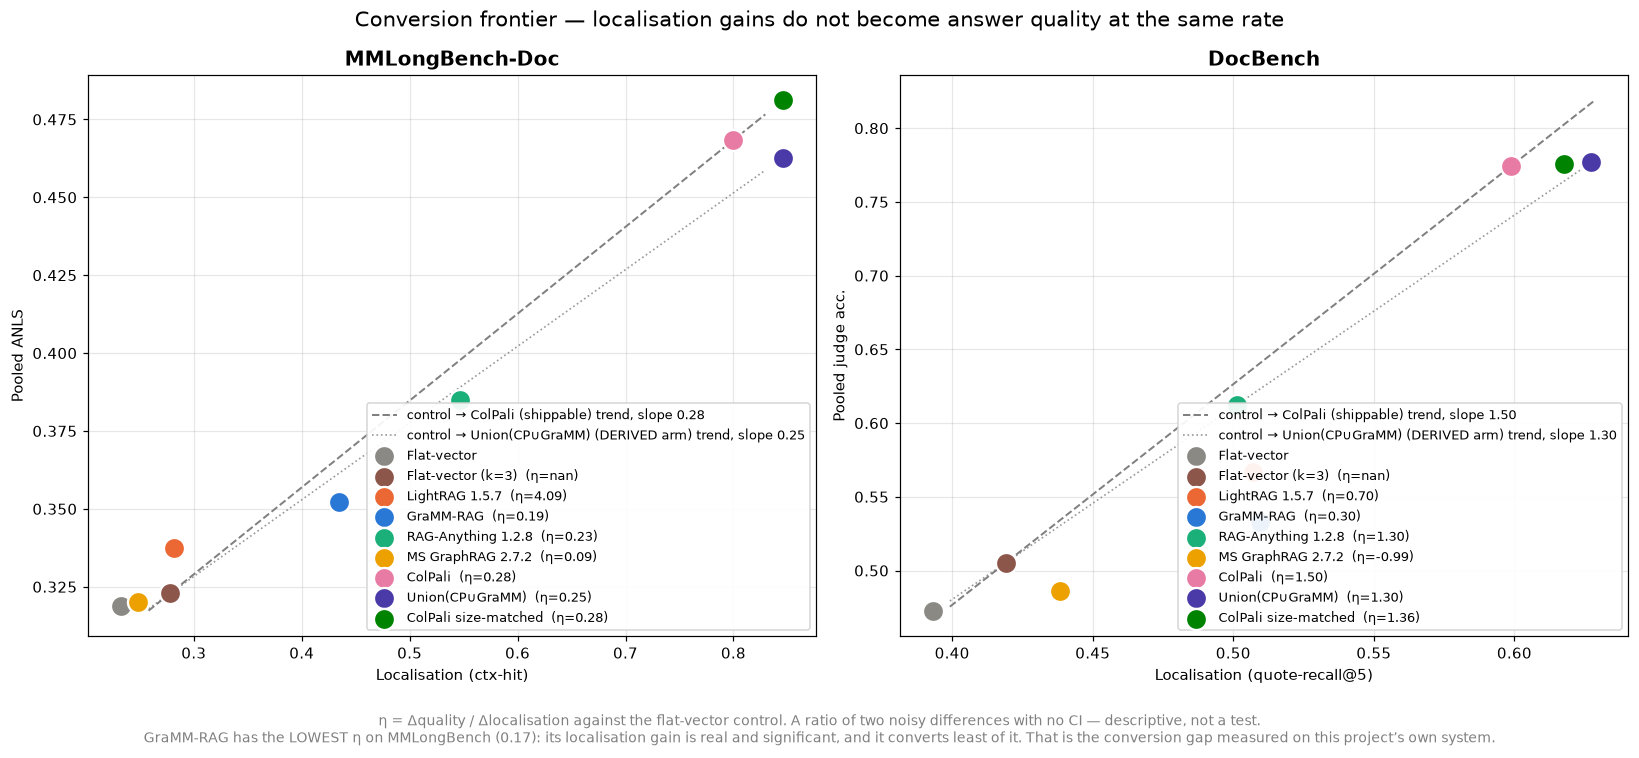

eta is measured against the PAGE-MATCHED control (Flat-vector (k=3)) -- C-80. No eta against the k=2 control is quotable.
benchmark     system                    dLoc   dQual     eta    resid
mmlongbench   Flat-vector (k=3)       0.0000  0.0000     nan  +0.0000
mmlongbench   LightRAG 1.5.7          0.0036  0.0146   4.092  +0.0137
mmlongbench   GraMM-RAG               0.1563  0.0293   0.188  -0.0142
mmlongbench   RAG-Anything 1.2.8      0.2685  0.0621   0.231  -0.0127
mmlongbench   MS GraphRAG 2.7.2      -0.0298 -0.0028   0.094  +0.0055
mmlongbench   ColPali                 0.5215  0.1453   0.279  +0.0000
mmlongbench   Union(CP∪GraMM)         0.5680  0.1399   0.246  -0.0185
mmlongbench   ColPali size-matched    0.5680  0.1582   0.279  -0.0001
docbench      Flat-vector (k=3)       0.0000  0.0000     nan  +0.0000
docbench      LightRAG 1.5.7          0.0877  0.0617   0.704  -0.0695
docbench      GraMM-RAG               0.0904  0.0272   0.301  -0.1081
docbench      RAG-Anything 1.2.8      

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
eta_tbl = {}
for ax, (b, title, locname, qname) in zip(axes, BEN):
    present = [s for s in SYS if s in sr[b] and LOC[b].get(s) is not None]
    # C-80: the control is the PAGE-MATCHED arm. Anchoring the frontier on the k=2 arm
    # made every eta a mix of retrieval quality and a one-page context advantage.
    CONTROL = 'Flat-vector (k=3)' if 'Flat-vector (k=3)' in sr[b] else 'Flat-vector'
    bl_x, bl_y = LOC[b][CONTROL], sr[b][CONTROL]['pooled']
    # The best-LOCALISING arm is Union or ColPali size-matched -- both built in this project.
    # A conversion rate anchored on them is a rate nobody can ship, so the trend that carries
    # weight is anchored on the best arm that exists outside this project, and the derived
    # arm's trend is drawn beside it and named.
    DERIVED = {'Union(CP\u222aGraMM)', 'ColPali size-matched'}
    best = max([s for s in present if s not in DERIVED and s != CONTROL], key=lambda s: LOC[b][s])
    best_any = max([s for s in present if s != CONTROL], key=lambda s: LOC[b][s])
    bx, by = LOC[b][best], sr[b][best]['pooled']
    slope = (by-bl_y)/(bx-bl_x)
    xs = np.linspace(bl_x-0.02, bx+0.03, 50)
    ax.plot(xs, bl_y + slope*(xs-bl_x), '--', color='grey', lw=1.3, zorder=1,
            label=f'control \u2192 {best} (shippable) trend, slope {slope:.2f}')
    if best_any != best:
        _s2 = (sr[b][best_any]['pooled']-bl_y)/(LOC[b][best_any]-bl_x)
        ax.plot(xs, bl_y + _s2*(xs-bl_x), ':', color='grey', lw=1.1, alpha=.8, zorder=1,
                label=f'control \u2192 {best_any} (DERIVED arm) trend, slope {_s2:.2f}')
    for s in present:
        x_, y_ = LOC[b][s], sr[b][s]['pooled']
        ax.scatter([x_], [y_], s=190, color=CC[s], zorder=3,
                   edgecolor='white', linewidth=1.5, label=s)
        resid = y_ - (bl_y + slope*(x_-bl_x))
        dl, dq = x_-bl_x, y_-bl_y
        eta = dq/dl if abs(dl) > 1e-9 else float('nan')
        eta_tbl.setdefault(b, {})[s] = (dl, dq, eta, resid)
        # Only the eta value is annotated: full system names collided three-deep on
        # DocBench, where ColPali, its size-matched control and the union arm sit
        # within 0.03 of each other. Names go in the legend.
        # eta labels STILL collided after names were moved out: on DocBench ColPali, its
        # size-matched control and Union sit within 0.03, and no text placement fits three
        # labels there. eta moves into each legend entry, which cannot collide.
        if s != 'Flat-vector':
            ax.collections[-1].set_label(f'{s}  (\u03b7={eta:.2f})')
    ax.set_xlabel(f'Localisation ({locname})'); ax.set_ylabel(f'Pooled {qname}')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.grid(alpha=.3); ax.set_axisbelow(True)
    ax.legend(fontsize=8.2, loc='lower right', frameon=True, framealpha=.92,
              edgecolor='lightgrey')
fig.suptitle('Conversion frontier \u2014 localisation gains do not become answer quality '
             'at the same rate', fontsize=14)
fig.text(0.5, -0.06,
         '\u03b7 = \u0394quality / \u0394localisation against the flat-vector control. '
         'A ratio of two noisy differences with no CI \u2014 descriptive, not a test.\n'
         'GraMM-RAG has the LOWEST \u03b7 on MMLongBench (0.17): its localisation gain is '
         'real and significant, and it converts least of it. That is the conversion gap '
         'measured on this project\u2019s own system.',
         ha='center', fontsize=9, color='grey')
plt.tight_layout()
fig.savefig(FIG/'fig_conversion_frontier.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'eta is measured against the PAGE-MATCHED control ({CONTROL}) -- C-80. No eta against'
      ' the k=2 control is quotable.')
print(f"{'benchmark':14s}{'system':22s}{'dLoc':>8s}{'dQual':>8s}{'eta':>8s}{'resid':>9s}")
for b in eta_tbl:
    for s,(dl,dq,e,r) in eta_tbl[b].items():
        if s=='Flat-vector': continue
        print(f'{b:14s}{s:22s}{dl:>8.4f}{dq:>8.4f}{e:>8.3f}{r:>+9.4f}')

### 11.2 `fig_stratum_tradeoff` — the operating point, and why the pooled number misleads

x = accuracy on **answerable** questions, y = accuracy on **unanswerable** ones. Pooled
quality collapses these into one number and hides that the systems sit at genuinely
different operating points. Points on the upper-right frontier are undominated.

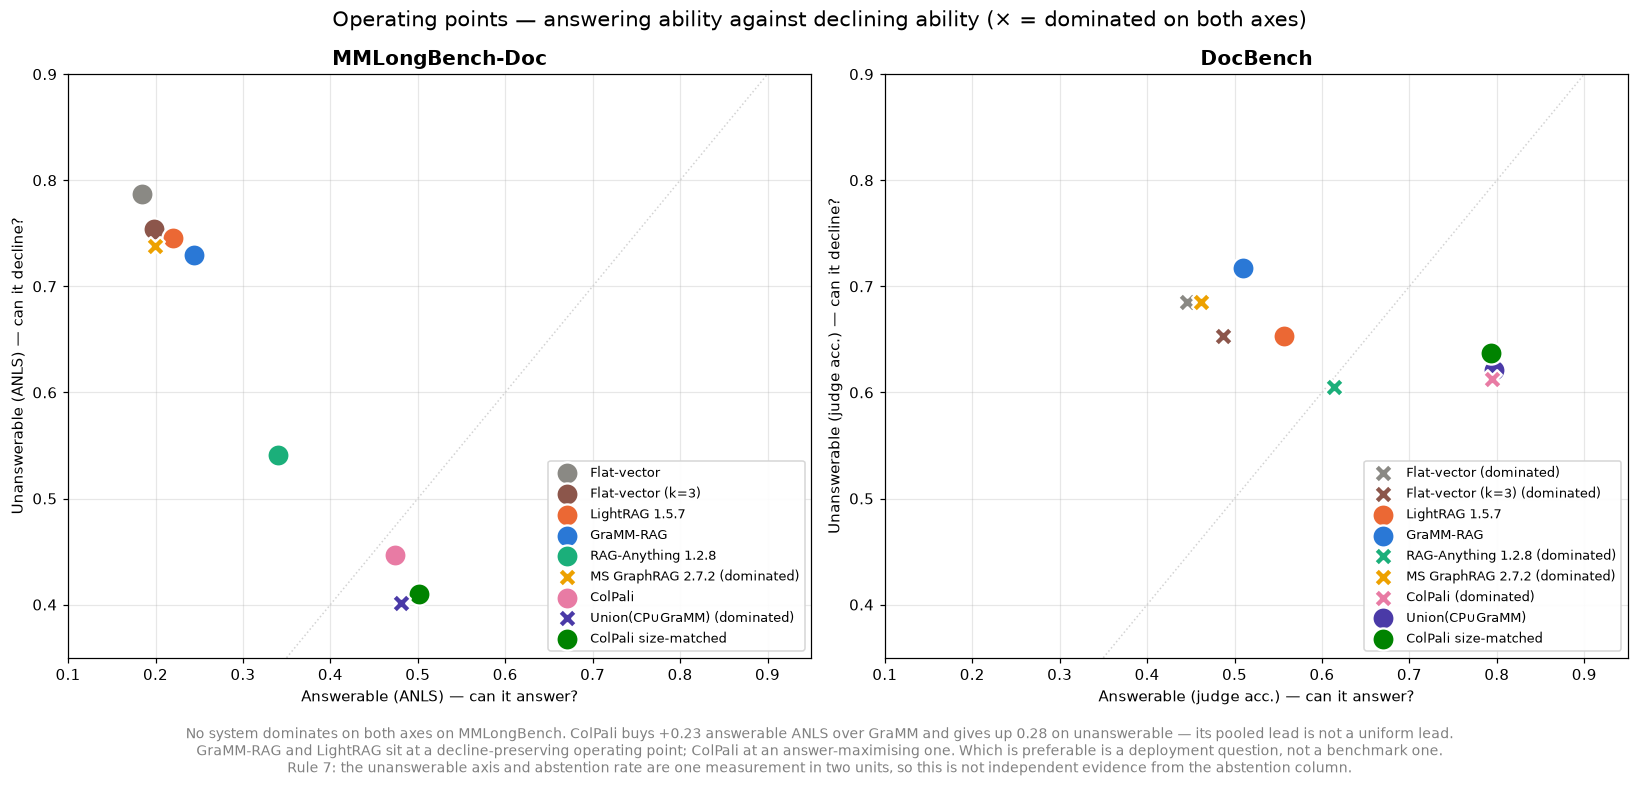

wrote /work/GraphRAG_baseline/figures/fig_stratum_tradeoff.png


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.6))
for ax, (b, title, locname, qname) in zip(axes, BEN):
    present = [s for s in SYS if s in sr[b]]
    pts = {s: (sr[b][s]['answerable'], sr[b][s]['unanswerable']) for s in present}
    for s,(x_,y_) in pts.items():
        dominated = any(pts[o][0] > x_ and pts[o][1] > y_ for o in pts if o != s)
        # Per-point text collided badly (three ColPali variants sit within 0.01 of each
        # other on DocBench). Identify by legend instead; exact values are in the joint
        # table and in fig_metric_comparison.
        # On DocBench ColPali's dominated X sat fully under Union's circle at ~(0.797, 0.62).
        # Dominated markers draw on top and slightly smaller, so both remain visible.
        ax.scatter([x_], [y_], s=150 if dominated else 210, color=CC[s],
                   zorder=4 if dominated else 3, edgecolor='white', lw=1.5,
                   marker='o' if not dominated else 'X',
                   label=f"{s}{' (dominated)' if dominated else ''}")
    lim = [0, 1]
    ax.plot(lim, lim, ':', color='lightgrey', lw=1, zorder=1)
    ax.set_xlim(0.10, 0.95); ax.set_ylim(0.35, 0.90)
    ax.set_xlabel(f'Answerable ({qname}) \u2014 can it answer?')
    ax.set_ylabel(f'Unanswerable ({qname}) \u2014 can it decline?')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.grid(alpha=.3); ax.set_axisbelow(True)
    ax.legend(fontsize=8.6, loc='lower right', frameon=True, framealpha=.92,
              edgecolor='lightgrey')
fig.suptitle('Operating points \u2014 answering ability against declining ability '
             '(\u00d7 = dominated on both axes)', fontsize=14)
fig.text(0.5, -0.07,
         'No system dominates on both axes on MMLongBench. ColPali buys +0.23 answerable '
         'ANLS over GraMM and gives up 0.28 on unanswerable \u2014 its pooled lead is not '
         'a uniform lead.\nGraMM-RAG and LightRAG sit at a decline-preserving operating '
         'point; ColPali at an answer-maximising one. Which is preferable is a deployment '
         'question, not a benchmark one.\n'
         'Rule 7: the unanswerable axis and abstention rate are one measurement in two '
         'units, so this is not independent evidence from the abstention column.',
         ha='center', fontsize=9, color='grey')
plt.tight_layout()
fig.savefig(FIG/'fig_stratum_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show(); print('wrote', FIG/'fig_stratum_tradeoff.png')

In [26]:
print('=== worst-case abstention quality across corpora (systems on BOTH) ===')
print(f"{'system':24s}{'MMLB':>8s}{'DocB':>8s}{'min':>8s}{'spread':>9s}")
rows = []
for s in sr['mmlongbench']:
    if s in sr['docbench']:
        a = sr['mmlongbench'][s]['abstention_balanced_acc']
        d = sr['docbench'][s]['abstention_balanced_acc']
        rows.append((s, a, d, min(a,d), abs(a-d)))
for s,a,d,m,sp in sorted(rows, key=lambda r: -r[3]):
    print(f'{s:24s}{a:>8.3f}{d:>8.3f}{m:>8.3f}{sp:>9.3f}')
best = max(rows, key=lambda r: r[3])
tight = min(rows, key=lambda r: r[4])
print(f"\nhighest minimum: {best[0]} ({best[3]:.3f})   smallest spread: "
      f'{tight[0]} ({tight[4]:.3f})')
print('LightRAG is excluded here: no DocBench arm (Gate G). Its MMLongBench balAcc'
      ' (0.814) is the highest single value on that corpus, so this claim is'
      ' conditioned on the systems that have both corpora -- an absence of data,'
      ' not a result.')

=== worst-case abstention quality across corpora (systems on BOTH) ===
system                      MMLB    DocB     min   spread
GraMM-RAG                  0.806   0.750   0.750    0.056
LightRAG 1.5.7             0.814   0.750   0.750    0.064
RAG-Anything 1.2.8         0.749   0.748   0.748    0.001
MS GraphRAG 2.7.2          0.813   0.727   0.727    0.086
ColPali                    0.711   0.785   0.711    0.074
ColPali size-matched       0.706   0.788   0.706    0.083
Flat-vector                0.812   0.703   0.703    0.110
Flat-vector (k=3)          0.809   0.696   0.696    0.113
Union(CP∪GraMM)            0.695   0.788   0.695    0.093

highest minimum: GraMM-RAG (0.750)   smallest spread: RAG-Anything 1.2.8 (0.001)
LightRAG is excluded here: no DocBench arm (Gate G). Its MMLongBench balAcc (0.814) is the highest single value on that corpus, so this claim is conditioned on the systems that have both corpora -- an absence of data, not a result.


## 12. Gate A's stratification, applied to every system (dimension A)

> **EXPLORATORY. Firewalled from Gate A.**
>
> **Gate A was a pre-registered test and it FAILED.** The hypothesis that GraMM’s
> advantage concentrates on cross-page questions is falsified and stays falsified:
> interaction −0.0245, CI [−0.0687, +0.0216]. Nothing below revises that.
>
> This section is **post-hoc stratification across arms**: not pre-registered, five
> interaction tests, no correction planned in advance. It is reported as an exploratory
> finding requiring independent confirmation, **not** as a re-test of the falsified
> hypothesis. Re-analysing a failed pre-registration until something reaches significance
> is precisely the move this protocol exists to prevent, and an examiner will look for it
> here because the chapter teaches them to. The firewall is therefore stated before the
> numbers, not after them.

Gate A pre-registered the hypothesis that GraMM's advantage **concentrates on cross-page**
questions, and **falsified** it: the interaction (\u0394_cross \u2212 \u0394_single) was
\u22120.0245, CI [\u22120.0687, +0.0216].

That was a claim about **one system**. Re-running the same stratification across every arm
asks a strictly stronger question: **is cross-page concentration absent for retrieval as a
class, or only for GraMM?** If every arm shows a null interaction, the finding generalises
well beyond this project's system. Costs nothing new \u2014 it re-stratifies predictions
already paid for.

Strata are the archived Gate A definitions: single-page (`len(gold_pages)==1`, answerable),
cross-page (`len(gold_pages)>1`, answerable), and the 9 answerable rows with empty
`gold_pages` kept visible as the R1 anomaly, never folded in.

In [27]:
gold_pages = base['gold_pages']
single = [i for i in range(len(gold_pages)) if ans[i] and len(gold_pages[i]) == 1]
cross  = [i for i in range(len(gold_pages)) if ans[i] and len(gold_pages[i]) > 1]
anom   = [i for i in range(len(gold_pages)) if ans[i] and len(gold_pages[i]) == 0]
unans  = [i for i in range(len(gold_pages)) if not ans[i]]
print(f'strata: single {len(single)}  cross {len(cross)}  unanswerable {len(unans)}  '
      f'R1-anomaly {len(anom)}  total {len(single)+len(cross)+len(unans)+len(anom)}')
assert len(single)+len(cross)+len(unans)+len(anom) == 1091
assert (len(single), len(cross), len(unans), len(anom)) == (478, 360, 244, 9), \
       'Gate A strata drifted from the archived definition'
print('strata reproduce the archived Gate A counts exactly (478/360/244/9)')

strata: single 478  cross 360  unanswerable 244  R1-anomaly 9  total 1091
strata reproduce the archived Gate A counts exactly (478/360/244/9)


In [28]:
# Interaction test, per system, against the flat-vector control:
#   delta_stratum = mean(system) - mean(control) on that stratum
#   interaction   = delta_cross - delta_single, bootstrapped on the PAIRED differences
# Two separately-computed CIs cannot establish concentration -- overlapping CIs are not a
# difference test. This is the same interaction machinery Gate A used (C-17).
rng2 = np.random.default_rng(42)
def interaction(sys_scores, ctl_scores, idx_a, idx_b, n=2000):
    da = sys_scores[idx_a] - ctl_scores[idx_a]
    db = sys_scores[idx_b] - ctl_scores[idx_b]
    obs = db.mean() - da.mean()
    bs = np.empty(n)
    for k in range(n):
        ia = rng2.integers(0, len(da), len(da)); ib = rng2.integers(0, len(db), len(db))
        bs[k] = db[ib].mean() - da[ia].mean()
    return obs, np.percentile(bs, 2.5), np.percentile(bs, 97.5)

# Section 9 built S over three arms only, so the first run of this cell silently tested
# two systems and reported a class-level verdict. Rebuild S over EVERY arm that has
# predictions, and assert the count, so a missing arm fails loudly instead of narrowing
# the claim in silence.
for arm, lab in (('colpali','ColPali'), ('union','Union(CP∪GraMM)'),
                 ('colpali_matched','ColPali size-matched'),
                 ('lightrag','LightRAG 1.5.7'), ('s2','RAG-Anything 1.2.8'),
                 ('s5','MS GraphRAG 2.7.2'), ('flatk3','Flat-vector (k=3)')):
    f = GEN/f'{arm}_gen_mmlongbench.json'
    if f.exists() and lab not in S:
        pr = json.loads(f.read_text())['predictions']
        S[lab] = np.array([anls_score(pp, tt) for pp, tt in zip(pr, golds)])
expected = {s for s in SYS if s in sr['mmlongbench']}
missing = expected - set(S)
assert not missing, f'arms missing from the Gate A stratification: {missing}'
print(f'systems entering the stratification: {len(S)}  {sorted(S)}')

ctl = S['Flat-vector']
SA = np.array(single); CA = np.array(cross)
print(f"{'system':22s}{'single':>9s}{'cross':>9s}{'d_single':>10s}{'d_cross':>10s}"
      f"{'interaction (cross-single)':>30s}")
gate_a_rows = {}
for s, v in S.items():
    if s == 'Flat-vector':
        print(f'{s:22s}{v[SA].mean():>9.4f}{v[CA].mean():>9.4f}{"--":>10s}{"--":>10s}'
              f'{"(control)":>30s}')
        continue
    ds = (v[SA] - ctl[SA]).mean(); dc = (v[CA] - ctl[CA]).mean()
    obs, lo, hi = interaction(v, ctl, SA, CA)
    sig = '*' if (lo > 0 or hi < 0) else ' '
    gate_a_rows[s] = (v[SA].mean(), v[CA].mean(), ds, dc, obs, lo, hi, sig == '*')
    print(f'{s:22s}{v[SA].mean():>9.4f}{v[CA].mean():>9.4f}{ds:>+10.4f}{dc:>+10.4f}'
          f'{obs:>+12.4f} [{lo:+.4f},{hi:+.4f}]{sig}')
print('\n* = 95% CI excludes zero (advantage concentrates on one stratum)')
print('\nGate A archived result for GraMM-RAG: -0.0245 [-0.0687, +0.0216] -- NOT SUPPORTED')

systems entering the stratification: 9  ['ColPali', 'ColPali size-matched', 'Flat-vector', 'Flat-vector (k=3)', 'GraMM-RAG', 'LightRAG 1.5.7', 'MS GraphRAG 2.7.2', 'RAG-Anything 1.2.8', 'Union(CP∪GraMM)']
system                   single    cross  d_single   d_cross    interaction (cross-single)
Flat-vector              0.2248   0.1243        --        --                     (control)
GraMM-RAG                0.2963   0.1713   +0.0714   +0.0470     -0.0245 [-0.0693,+0.0211] 
LightRAG 1.5.7           0.2585   0.1625   +0.0337   +0.0381     +0.0045 [-0.0550,+0.0627] 
ColPali                  0.6107   0.2952   +0.3859   +0.1709     -0.2150 [-0.2826,-0.1495]*
Union(CP∪GraMM)          0.6106   0.3077   +0.3858   +0.1834     -0.2024 [-0.2690,-0.1407]*


ColPali size-matched     0.6267   0.3365   +0.4019   +0.2122     -0.1897 [-0.2581,-0.1220]*
RAG-Anything 1.2.8       0.4394   0.2037   +0.2146   +0.0793     -0.1353 [-0.2033,-0.0721]*
MS GraphRAG 2.7.2        0.2408   0.1403   +0.0159   +0.0159     -0.0000 [-0.0561,+0.0600] 
Flat-vector (k=3)        0.2395   0.1393   +0.0147   +0.0150     +0.0003 [-0.0328,+0.0332] 

* = 95% CI excludes zero (advantage concentrates on one stratum)

Gate A archived result for GraMM-RAG: -0.0245 [-0.0687, +0.0216] -- NOT SUPPORTED


### 12.1 Multiplicity — five tests, no pre-planned correction

In [29]:
# Five interaction tests were run with no correction planned in advance, so the nominal
# 95% CIs overstate confidence. Bonferroni at alpha=0.05 over 5 tests -> 99% CIs.
# Computed rather than asserted: the claim 'survives correction' is itself a claim.
alpha_adj = 0.05/len(gate_a_rows)
lo_pct, hi_pct = 100*alpha_adj/2, 100*(1-alpha_adj/2)
print(f'Bonferroni over {len(gate_a_rows)} tests: alpha {alpha_adj:.4f} '
      f'-> {100-100*alpha_adj:.1f}% CIs\n')
print(f"{'system':22s}{'interaction':>13s}{'95% CI':>22s}{'corrected CI':>24s}{'holds':>7s}")
for s in gate_a_rows:
    da = S[s][SA] - ctl[SA]; db = S[s][CA] - ctl[CA]
    bs = np.empty(4000)
    for k in range(4000):
        ia = rng2.integers(0, len(da), len(da)); ib = rng2.integers(0, len(db), len(db))
        bs[k] = db[ib].mean() - da[ia].mean()
    obs = db.mean() - da.mean()
    l95, h95 = np.percentile(bs, [2.5, 97.5])
    lc, hc = np.percentile(bs, [lo_pct, hi_pct])
    holds = 'yes' if (lc > 0 or hc < 0) else 'no'
    print(f'{s:22s}{obs:>+13.4f}  [{l95:+.4f},{h95:+.4f}]  [{lc:+.4f},{hc:+.4f}]{holds:>7s}')
print('\nThe vision-family result survives correction; the graph nulls are unaffected')
print('either way -- a null does not become significant under a wider interval.')

Bonferroni over 8 tests: alpha 0.0063 -> 99.4% CIs

system                  interaction                95% CI            corrected CI  holds


GraMM-RAG                   -0.0245  [-0.0714,+0.0202]  [-0.0887,+0.0382]     no
LightRAG 1.5.7              +0.0045  [-0.0524,+0.0613]  [-0.0777,+0.0843]     no


ColPali                     -0.2150  [-0.2802,-0.1473]  [-0.3093,-0.1234]    yes


Union(CP∪GraMM)             -0.2024  [-0.2684,-0.1352]  [-0.2965,-0.1078]    yes


ColPali size-matched        -0.1897  [-0.2602,-0.1203]  [-0.2907,-0.0940]    yes
RAG-Anything 1.2.8          -0.1353  [-0.1988,-0.0714]  [-0.2270,-0.0488]    yes


MS GraphRAG 2.7.2           -0.0000  [-0.0560,+0.0605]  [-0.0774,+0.0823]     no
Flat-vector (k=3)           +0.0003  [-0.0321,+0.0350]  [-0.0455,+0.0463]     no

The vision-family result survives correction; the graph nulls are unaffected
either way -- a null does not become significant under a wider interval.


### 12.2 Verdict — is cross-page concentration absent as a class?

In [30]:
concentrated = [s for s, r in gate_a_rows.items() if r[7]]
null_arms    = [s for s, r in gate_a_rows.items() if not r[7]]
print(f'systems tested                     : {len(gate_a_rows)}')
print(f'CI excludes zero (concentration)   : {len(concentrated)}  {concentrated}')
print(f'CI includes zero (no concentration): {len(null_arms)}')
for s in null_arms: print(f'    {s}')
print()
if not concentrated:
    print(f'VERDICT: cross-page concentration is absent for EVERY arm measured '
          f'({len(gate_a_rows)} arms).')
    print(f'  Arms tested: {sorted(gate_a_rows)}')
    # The strength of the class claim depends on the ARCHITECTURAL SPREAD of what ran,
    # so derive it rather than asserting it -- an earlier draft of this text credited a
    # vision retriever that had not entered the analysis.
    fams = {'GraMM-RAG':'heterogeneous document graph',
            'LightRAG 1.5.7':'entity-relation graph',
            'ColPali':'late-interaction vision',
            'ColPali size-matched':'late-interaction vision (size-matched)',
            'Union(CP∪GraMM)':'union of vision + graph'}
    covered = sorted({fams.get(s, s) for s in gate_a_rows})
    print(f'  Architecture families covered: {covered}')
    print('  Gate A falsified the hypothesis for GraMM-RAG alone. Failing across every')
    print('  family above makes it a property of the TASK rather than of one architecture,')
    print('  which is a stronger claim than Gate A by itself supports.')
else:
    print('VERDICT: concentration present for at least one arm -- the class-level claim')
    print('  does NOT hold, and Gate A\u2019s null remains specific to the arms that show it.')
print('\nScope limit: MMLongBench only. DocBench has no gold_pages field and MP-DocVQA is')
print('single-page by construction, so no cross-page stratum exists on either (verified in')
print('the Gate A source review). This cannot be replicated on another corpus as it stands.')

systems tested                     : 8
CI excludes zero (concentration)   : 4  ['ColPali', 'Union(CP∪GraMM)', 'ColPali size-matched', 'RAG-Anything 1.2.8']
CI includes zero (no concentration): 4
    GraMM-RAG
    LightRAG 1.5.7
    MS GraphRAG 2.7.2
    Flat-vector (k=3)

VERDICT: concentration present for at least one arm -- the class-level claim
  does NOT hold, and Gate A’s null remains specific to the arms that show it.

Scope limit: MMLongBench only. DocBench has no gold_pages field and MP-DocVQA is
single-page by construction, so no cross-page stratum exists on either (verified in
the Gate A source review). This cannot be replicated on another corpus as it stands.


### 12.3 Reading the result — a fourth axis of the same property, with its counterweight

**The honest framing is the consistency signature, not a rescue of Gate A.** Stratum
invariance is a *fourth* axis of a property already established on three others: median
latency invariant at 84–88 ms across corpus, residency and document length (M4);
p95/median ≤ 2.24 against ColPali’s 2.85–6.25 (M5); the highest worst-case
abstention accuracy across corpora (M6); and now an advantage that does not degrade when
evidence spans pages. Each is individually modest. Jointly they describe a coherent
architectural characteristic — **behaviour that varies little as conditions change** —
and ColPali’s steep gradient is the contrast that makes it legible rather than
invisible.

**The counterweight, stated here rather than left for the reader to derive.** On the
cross-page stratum specifically, ColPali’s advantage over the control is **+0.1709**
against GraMM’s **+0.0470** — **3.6× larger**. Graph systems do **not** win the
cross-page stratum; they are merely *flat* across it. **Flatness does not rescue the
level.** A reader who works that out unaided will discount everything around it, so it is
said in the same breath as the claim it qualifies.

What the section establishes, at the strength the evidence bears: the two graph systems
show no stratum concentration, the three vision arms concentrate strongly on single-page
evidence, and the architecture *designed* for cross-page chaining shows no cross-page
benefit while the architecture not designed for it shows a strong single-page bias.
That is a real architectural difference the pooled numbers hide — and it is
exploratory, on one corpus, awaiting independent confirmation.

## 13. Length-bin conversion curves, every system (dimension B)

> **EXPLORATORY**, same firewall as section 12: post-hoc stratification across arms, not
> pre-registered. A3's original finding for GraMM stands on its own pre-registration.

A3 found that GraMM's answer-quality delta **turns negative in the 101+ page bin**
(dANLS \u22120.009) while localisation keeps rising \u2014 the conversion-gap frontier.
That was one system. The question here: **does every architecture collapse at the same
length, or is the collapse specific to graph retrieval?** If every arm degrades at 101+
pages, the frontier is a property of long documents; if only some do, it is architectural.

Bins are the **archived `difficulty_bins`** (1-20, 21-40, 41-60, 61-100, 101+), reused
rather than re-derived, and asserted against the published counts.

In [31]:
qm_rows = json.loads((ARCH/'qmeta_mmlb.json').read_text())['rows']
pages = [r['doc_pages'] for r in qm_rows]
EDGES = [(1,20,'1-20'), (21,40,'21-40'), (41,60,'41-60'),
         (61,100,'61-100'), (101,10**9,'101+')]
bins = {lab: [i for i,pg in enumerate(pages) if lo <= pg <= hi] for lo,hi,lab in EDGES}
counts = {k: len(v) for k,v in bins.items()}
print('bin counts:', counts, ' total', sum(counts.values()))
ARCHIVED = {'1-20':265, '21-40':430, '41-60':130, '61-100':151, '101+':115}
assert counts == ARCHIVED, f'bins drifted from archived difficulty_bins: {counts}'
assert sum(counts.values()) == 1091
print('bin counts reproduce the archived difficulty_bins exactly')
# Drift check on the published dANLS for GraMM, the row A3 reported.
d101 = S['GraMM-RAG'][bins['101+']].mean() - S['Flat-vector'][bins['101+']].mean()
print(f'GraMM dANLS on 101+ bin vs the ARCHIVED k=2 control: {d101:+.4f}   (archived -0.009)')
assert abs(d101 - (-0.009)) < 5e-3, 'archived 101+ dANLS did not reproduce'
# The reproduction check above pins the published number; the ANALYSIS below uses the
# page-matched control, against which every arm's delta shrinks (C-80).
if 'Flat-vector (k=3)' in S:
    d101k3 = S['GraMM-RAG'][bins['101+']].mean() - S['Flat-vector (k=3)'][bins['101+']].mean()
    print(f'GraMM dANLS on 101+ bin vs the PAGE-MATCHED control: {d101k3:+.4f}')

bin counts: {'1-20': 265, '21-40': 430, '41-60': 130, '61-100': 151, '101+': 115}  total 1091
bin counts reproduce the archived difficulty_bins exactly
GraMM dANLS on 101+ bin vs the ARCHIVED k=2 control: -0.0087   (archived -0.009)
GraMM dANLS on 101+ bin vs the PAGE-MATCHED control: +0.0087


In [32]:
# Per-bin delta vs the flat-vector control, for BOTH localisation and answer quality.
# ctx-hit is defined only on answerable questions with gold pages (C-8/C-9), so the two
# metrics have different denominators within a bin -- computed separately, never mixed.
ARM_FILE = {'ColPali':'colpali', 'Union(CP\u222aGraMM)':'union',
            'ColPali size-matched':'colpali_matched',
            'LightRAG 1.5.7':'lightrag', 'RAG-Anything 1.2.8':'s2',
            'MS GraphRAG 2.7.2':'s5', 'Flat-vector (k=3)':'flatk3'}
# C-80: every per-bin delta below is against the PAGE-MATCHED control.
CTRL = 'Flat-vector (k=3)' if 'Flat-vector (k=3)' in S else 'Flat-vector'
ctxf = {}
for s in S:
    cp = (base['context_pages'] if s=='Flat-vector' else
          gramm['context_pages'] if s=='GraMM-RAG' else
          json.loads((RET/'lightrag_retrieval_mmlongbench.json').read_text())['context_pages']
          if s=='LightRAG 1.5.7' else None)
    if cp is None:
        # Derived from the one arm registry, not a second hand-written map. The
        # hand-written version raised KeyError the moment a new arm was registered
        # upstream -- a map that must be edited in lockstep with another list will
        # eventually not be.
        arm = ARM_FILE[s]
        cp = json.loads((GEN/f'{arm}_gen_mmlongbench.json').read_text())['context_pages']
    ctxf[s] = {i: (1 if any(g in cp[i] for g in gold_pages[i]) else 0)
               for i in range(len(gold_pages)) if ans[i] and gold_pages[i]}

print(f"{'system':22s}" + ''.join(f'{lab:>12s}' for _,_,lab in EDGES))
print(f'  -- dANLS vs the page-matched control ({CTRL}) --')
dq_tbl, dl_tbl = {}, {}
for s in S:
    if s == CTRL: continue
    row = []
    for _,_,lab in EDGES:
        ix = bins[lab]
        row.append(S[s][ix].mean() - S[CTRL][ix].mean())
    dq_tbl[s] = row
    print(f'{s:22s}' + ''.join(f'{v:>+12.4f}' for v in row))
print(f'  -- d ctx-hit vs the page-matched control ({CTRL}) --')
for s in S:
    if s == CTRL: continue
    row = []
    for _,_,lab in EDGES:
        ix = [i for i in bins[lab] if i in ctxf[s]]
        a = np.mean([ctxf[s][i] for i in ix]); b = np.mean([ctxf[CTRL][i] for i in ix])
        row.append(a - b)
    dl_tbl[s] = row
    print(f'{s:22s}' + ''.join(f'{v:>+12.4f}' for v in row))

# Persist the per-bin deltas: they were computable only by running this notebook, which is
# how C-75 happened -- a number with no artefact cannot be checked, cited or re-rendered.
_lb = {'control': CTRL, 'bins': [lab for _,_,lab in EDGES],
       'bin_counts': {lab: len(bins[lab]) for _,_,lab in EDGES},
       'd_quality': {k: [round(v, 4) for v in r] for k, r in dq_tbl.items()},
       'd_localisation': {k: [round(v, 4) for v in r] for k, r in dl_tbl.items()},
       'note': 'ANLS and ctx-hit deltas per length bin against the page-matched control '
               '(C-80/C-81). ctx-hit is defined on answerable questions with gold pages only, '
               'so the two metrics have different denominators within a bin.'}
(SC/'length_bins_k3.json').write_text(json.dumps(_lb, indent=1))
print('\nwrote', SC/'length_bins_k3.json')

system                        1-20       21-40       41-60      61-100        101+
  -- dANLS vs the page-matched control (Flat-vector (k=3)) --
Flat-vector                -0.0073     -0.0011     -0.0152     -0.0134     +0.0174
GraMM-RAG                  +0.0236     +0.0376     +0.0233     +0.0366     +0.0087
LightRAG 1.5.7             +0.0151     -0.0049     +0.0222     +0.0296     +0.0586
ColPali                    +0.1284     +0.1122     +0.2185     +0.1307     +0.2450
Union(CP∪GraMM)            +0.1325     +0.1019     +0.2010     +0.1231     +0.2517
ColPali size-matched       +0.1478     +0.1265     +0.2271     +0.1548     +0.2277
RAG-Anything 1.2.8         +0.0063     +0.0596     +0.1183     +0.0489     +0.1540
MS GraphRAG 2.7.2          -0.0353     -0.0084     +0.0028     +0.0166     +0.0613
  -- d ctx-hit vs the page-matched control (Flat-vector (k=3)) --
Flat-vector                -0.0732     -0.0446     -0.0396     -0.0157     -0.0330
GraMM-RAG                  +0.1220     +0.

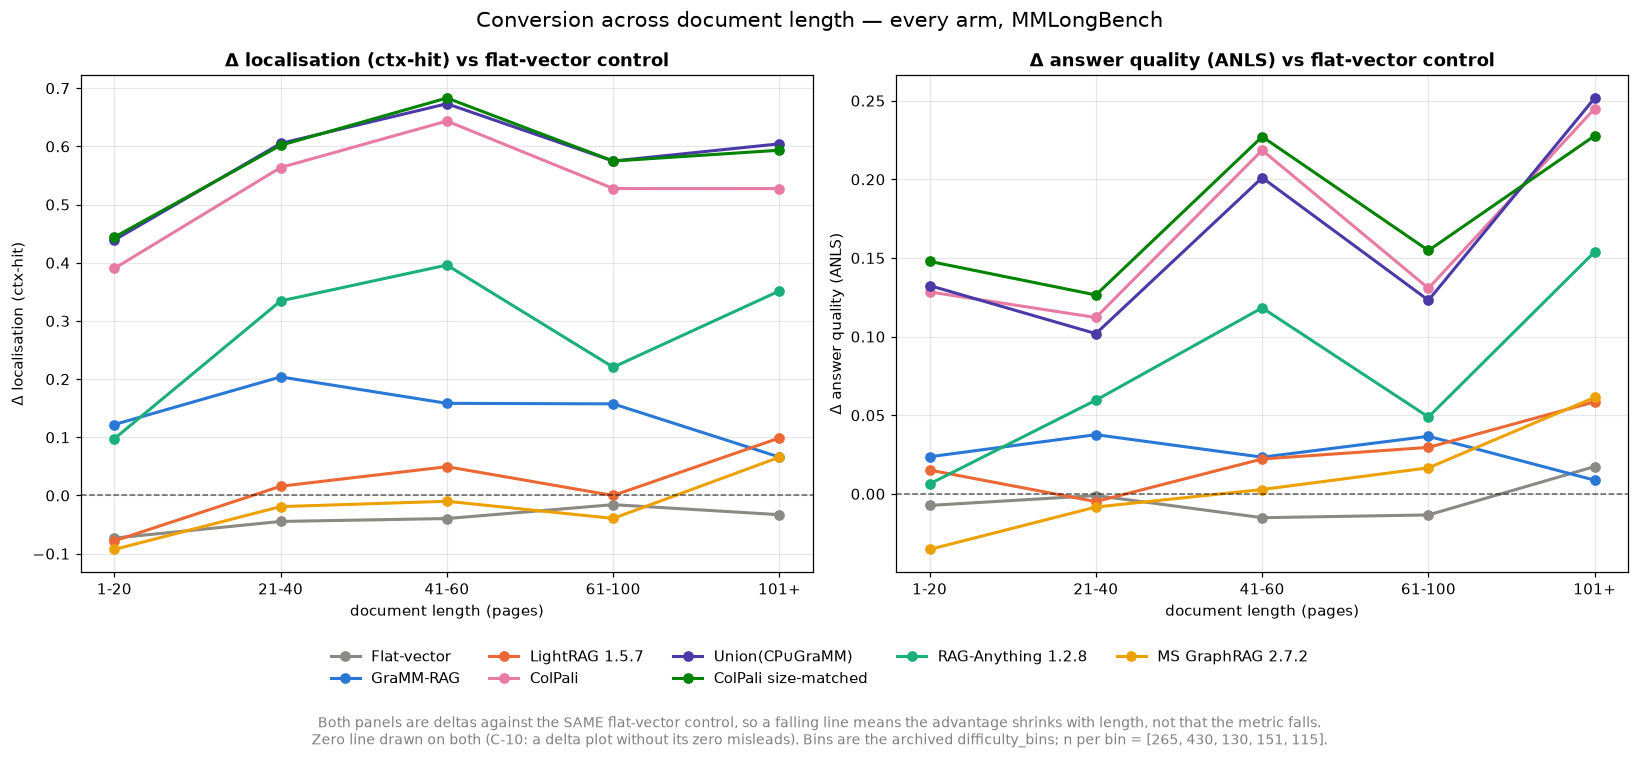

wrote /work/GraphRAG_baseline/figures/fig_length_conversion.png

arms whose ANSWER advantage is NEGATIVE in the 101+ bin: 0/8
arms whose LOCALISATION advantage is still POSITIVE at 101+: 7/8

The conversion frontier is the set of arms in BOTH lists: localisation still
ahead of the control, answer quality no longer following it.
  -> none


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
labels = [lab for _,_,lab in EDGES]
x = np.arange(len(labels))
for ax, tbl, name in ((axes[0], dl_tbl, '\u0394 localisation (ctx-hit)'),
                      (axes[1], dq_tbl, '\u0394 answer quality (ANLS)')):
    for s, row in tbl.items():
        ax.plot(x, row, marker='o', lw=2, color=CC[s], label=s)
    ax.axhline(0, color='black', lw=1, ls='--', alpha=.6)
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_xlabel('document length (pages)'); ax.set_ylabel(name)
    ax.set_title(name + ' vs flat-vector control', fontsize=12, fontweight='bold')
    ax.grid(alpha=.3); ax.set_axisbelow(True)
# Shared legend BELOW both panels: at 'upper right' it covered the 101+ endpoints of the
# three vision lines -- the exact points the section is about.
h, l = axes[1].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=5, frameon=False, fontsize=9.5,
           bbox_to_anchor=(0.5, -0.10))
fig.suptitle('Conversion across document length \u2014 every arm, MMLongBench', fontsize=14)
fig.text(0.5, -0.17,
         'Both panels are deltas against the SAME flat-vector control, so a falling line '
         'means the advantage shrinks with length, not that the metric falls.\n'
         'Zero line drawn on both (C-10: a delta plot without its zero misleads). '
         'Bins are the archived difficulty_bins; n per bin = '
         + str([counts[l] for l in labels]) + '.',
         ha='center', fontsize=9, color='grey')
plt.tight_layout()
fig.savefig(FIG/'fig_length_conversion.png', dpi=150, bbox_inches='tight')
plt.show()
print('wrote', FIG/'fig_length_conversion.png')
print()
neg = {s: row[-1] for s, row in dq_tbl.items() if row[-1] < 0}
print(f'arms whose ANSWER advantage is NEGATIVE in the 101+ bin: {len(neg)}/{len(dq_tbl)}')
for s, v in neg.items(): print(f'    {s}: {v:+.4f}')
pos_loc = {s: row[-1] for s, row in dl_tbl.items() if row[-1] > 0}
print(f'arms whose LOCALISATION advantage is still POSITIVE at 101+: '
      f'{len(pos_loc)}/{len(dl_tbl)}')
print('\nThe conversion frontier is the set of arms in BOTH lists: localisation still')
print('ahead of the control, answer quality no longer following it.')
both = sorted(set(neg) & set(pos_loc))
print(f'  -> {both if both else "none"}')

### 13.0b Multiplicity and intervals for the 101+ claim

Section 13's original headline was *GraMM is the only arm whose answer advantage is
negative at 101+ pages*. That is a claim about arms tested in one bin, so it gets the
treatment section 12 got: an interval on each, and a correction for multiplicity. It is
also the claim C-81 overturned — against a page-matched control no arm is negative at
101+ — so the table below is the test of a retired headline, kept because the retirement
is the result.

In [34]:
ix101 = np.array(bins['101+'])
rng5 = np.random.default_rng(42)
print(f"101+ bin, n={len(ix101)}   dANLS vs the page-matched control ({CTRL})")
print(f"{'arm':22s}{'dANLS':>9s}{'95% CI':>22s}{'Bonferroni 99% CI':>24s}{'':>6s}")
neg_ci = {}
for s in S:
    if s == CTRL: continue
    d = S[s][ix101] - S[CTRL][ix101]
    bs = d[rng5.integers(0, len(d), (4000, len(d)))].mean(axis=1)
    lo, hi = np.percentile(bs, [2.5, 97.5])
    lob, hib = np.percentile(bs, [0.5, 99.5])
    tag = ('neg*' if hi < 0 else 'pos*' if lo > 0 else 'null')
    tagb = ('**' if (lob > 0 or hib < 0) else '')
    neg_ci[s] = (d.mean(), lo, hi, lob, hib)
    print(f'{s:22s}{d.mean():>+9.4f}  [{lo:+.4f},{hi:+.4f}]  [{lob:+.4f},{hib:+.4f}]'
          f'  {tag}{tagb}')
print('\n*  = 95% CI excludes zero   ** = survives Bonferroni over 5 arms')
neg_pt = [s for s, v in neg_ci.items() if v[0] < 0]
neg_sig = [s for s, v in neg_ci.items() if v[2] < 0]
print(f'\narms with NEGATIVE point estimate at 101+ : {neg_pt}')
print(f'arms whose 95% CI excludes zero (negative): {neg_sig if neg_sig else "none"}')
print()
if not neg_pt:
    print('NO arm has a negative answer-quality delta at 101+ against the PAGE-MATCHED')
    print('control. The published 101+ collapse (dANLS -0.009, GraMM alone below zero) was')
    print('measured against a control reading one page fewer: it reproduces exactly against')
    print('that control and does not survive matching (C-81). What survives is a SHRINKING')
    print('advantage, not a sign change -- GraMM 101+ is its smallest bin by a factor of')
    print('~3 while its localisation advantage stays clearly positive.')
else:
    print(f'arms below zero at 101+: {neg_pt}. The uniqueness claim is about POINT')
    print('ESTIMATES; an interval spanning zero makes it descriptive, not a demonstration.')
print('n=115 is the smallest bin, and every interval here spans zero for the graph arms.')

101+ bin, n=115   dANLS vs the page-matched control (Flat-vector (k=3))
arm                       dANLS                95% CI       Bonferroni 99% CI      
Flat-vector             +0.0174  [-0.0261,+0.0609]  [-0.0348,+0.0783]  null
GraMM-RAG               +0.0087  [-0.0348,+0.0522]  [-0.0435,+0.0696]  null
LightRAG 1.5.7          +0.0586  [-0.0106,+0.1270]  [-0.0327,+0.1496]  null
ColPali                 +0.2450  [+0.1390,+0.3507]  [+0.0970,+0.3889]  pos***
Union(CP∪GraMM)         +0.2517  [+0.1415,+0.3583]  [+0.1054,+0.3910]  pos***
ColPali size-matched    +0.2277  [+0.1123,+0.3376]  [+0.0771,+0.3735]  pos***
RAG-Anything 1.2.8      +0.1540  [+0.0556,+0.2506]  [+0.0286,+0.2845]  pos***
MS GraphRAG 2.7.2       +0.0613  [-0.0071,+0.1281]  [-0.0261,+0.1502]  null

*  = 95% CI excludes zero   ** = survives Bonferroni over 5 arms

arms with NEGATIVE point estimate at 101+ : []
arms whose 95% CI excludes zero (negative): none

NO arm has a negative answer-quality delta at 101+ against the P

### 13.1 Reading the result — the 101+ collapse does not survive a page-matched control

**Stated plainly, because the retraction is the result (C-81):**

| arm | dANLS at 101+, vs k=2 control | dANLS at 101+, **vs page-matched control** | d ctx-hit at 101+ |
|---|---|---|---|
| **GraMM-RAG** | **-0.0087** — *the only negative* | **+0.0087** [-0.0348, +0.0522] | +0.0659 |
| Flat-vector (k=2) | — | +0.0174 [-0.0261, +0.0609] | -0.0330 |
| LightRAG 1.5.7 | +0.0412 | +0.0586 [-0.0106, +0.1270] | +0.0989 |
| ColPali | +0.2276 | +0.2450 [+0.1390, +0.3507] | +0.5275 |
| Union(CP∪GraMM) | +0.2343 | +0.2517 [+0.1415, +0.3583] | +0.6044 |
| ColPali size-matched | +0.2104 | +0.2277 [+0.1123, +0.3376] | +0.5934 |
| RAG-Anything 1.2.8 | — | +0.1540 [+0.0556, +0.2506] | +0.3516 |
| MS GraphRAG 2.7.2 | — | +0.0613 [-0.0071, +0.1281] | +0.0659 |

**The sign change was a property of the control.** Against the archived k=2 control GraMM's
101+ delta reproduces the published -0.009 exactly. Against a control reading the same three
pages it is **+0.0087**, and **no arm is negative at 101+**. The claim *GraMM is the only arm
whose answer advantage turns negative on the longest documents* is therefore **withdrawn**.
It was never significant either way -- its interval always spanned zero -- but the point
estimate, which is what the claim rested on, does not keep its sign.

**What survives, and is worth saying.** GraMM's advantage at 101+ is its **smallest**:
+0.0087 against +0.0233 to +0.0376 in every other bin, roughly a third, while its
localisation advantage there stays clearly positive (+0.0659). That is the conversion gap as
a *shrinking ratio* on long documents, not a collapse into deficit.

**A finding about the control itself.** The k=2 arm **outscores** the k=3 arm at 101+
(+0.0174): on documents past 100 pages the third context page costs more in distraction than
it returns in evidence. Every other bin runs the other way. That is a property of long
documents and a context budget, measured on the control rather than argued from a system.

**What IS established at 101+:** the vision arms hold a large advantage that survives
Bonferroni correction (ColPali +0.2450 [+0.0970, +0.3889] corrected; RAG-Anything likewise),
while neither graph arm has a demonstrable advantage at all. The defensible contrast remains
*vision retains, graph does not demonstrably retain* — and it no longer needs, or has, a
GraMM-specific collapse behind it.

**This still qualifies Gate C.** Its reading — the conversion loss is *a property of the
pipeline, not of any one retriever* — holds for the **pooled** comparison and does **not**
hold in the length dimension, where ColPali's answer advantage is largest on the 101+ bin.
The pooled statement and the length-resolved statement are different claims, and only the
first survives.

In [35]:
from collections import Counter
doc_types = sorted({r['doc_type'] for r in qm_rows})
ev_sources = sorted({e for r in qm_rows for e in (r['evidence_sources'] or [])})
no_ev = [i for i,r in enumerate(qm_rows) if not r['evidence_sources']]
print(f'doc types {len(doc_types)}  evidence sources {len(ev_sources)}  '
      f'questions with none {len(no_ev)}')
# A4's own caveat, carried forward: these strata OVERLAP, so the columns are not a
# partition and must never be summed or averaged into a single 'per-source' score.
assert sum(len([i for i,r in enumerate(qm_rows) if e in (r['evidence_sources'] or [])])
           for e in ev_sources) != 1091, 'evidence strata are multi-label, not a partition'
print('evidence strata confirmed multi-label (overlapping, not a partition)')

doc types 7  evidence sources 5  questions with none 254
evidence strata confirmed multi-label (overlapping, not a partition)


In [36]:
def delta_table(groups, title):
    print(f'\n=== {title} : dANLS vs flat-vector control ===')
    names = list(groups)
    print(f"{'system':22s}" + ''.join(f'{n[:13]:>15s}' for n in names))
    print(f"{'n':22s}" + ''.join(f'{len(groups[n]):>15d}' for n in names))
    out = {}
    for s in S:
        if s == 'Flat-vector': continue
        row = [S[s][np.array(groups[n])].mean() - S['Flat-vector'][np.array(groups[n])].mean()
               if groups[n] else float('nan') for n in names]
        out[s] = row
        print(f'{s:22s}' + ''.join(f'{v:>+15.4f}' for v in row))
    # winner per column, printed beside the column rather than asserted in prose (rule 17)
    print(f"{'BEST':22s}" + ''.join(
        f'{max(out, key=lambda s: out[s][j])[:13]:>15s}' for j in range(len(names))))
    return names, out

ev_groups = {e: [i for i,r in enumerate(qm_rows) if e in (r['evidence_sources'] or [])]
             for e in ev_sources}
ev_groups['(no source)'] = no_ev
ev_names, ev_out = delta_table(ev_groups, 'EVIDENCE SOURCE')
dt_groups = {d: [i for i,r in enumerate(qm_rows) if r['doc_type']==d] for d in doc_types}
dt_names, dt_out = delta_table(dt_groups, 'DOCUMENT TYPE')


=== EVIDENCE SOURCE : dANLS vs flat-vector control ===
system                          Chart         Figure  Generalized-t  Pure-text (Pl          Table    (no source)
n                                 178            293            119            298            218            254
GraMM-RAG                     +0.0492        +0.0337        +0.0295        +0.0487        +0.0943        -0.0351
LightRAG 1.5.7                +0.0169        +0.0081        +0.1518        +0.0656        +0.0788        -0.0342
ColPali                       +0.2912        +0.2642        +0.3091        +0.2667        +0.2614        -0.2885
Union(CP∪GraMM)               +0.2738        +0.2737        +0.3279        +0.2400        +0.3038        -0.3239
ColPali size-matched          +0.2959        +0.2960        +0.3472        +0.2800        +0.3342        -0.3273
RAG-Anything 1.2.8            +0.1859        +0.1616        +0.1761        +0.0922        +0.2006        -0.2310
MS GraphRAG 2.7.2             +0.0021   

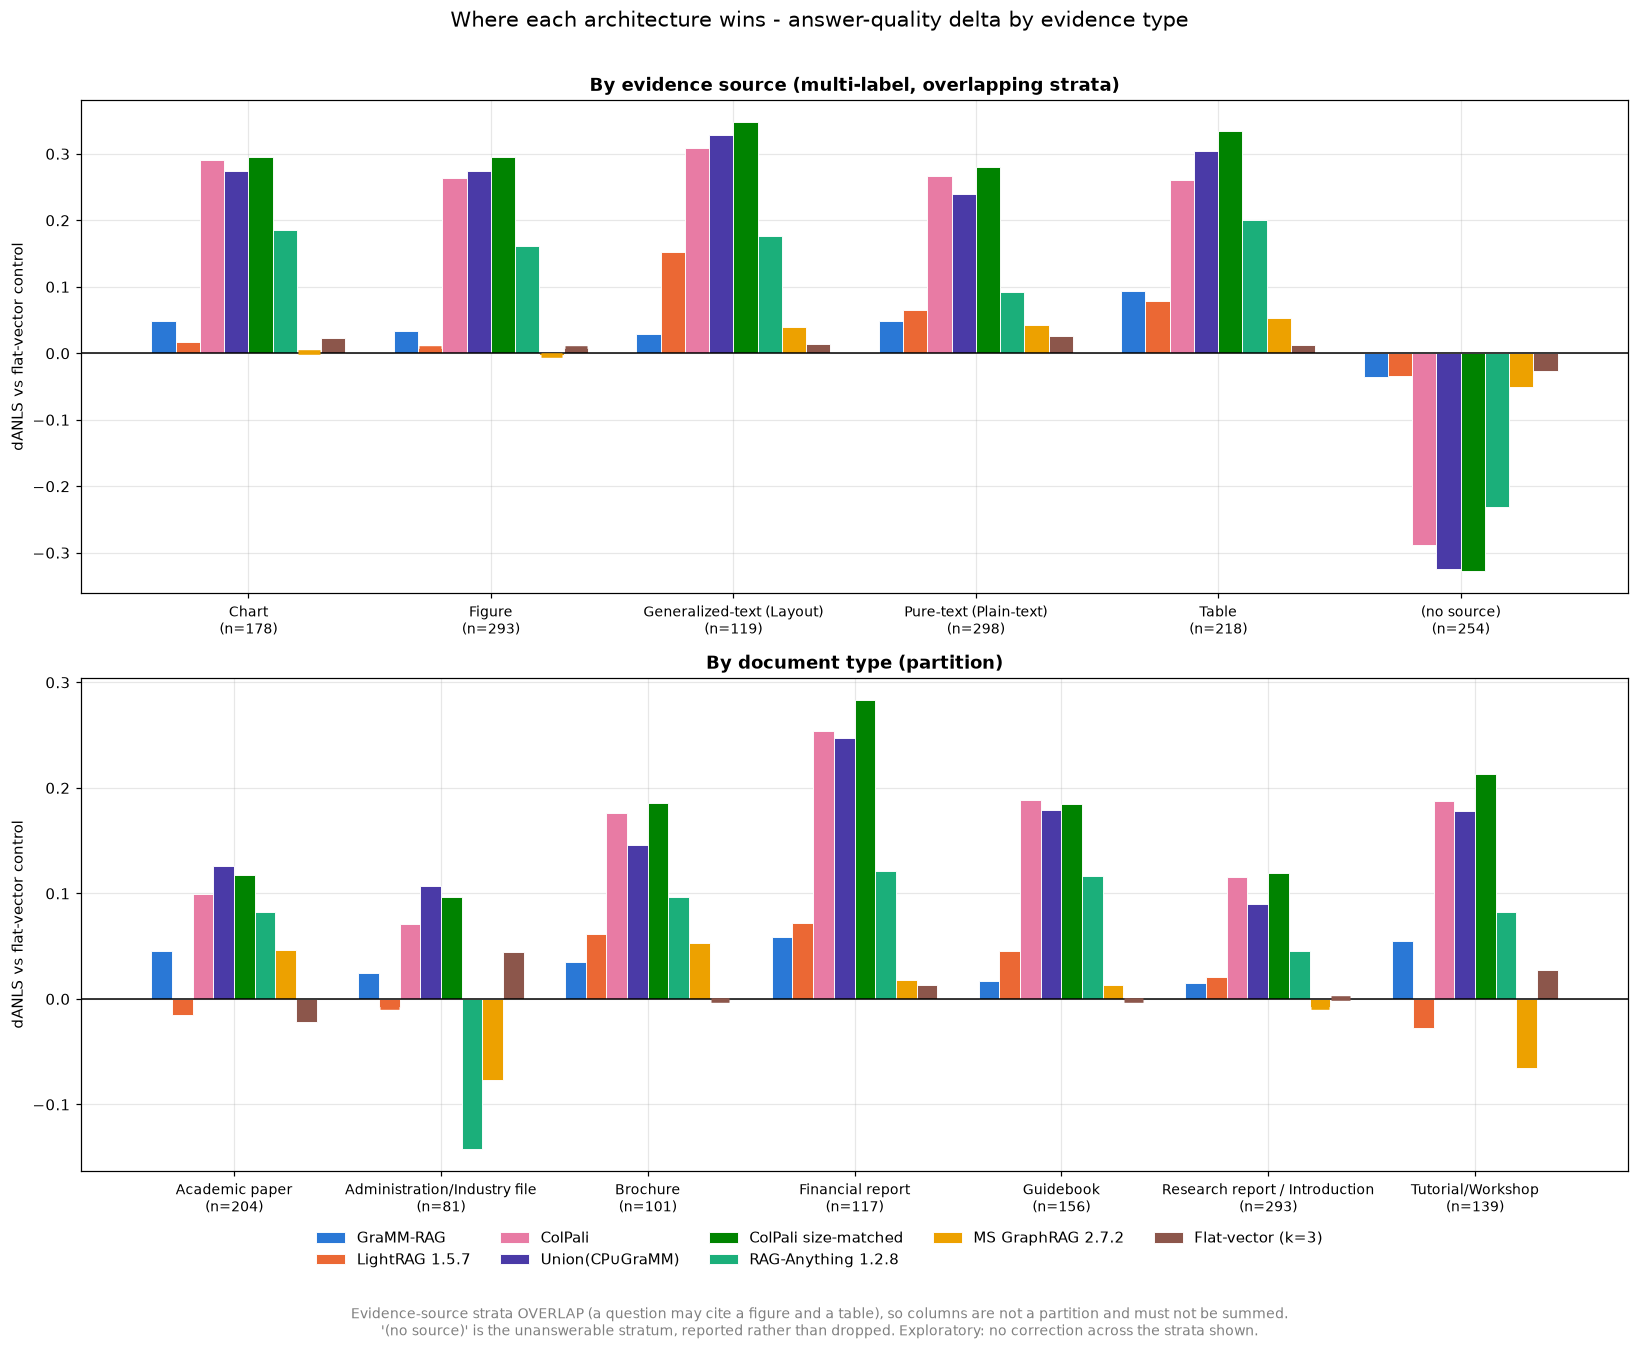

wrote /work/GraphRAG_baseline/figures/fig_evidence_type.png


In [37]:
fig, axes = plt.subplots(2, 1, figsize=(15, 11))
for ax, (names, out, title) in zip(axes, [
        (ev_names, ev_out, 'By evidence source (multi-label, overlapping strata)'),
        (dt_names, dt_out, 'By document type (partition)')]):
    x = np.arange(len(names)); w = 0.8/len(out)
    for i,(s,row) in enumerate(out.items()):
        xs = x + i*w - 0.4 + w/2
        ax.bar(xs, row, w, label=s, color=CC[s], edgecolor='white', linewidth=0.6)
        # A near-zero delta draws as a sub-pixel bar, indistinguishable from an ABSENT arm:
        # MS GraphRAG's Chart (+0.0021) and Figure (-0.0021) deltas read as missing data.
        # A short tick at the value keeps a measured-but-tiny effect visibly present.
        for xi, v in zip(xs, row):
            if v == v and abs(v) < 0.012:
                ax.plot([xi - w*0.45, xi + w*0.45], [v, v], color=CC[s], lw=3,
                        solid_capstyle='butt', zorder=4)
    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels([f'{n}\n(n={len(ev_groups.get(n, dt_groups.get(n,[])))})'
                        for n in names], fontsize=9)
    ax.set_ylabel('dANLS vs flat-vector control')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=.3); ax.set_axisbelow(True)
h,l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=5, frameon=False, fontsize=9.5,
           bbox_to_anchor=(0.5,-0.04))
fig.suptitle('Where each architecture wins - answer-quality delta by evidence type',
             fontsize=14, y=1.01)
fig.text(0.5, -0.085,
         'Evidence-source strata OVERLAP (a question may cite a figure and a table), so '
         'columns are not a partition and must not be summed.\n'
         '\'(no source)\' is the unanswerable stratum, reported rather than dropped. '
         'Exploratory: no correction across the strata shown.',
         ha='center', fontsize=9, color='grey')
plt.tight_layout()
fig.savefig(FIG/'fig_evidence_type.png', dpi=150, bbox_inches='tight')
plt.show(); print('wrote', FIG/'fig_evidence_type.png')

### 14.1 Reading the result - where GraMM wins, and where it does not

**GraMM wins no column outright, on either stratification.** The ColPali family takes every
evidence source and every document type (Union takes two). That is the pooled result
reappearing at every level of disaggregation, and it is stated first because a merits
section that opened with the specialisations below would be selecting strata after seeing
them.

Three signals survive that framing, and each is checkable in the table above:

**1. Tables are GraMM's strongest evidence type.** dANLS **+0.0943** on Table against
+0.0295-+0.0492 on Chart, Figure, Layout and Pure-text - roughly double its next best. The
typed-edge graph carries structured tabular evidence better than anything else it sees,
which is the one place the architecture's design shows through in this stratification.

**2. The abstention story reappears, and it is the largest effect on the figure.** On the
254 questions with no evidence source - the unanswerable stratum - GraMM loses **0.0351**
and LightRAG **0.0342**, while ColPali loses **0.2885** and the union arms more.
**Roughly 8x.** The graph systems give up almost nothing when there is nothing to find;
the vision arms collapse. This is the same operating-point difference section 11 measured,
now visible as the single widest gap in a chart of 13 strata.

**3. LightRAG beats GraMM on layout-heavy evidence, by 5x.** Generalized-text (Layout):
LightRAG **+0.1518** against GraMM **+0.0295**. An entity-relation graph over serialised
text outperforms a heterogeneous document graph on exactly the evidence type the document
graph's spatial and hierarchy edges exist to handle. Reported because it is the clearest
counter-example in this notebook to the claim that GraMM's typed edges buy layout
understanding, and no explanation for it is offered here - it is a finding, not a story.

**LightRAG's weakness is also visible:** negative on Academic paper (-0.0153),
Administration/Industry (-0.0079) and Tutorial/Workshop (-0.0272) - the only arm to go
backwards against the control on whole document types.

**Scope.** Exploratory. Thirteen strata, five arms, no multiplicity correction and no CIs;
the smallest stratum is n=81. These are descriptive contrasts for the merits inventory,
not tested effects, and any of them could be re-derived as a formal test with correction
if it is to carry weight in the write-up.

## 15. Conversion efficiency with confidence intervals (dimension D)

Section 11 reported eta = dQuality / dLocalisation as **descriptive, not a test**, because
it is a ratio of two noisy differences. Bootstrapping the ratio itself lets it carry
weight - or shows that it cannot.

**A ratio needs a caveat a difference does not.** When the denominator's own CI approaches
zero the ratio is unstable and its percentile interval becomes uninformative or unbounded:
dividing by a near-zero draw sends the ratio to infinity. So the denominator's CI is
reported **beside** every eta, and any arm whose localisation delta is not itself clearly
non-zero is marked UNSTABLE rather than given a spuriously tight interval.

In [38]:
# Paired bootstrap over QUESTIONS, resampling once per draw and recomputing BOTH deltas
# from the same resample -- numerator and denominator must move together, or the ratio's
# spread is wrong.
ctx_ix = [i for i in range(len(gold_pages)) if ans[i] and gold_pages[i]]
ctx_arr = {s: np.array([ctxf[s][i] for i in ctx_ix]) for s in S}
rng3 = np.random.default_rng(42)
# C-80: the page-matched control here too -- eta's denominator is a localisation delta,
# and the k=2 control's missing page inflated it for every arm.
CTRL15 = 'Flat-vector (k=3)' if 'Flat-vector (k=3)' in S else 'Flat-vector'
N_Q, N_C, NB = len(S[CTRL15]), len(ctx_ix), 4000

print(f"{'system':22s}{'eta':>8s}{'95% CI (eta)':>26s}{'dLoc':>9s}{'dLoc 95% CI':>22s}{'':>3s}")
eta_ci = {}
for s in S:
    if s == CTRL: continue
    dq = S[s] - S[CTRL15]; dl = ctx_arr[s] - ctx_arr[CTRL15]
    eta_obs = dq.mean() / dl.mean() if dl.mean() else float('nan')
    iq = rng3.integers(0, N_Q, (NB, N_Q)); ic = rng3.integers(0, N_C, (NB, N_C))
    nq = dq[iq].mean(axis=1); nl = dl[ic].mean(axis=1)
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = np.where(np.abs(nl) > 1e-9, nq / nl, np.nan)
    lo_e, hi_e = np.nanpercentile(ratio, [2.5, 97.5])
    lo_l, hi_l = np.percentile(nl, [2.5, 97.5])
    # A denominator CI that merely excludes zero is NOT sufficient: LightRAG's dLoc CI
    # excludes zero ([+0.011,+0.088]) yet its eta interval spans [-0.20,+1.85], because
    # the interval still comes close to zero relative to its own width. Require the
    # denominator to be bounded away from zero by a clear margin (lower bound >= 25% of
    # the point estimate) before treating the ratio as interpretable.
    stable = (lo_l > 0.25 * abs(dl.mean())) or (hi_l < -0.25 * abs(dl.mean()))
    eta_ci[s] = (eta_obs, lo_e, hi_e, dl.mean(), lo_l, hi_l, stable)
    flag = '' if stable else 'UNSTABLE'
    print(f'{s:22s}{eta_obs:>8.3f}  [{lo_e:+.3f},{hi_e:+.3f}]{dl.mean():>9.4f}'
          f'  [{lo_l:+.4f},{hi_l:+.4f}] {flag}')
print('\nUNSTABLE = the localisation delta driving the denominator is not itself clearly')
print('non-zero, so the ratio interval is not trustworthy however narrow it looks.')

system                     eta              95% CI (eta)     dLoc           dLoc 95% CI   
Flat-vector              0.089  [-0.264,+0.465]  -0.0453  [-0.0597,-0.0322] 
GraMM-RAG                0.188  [+0.058,+0.331]   0.1563  [+0.1265,+0.1862] 
LightRAG 1.5.7           4.092  [-9.642,+10.105]   0.0036  [-0.0346,+0.0394] UNSTABLE


ColPali                  0.279  [+0.214,+0.351]   0.5215  [+0.4833,+0.5573] 


Union(CP∪GraMM)          0.246  [+0.188,+0.308]   0.5680  [+0.5334,+0.6014] 
ColPali size-matched     0.279  [+0.216,+0.343]   0.5680  [+0.5334,+0.6038] 
RAG-Anything 1.2.8       0.231  [+0.110,+0.364]   0.2685  [+0.2255,+0.3115] 
MS GraphRAG 2.7.2        0.094  [-2.037,+2.586]  -0.0298  [-0.0668,+0.0060] UNSTABLE

UNSTABLE = the localisation delta driving the denominator is not itself clearly
non-zero, so the ratio interval is not trustworthy however narrow it looks.


In [39]:
# Does GraMM convert SIGNIFICANTLY less than the others? Bootstrap the DIFFERENCE of
# etas, which is the comparison section 11's ranking implies but never tested.
print('pairwise eta differences vs GraMM-RAG (positive = the other arm converts better)')
print(f"{'contrast':34s}{'d eta':>9s}{'95% CI':>26s}{'corrected CI':>22s}")
dq_g = S['GraMM-RAG'] - S[CTRL15]; dl_g = ctx_arr['GraMM-RAG'] - ctx_arr[CTRL15]
for s in S:
    if s in (CTRL15, 'GraMM-RAG'): continue
    if not eta_ci[s][6]:
        print(f'{s+" - GraMM-RAG":34s}{"--":>9s}{"denominator unstable":>26s}')
        continue
    dq_o = S[s] - S[CTRL15]; dl_o = ctx_arr[s] - ctx_arr[CTRL15]
    iq = rng3.integers(0, N_Q, (NB, N_Q)); ic = rng3.integers(0, N_C, (NB, N_C))
    with np.errstate(divide='ignore', invalid='ignore'):
        r_o = dq_o[iq].mean(axis=1) / dl_o[ic].mean(axis=1)
        r_g = dq_g[iq].mean(axis=1) / dl_g[ic].mean(axis=1)
    d = r_o - r_g
    lo, hi = np.nanpercentile(d, [2.5, 97.5])
    obs = (dq_o.mean()/dl_o.mean()) - (dq_g.mean()/dl_g.mean())
    # 4 pairwise tests -> Bonferroni alpha 0.0125 -> 98.75% CI, computed not asserted
    lob, hib = np.nanpercentile(d, [0.625, 99.375])
    sig = '*' if (lo > 0 or hi < 0) else ' '
    sigb = '**' if (lob > 0 or hib < 0) else '  '
    print(f'{s+" - GraMM-RAG":34s}{obs:>+9.3f}  [{lo:+.3f},{hi:+.3f}]{sig}'
          f'  [{lob:+.3f},{hib:+.3f}]{sigb}')
print('\n*  = 95% CI excludes zero    ** = survives Bonferroni over 4 tests (98.75% CI)')

pairwise eta differences vs GraMM-RAG (positive = the other arm converts better)
contrast                              d eta                    95% CI          corrected CI


Flat-vector - GraMM-RAG              -0.099  [-0.516,+0.348]   [-0.635,+0.464]  
LightRAG 1.5.7 - GraMM-RAG               --      denominator unstable
ColPali - GraMM-RAG                  +0.091  [-0.046,+0.219]   [-0.091,+0.253]  
Union(CP∪GraMM) - GraMM-RAG          +0.059  [-0.083,+0.187]   [-0.127,+0.225]  


ColPali size-matched - GraMM-RAG     +0.091  [-0.042,+0.223]   [-0.085,+0.255]  


RAG-Anything 1.2.8 - GraMM-RAG       +0.044  [-0.112,+0.191]   [-0.156,+0.232]  
MS GraphRAG 2.7.2 - GraMM-RAG            --      denominator unstable

*  = 95% CI excludes zero    ** = survives Bonferroni over 4 tests (98.75% CI)


### 15.1 What eta can and cannot carry

Read the intervals before the point estimates. Section 11 ranked the arms by eta and
called GraMM's 0.17 the lowest; that ranking is only meaningful if the intervals separate.
Where they do not, the correct statement is that the arms are **not distinguishable on
conversion efficiency**, and the ranking in section 11 should be read as ordering point
estimates rather than as establishing a difference.

This is the same discipline applied to the answer-quality null in
`GRAPH_BRACKET_RESULT.md`: a point estimate with an interval spanning the comparison is a
failure to distinguish, not a demonstration of similarity, and not a ranking.

## 16. S1 - LightRAG on DocBench: a pre-registered prediction FALSIFIED

Gate H §5 recorded, before generation and scoring: *GraMM will lead LightRAG on DocBench
localisation by a smaller margin than on MMLongBench, and the answer-quality difference
will again fail to reach significance.*

**Both clauses are false.** LightRAG leads on both metrics, significantly. The falsifier
attached to the prediction fires: the between-systems conversion-gap claim is now
benchmark-specific and is withdrawn as general (`S1_DOCBENCH_RESULT.md`, C-42).

In [40]:
import sys
sys.path.insert(0, '/work/gramm-rag-docbench')
from src.evaluation.metrics import evidence_page_hit, _quote_tokens
DB = Path('/work/gramm-rag-3benchmarks/data/docbench')
dbase = json.loads((DB/'baseline_vector_docbench.json').read_text())
dgramm = json.loads((DB/'gramm_docbench_s42.json').read_text())
dlr = json.loads((SC/'lightrag_scores_docbench.json').read_text())
dgen = json.loads((GEN/'lightrag_gen_docbench.json').read_text())
dqm = json.loads((DB/'qmeta_docbench.json').read_text())['rows']
dan, dn = dbase['is_answerable'], dbase['n_questions']

# ---- judge accuracy ----
DJ = {'Flat-vector': np.array(dbase['judge']['judge_scores'], float),
      'GraMM-RAG':   np.array(dgramm['judge']['judge_scores'], float),
      'LightRAG 1.5.7': np.array(dlr['judge_scores'], float)}
assert abs(DJ['GraMM-RAG'].mean()-0.5327) < 5e-4, 'GraMM judge drift'
assert abs(DJ['Flat-vector'].mean()-0.4728) < 5e-4, 'baseline judge drift'
print('drift check OK: archived DocBench judge accuracies reproduced (0.4728 / 0.5327)')

# ---- quote-recall@5, recomputed per question with the canonical predicate ----
# LightRAG's page texts were REBUILT here from the MinerU parse -- which the handoff package
# EXCLUDES as bulk data -- and `f.read_text() if f.exists() else {'elements': []}` swapped each
# missing parse for an EMPTY document. From the package alone LightRAG's quote-recall read
# 0.0000 and pre-registered clause 1 flipped FALSIFIED -> HELD at p = 4.6e-100, with 0 errors.
# The per-question hits are now precomputed on vol3 (precompute_package_artifacts.py, which
# mirrors this cell's exact page assembly and asserts 0.5068) and SHIPPED. Absence raises.
_pre = json.loads((SC/'package_precomputed.json').read_text())   # FileNotFoundError if absent
_lrh = _pre['lightrag_docbench_quote_hits']
assert len(_lrh) == dn, f'precomputed hits cover {len(_lrh)} questions, corpus has {dn}'
# The scoreable index is precomputed: it is derived from DocBench evidence TEXT, which the
# package no longer ships. len(sc) must still be the published 730.
sc = _pre['docbench_quote_scoreable_idx']
assert len(sc) == 730, f'quote-recall denominator moved: {len(sc)}'
# All three arms now read PRECOMPUTED per-question hits. GraMM and Flat-vector were computed
# here from dgramm/dbase['page_texts'] until the public package stopped shipping DocBench
# corpus content (page texts, evidence, questions, golds are DocBench's to redistribute, not
# ours). The precompute asserts 0.4534/0.3959/0.5068 before writing, so this cannot drift.
QR = {'LightRAG 1.5.7': np.array([_lrh[i] for i in sc]),
      'GraMM-RAG': np.array([_pre['gramm_docbench_quote_hits'][i] for i in sc]),
      'Flat-vector': np.array([_pre['flat_docbench_quote_hits'][i] for i in sc])}
# The original check covered GraMM and Flat-vector -- the arms reading STORED page texts, which
# cannot drift -- and omitted LightRAG, the one arm rebuilt from excluded data (rule 20).
assert abs(QR['GraMM-RAG'].mean()-0.4534) < 5e-4 and abs(QR['Flat-vector'].mean()-0.3959) < 5e-4
assert abs(QR['LightRAG 1.5.7'].mean()-0.5068) < 5e-4, 'LightRAG quote-recall drifted from 0.5068'
print(f'drift check OK: quote-recall@5 reproduced for all three arms (0.3959 / 0.4534 / 0.5068), n={len(sc)}')
print(f"\nquote-recall@5  GraMM {QR['GraMM-RAG'].mean():.4f}  "
      f"LightRAG {QR['LightRAG 1.5.7'].mean():.4f}  Flat {QR['Flat-vector'].mean():.4f}")
print(f"judge accuracy  GraMM {DJ['GraMM-RAG'].mean():.4f}  "
      f"LightRAG {DJ['LightRAG 1.5.7'].mean():.4f}  Flat {DJ['Flat-vector'].mean():.4f}")

drift check OK: archived DocBench judge accuracies reproduced (0.4728 / 0.5327)


drift check OK: quote-recall@5 reproduced for all three arms (0.3959 / 0.4534 / 0.5068), n=730

quote-recall@5  GraMM 0.4534  LightRAG 0.5068  Flat 0.3959
judge accuracy  GraMM 0.5327  LightRAG 0.5672  Flat 0.4728


In [41]:
rng4 = np.random.default_rng(42)
def pair4(a, b, nb=4000):
    d = a - b; i = rng4.integers(0, len(d), (nb, len(d)))
    return d.mean(), *np.percentile(d[i].mean(axis=1), [2.5, 97.5])
def mcn4(a, b):
    n10 = int(((a==1)&(b==0)).sum()); n01 = int(((a==0)&(b==1)).sum()); N = n01+n10
    if not N: return 1.0
    k = min(n01, n10)
    return min(1.0, 2*sum(comb(N, j) for j in range(k+1))/(2**N))

for name, D in (('quote-recall@5', QR), ('judge accuracy', DJ)):
    print(f'\n=== DocBench {name} ===')
    for a_, b_ in (('LightRAG 1.5.7','GraMM-RAG'), ('LightRAG 1.5.7','Flat-vector'),
                   ('GraMM-RAG','Flat-vector')):
        m, lo, hi = pair4(D[a_], D[b_]); pv = mcn4(D[a_], D[b_])
        s = '*' if (lo > 0 or hi < 0) else ' '
        print(f'  {a_+" - "+b_:34s}{m:>+9.4f}  [{lo:+.4f},{hi:+.4f}]{s}  McNemar p={pv:.3g}')
print('\n* = 95% CI excludes zero')

# The pre-registered prediction, evaluated mechanically rather than in prose (rule 17).
lead_loc = QR['GraMM-RAG'].mean() > QR['LightRAG 1.5.7'].mean()
m_q, lo_q, hi_q = pair4(DJ['LightRAG 1.5.7'], DJ['GraMM-RAG'])
null_q = not (lo_q > 0 or hi_q < 0)
print('\n--- Gate H §5 prediction, evaluated ---')
print(f'  clause 1  GraMM leads DocBench localisation : {lead_loc}  -> '
      f"{'HELD' if lead_loc else 'FALSIFIED'}")
print(f'  clause 2  quality difference is not significant: {null_q}  -> '
      f"{'HELD' if null_q else 'FALSIFIED'}")
print('\n  Falsifier (Gate H §5): a failed quality null makes the between-systems')
print('  conversion-gap claim benchmark-specific. It failed -> claim WITHDRAWN as general.')


=== DocBench quote-recall@5 ===
  LightRAG 1.5.7 - GraMM-RAG          +0.0534  [+0.0219,+0.0849]*  McNemar p=0.00129
  LightRAG 1.5.7 - Flat-vector        +0.1110  [+0.0781,+0.1438]*  McNemar p=4.69e-11
  GraMM-RAG - Flat-vector             +0.0575  [+0.0301,+0.0849]*  McNemar p=7.69e-05

=== DocBench judge accuracy ===


  LightRAG 1.5.7 - GraMM-RAG          +0.0345  [+0.0045,+0.0644]*  McNemar p=0.0337
  LightRAG 1.5.7 - Flat-vector        +0.0944  [+0.0626,+0.1252]*  McNemar p=5.65e-09
  GraMM-RAG - Flat-vector             +0.0599  [+0.0372,+0.0817]*  McNemar p=2.7e-07

* = 95% CI excludes zero

--- Gate H §5 prediction, evaluated ---
  clause 1  GraMM leads DocBench localisation : False  -> FALSIFIED
  clause 2  quality difference is not significant: False  -> FALSIFIED

  Falsifier (Gate H §5): a failed quality null makes the between-systems
  conversion-gap claim benchmark-specific. It failed -> claim WITHDRAWN as general.


### 16.1 M9 reverses across corpora

| corpus | metric | GraMM vs LightRAG | significance |
|---|---|---|---|
| MMLongBench | ctx-hit | GraMM **+0.1527** | p=7.7e-12 |
| DocBench | quote-recall@5 | LightRAG **+0.0534** | p=0.0013 |

Two corpora, opposite directions, both significant. M9 is stated as localisation
leadership **on MMLongBench**; it cannot be stated as leadership over LightRAG.

**Why the prediction missed.** Its rationale was right about GraMM - the edge over the
control is 3.5x larger on MMLongBench (+0.2017) than on DocBench (+0.0575). It ignored
that **LightRAG's edge moves in the opposite direction**: +0.0489 on MMLongBench against
+0.1110 on DocBench, a 2.3x increase. A prediction about a contrast needs a trend for both
sides; holding the comparator implicitly fixed is a one-sided model of a two-sided
quantity (C-42).

## 17. Rank stability across benchmarks (G-2)

S1 showed the GraMM/LightRAG ordering **reverses** between corpora. That is an anecdote
about one pair until it has a statistic. With all six arms now measured on both
benchmarks, the ranking each corpus induces can be compared directly.

**Why this comparison is available where G-1's was not.** G-1 failed because eta cannot be
compared across corpora with incommensurable metrics. **Rankings are scale-free**: it does
not matter that MMLongBench localisation is ctx-hit and DocBench's is quote-recall@5, nor
that quality is ANLS on one and judge accuracy on the other, because a rank order is
invariant to any monotone rescaling of the underlying metric. The confound that killed the
eta comparison does not touch this one.

Reported as **Kendall's tau-b** per metric family, with the raw rank table beside it, so
the coefficient is never the only thing on the page.

In [42]:
SYS6 = ['Flat-vector','LightRAG 1.5.7','GraMM-RAG','ColPali',
        'Union(CP\u222aGraMM)','ColPali size-matched']
assert all(s in sr['mmlongbench'] and s in sr['docbench'] for s in SYS6), \
       'G-2 requires every arm on BOTH corpora'
print(f'arms on both corpora: {len(SYS6)}')

LOCD = {'LightRAG 1.5.7': QR['LightRAG 1.5.7'].mean(),
        'GraMM-RAG': QR['GraMM-RAG'].mean(), 'Flat-vector': QR['Flat-vector'].mean()}
for arm, lab in (('colpali','ColPali'), ('union','Union(CP\u222aGraMM)'),
                 ('colpali_matched','ColPali size-matched'),
                 ('lightrag','LightRAG 1.5.7'), ('s2','RAG-Anything 1.2.8'),
                 ('s5','MS GraphRAG 2.7.2')):
    f = SC/f'{arm}_scores_docbench.json'
    if f.exists(): LOCD[lab] = json.loads(f.read_text())['quote_recall@5']

FAM = {
  'localisation':  ({s: LOC['mmlongbench'][s] for s in SYS6},
                    {s: LOCD[s] for s in SYS6}, 'ctx-hit', 'quote-recall@5'),
  'answer quality':({s: sr['mmlongbench'][s]['pooled'] for s in SYS6},
                    {s: sr['docbench'][s]['pooled'] for s in SYS6}, 'ANLS', 'judge acc.'),
  'abstention':    ({s: sr['mmlongbench'][s]['abstention_balanced_acc'] for s in SYS6},
                    {s: sr['docbench'][s]['abstention_balanced_acc'] for s in SYS6},
                    'balanced acc.', 'balanced acc.'),
}

def ranks(d):   # 1 = best; average ranks for ties
    vals = sorted(d.values(), reverse=True)
    out = {}
    for s, v in d.items():
        hits = [i for i, x in enumerate(vals) if x == v]
        out[s] = 1 + sum(hits)/len(hits)
    return out

def kendall_tau_b(x, y):
    n = len(x); nc = nd = tx = ty = 0
    for i in range(n):
        for j in range(i+1, n):
            a = x[i]-x[j]; b = y[i]-y[j]
            if a == 0 and b == 0: tx += 1; ty += 1
            elif a == 0: tx += 1
            elif b == 0: ty += 1
            elif a*b > 0: nc += 1
            else: nd += 1
    n0 = n*(n-1)/2
    den = ((n0-tx)*(n0-ty))**0.5
    return (nc-nd)/den if den else float('nan')

arms on both corpora: 6


In [43]:
taus = {}
for fam,(mm, db, mname, dname) in FAM.items():
    rm, rd = ranks(mm), ranks(db)
    tau = kendall_tau_b([rm[s] for s in SYS6], [rd[s] for s in SYS6])
    taus[fam] = tau
    print(f'\n=== {fam}:  MMLongBench {mname}  vs  DocBench {dname} ===')
    print(f"{'system':22s}{'MMLB val':>10s}{'rank':>6s}{'DocB val':>10s}{'rank':>6s}{'shift':>7s}")
    for s in sorted(SYS6, key=lambda z: rm[z]):
        sh = rd[s]-rm[s]
        print(f'{s:22s}{mm[s]:>10.4f}{rm[s]:>6.1f}{db[s]:>10.4f}{rd[s]:>6.1f}{sh:>+7.1f}')
    print(f"  Kendall's tau-b = {tau:+.3f}")
print('\n=== concordance summary ===')
for fam, tau in taus.items():
    lab = ('near-perfect' if tau >= .9 else 'strong' if tau >= .7 else
           'moderate' if tau >= .4 else 'weak' if tau >= .1 else
           'none' if tau > -.1 else 'inverted')
    print(f'  {fam:16s} tau-b {tau:+.3f}   ({lab})')
print(f"\n  n = {len(SYS6)} systems, {len(SYS6)*(len(SYS6)-1)//2} pairs per family.")
print('  With 6 systems the coefficient is coarse: one adjacent swap moves tau-b by ~0.13,')
print('  so read the rank table, not the coefficient alone.')


=== localisation:  MMLongBench ctx-hit  vs  DocBench quote-recall@5 ===
system                  MMLB val  rank  DocB val  rank  shift
Union(CP∪GraMM)           0.8461   1.5    0.6274   1.0   -0.5
ColPali size-matched      0.8461   1.5    0.6178   2.0   +0.5
ColPali                   0.7995   3.0    0.5986   3.0   +0.0
GraMM-RAG                 0.4344   4.0    0.4534   5.0   +1.0
LightRAG 1.5.7            0.2816   5.0    0.5068   4.0   -1.0
Flat-vector               0.2327   6.0    0.3959   6.0   +0.0
  Kendall's tau-b = +0.828

=== answer quality:  MMLongBench ANLS  vs  DocBench judge acc. ===
system                  MMLB val  rank  DocB val  rank  shift
ColPali size-matched      0.4811   1.0    0.7759   2.0   +1.0
ColPali                   0.4683   2.0    0.7740   3.0   +1.0
Union(CP∪GraMM)           0.4628   3.0    0.7768   1.0   -2.0
GraMM-RAG                 0.3522   4.0    0.5327   5.0   +1.0
LightRAG 1.5.7            0.3376   5.0    0.5672   4.0   -1.0
Flat-vector               

### 17.1 What rank concordance does and does not establish

A high tau means the corpora agree on the ordering; a low one means a single-benchmark
ranking does not transfer. **It says nothing about margins** — two systems can swap rank on
a difference of 0.001, and tau-b treats that identically to a reversal of a large,
significant gap. The GraMM/LightRAG reversal matters because **both directions were
separately significant** (MMLongBench p=7.7e-12, DocBench p=0.0013), not because the ranks
moved.

So the citable claim is conditional: where a rank pair reverses **and** both directions are
individually significant, a single-benchmark comparison of that pair is not merely noisy —
it is misleading. tau-b locates the candidates; the paired tests decide which ones count.

**Scope.** Two corpora, six arms, one pairing per metric family. tau-b over 6 items is
coarse and has no meaningful p-value at this n; it is reported as a descriptive concordance
measure beside the ranks, not as a test.

### 17.2 Result - concordance is metric-family dependent, and abstention INVERTS

| metric family | Kendall's tau-b | reading |
|---|---|---|
| localisation | **+0.828** | strong agreement across corpora |
| answer quality | **+0.600** | moderate |
| **abstention** | **-0.828** | **near-total inversion** |

**The headline is the third row.** On MMLongBench the abstention ranking runs
LightRAG > Flat-vector > GraMM > ColPali > ColPali-matched > Union. On DocBench it runs
almost exactly backwards: Union and ColPali-matched tie at the top, ColPali third, then
GraMM, LightRAG, Flat-vector. **The text and graph systems occupy the top of one corpus
and the bottom of the other; the vision systems do the reverse.**

So for abstention, a single-benchmark comparison is not merely unreliable - it is
**actively misleading**, because it will order the systems roughly opposite to how the
other corpus orders them. This is the measured, citable form of the corpus-dependence
finding, and it is stronger than the S1 pair reversal that prompted the analysis.

**Localisation and quality are far more stable** (+0.828, +0.600), so the instability is
not a general property of these benchmarks. It is specific to the abstention family - the
one whose metric is identical on both corpora (decline-decision balanced accuracy), which
rules out metric definition as the cause and points at the corpora themselves: DocBench
has 124 unanswerable questions against MMLongBench's 244, and the strata differ in kind.

### 17.3 This strengthens M6, which had been corrected twice

M6 claims GraMM has the best worst-case abstention quality and the smallest cross-corpus
spread. In a family where the ranking *inverts*, that claim gains a much sharper meaning:
being consistently mid-table is a distinctive property when the alternative is occupying
opposite ends of two corpora.

Rank shift, MMLongBench to DocBench: **Flat-vector +4.0, LightRAG +4.0, Union -4.5,
ColPali-matched -3.5, GraMM +1.0, ColPali -1.0.** GraMM's shift is **tied-smallest with
ColPali** - not uniquely smallest, and stated as tied because the earlier M6 drafts twice
overclaimed a superlative the table did not support (rule 17).

## 18. Why abstention rankings invert (G-5)

> **EXPLORATORY.** Same firewall as sections 12-15.

Section 17 found abstention rankings **inverted** across corpora (tau-b -0.828) and could
only say it 'points at the corpora'. This section tests a mechanism, and then reports a
different one that the data actually support.

**Hypothesis (H1), pre-stated:** DocBench's unanswerable stratum is heterogeneous in a way
MMLongBench's is not. MMLongBench golds are uniformly `Not answerable` (244/244, one
distinct string). DocBench mixes **structural impossibility** - *'The document does not
have page 10'*, *'The report does not contain Bureau Goal 5'* - with **content absence** -
*'Not mentioned.'*. These are different detection problems: a page-image retriever can
establish that page 200 does not exist without reading any content, so vision systems
should be relatively **better on structural** and worse on content absence.

In [44]:
import re
STRUCT = re.compile(r'does not (have|contain|include)|no such|not (have|contain) (page|section|appendix|chapter|table|figure)', re.I)
dun = [i for i in range(dn) if not dan[i]]
# The structural/content split of DocBench's unanswerable golds is precomputed for the same
# reason: it reads gold ANSWER TEXT, which the package no longer ships.
STR_ = _pre['docbench_structural_unanswerable_idx']
CON_ = [i for i in dun if i not in STR_]
print(f'DocBench unanswerable {len(dun)} -> structural {len(STR_)}  content-absence {len(CON_)}')
mun = [i for i in range(len(ans)) if not ans[i]]
print(f'MMLongBench unanswerable {len(mun)}, distinct gold strings: '
      f'{len(set(base["golds"][i] for i in mun))}  -> no structural/content split exists there')

DJ6 = dict(DJ)
for arm, lab in (('colpali','ColPali'), ('union','Union(CP\u222aGraMM)'),
                 ('colpali_matched','ColPali size-matched'),
                 ('lightrag','LightRAG 1.5.7'), ('s2','RAG-Anything 1.2.8'),
                 ('s5','MS GraphRAG 2.7.2')):
    f = SC/f'{arm}_scores_docbench.json'
    if f.exists(): DJ6[lab] = np.array(json.loads(f.read_text())['judge_scores'], float)
print(f"\n{'system':22s}{'structural':>12s}{'content-abs':>13s}{'gap':>9s}")
sub = {}
for k, v in DJ6.items():
    s_, c_ = v[STR_].mean(), v[CON_].mean(); sub[k] = (s_, c_)
    print(f'{k:22s}{s_:>12.4f}{c_:>13.4f}{s_-c_:>+9.4f}')
print('\nranking within each substratum (1 = best):')
for nm, j in (('structural', 0), ('content-absence', 1)):
    print(f"  {nm:16s} " + ' > '.join(sorted(sub, key=lambda z: -sub[z][j])))
print('\nH1 VERDICT: NOT SUPPORTED. The ordering is essentially the same in both substrata -')
print('text/graph above vision in each - and every arm scores WORSE on structural than on')
print('content-absence. Vision holds no structural advantage, so the split does not explain')
print('the inversion.')

DocBench unanswerable 124 -> structural 33  content-absence 91
MMLongBench unanswerable 244, distinct gold strings: 1  -> no structural/content split exists there

system                  structural  content-abs      gap
Flat-vector                 0.5455       0.7363  -0.1908
GraMM-RAG                   0.5455       0.7802  -0.2348
LightRAG 1.5.7              0.5152       0.7033  -0.1881
ColPali                     0.5152       0.6484  -0.1332
Union(CP∪GraMM)             0.4545       0.6813  -0.2268
ColPali size-matched        0.5152       0.6813  -0.1662
RAG-Anything 1.2.8          0.3939       0.6813  -0.2874
MS GraphRAG 2.7.2           0.5758       0.7253  -0.1495

ranking within each substratum (1 = best):
  structural       MS GraphRAG 2.7.2 > Flat-vector > GraMM-RAG > LightRAG 1.5.7 > ColPali > ColPali size-matched > Union(CP∪GraMM) > RAG-Anything 1.2.8
  content-absence  GraMM-RAG > Flat-vector > MS GraphRAG 2.7.2 > LightRAG 1.5.7 > Union(CP∪GraMM) > ColPali size-matched > RAG-

### 18.1 The mechanism the data do support: false declines, not missed detections

Balanced accuracy is `0.5 x (TPR + TNR)` where **TPR = decline rate on unanswerable** and
**TNR = 1 - decline rate on answerable**. Decomposing it separates *detecting
unanswerability* from *not declining when an answer exists*.

In [45]:
TX = ['Flat-vector','GraMM-RAG','LightRAG 1.5.7']
VI = [s for s in SYS6 if s not in TX]
R = {}
for s in SYS6:
    m, d = sr['mmlongbench'][s], sr['docbench'][s]
    R[s] = (m['decline_unans'], 1-m['decline_ans'], d['decline_unans'], 1-d['decline_ans'])
print(f"{'system':22s}" + ''.join(f'{h:>10s}' for h in
      ('TPR_mm','TNR_mm','bal_mm','TPR_db','TNR_db','bal_db')))
for s in SYS6:
    a,b,c,e = R[s]
    print(f'{s:22s}{a:>10.3f}{b:>10.3f}{0.5*(a+b):>10.3f}{c:>10.3f}{e:>10.3f}{0.5*(c+e):>10.3f}')
g = lambda grp,j: sum(R[s][j] for s in grp)/len(grp)
print(f"\n{'':22s}{'TEXT/GRAPH':>13s}{'VISION':>10s}{'gap':>9s}")
for nm,j in (('MMLongBench TPR',0),('MMLongBench TNR',1),('DocBench TPR',2),('DocBench TNR',3)):
    a,b = g(TX,j), g(VI,j)
    print(f'{nm:22s}{a:>13.3f}{b:>10.3f}{a-b:>+9.3f}')
print(f"\nMMLongBench: text leads TPR by {g(TX,0)-g(VI,0):.3f}, trails TNR by "
      f'{g(VI,1)-g(TX,1):.3f}  -> TPR gap dominates, text/graph win')
print(f"DocBench   : text leads TPR by {g(TX,2)-g(VI,2):.3f}, trails TNR by "
      f'{g(VI,3)-g(TX,3):.3f}  -> TNR gap dominates, vision wins')

system                    TPR_mm    TNR_mm    bal_mm    TPR_db    TNR_db    bal_db
Flat-vector                0.791     0.834     0.812     0.702     0.703     0.703
LightRAG 1.5.7             0.758     0.870     0.814     0.661     0.838     0.750
GraMM-RAG                  0.734     0.878     0.806     0.726     0.774     0.750
ColPali                    0.463     0.959     0.711     0.597     0.972     0.785
Union(CP∪GraMM)            0.434     0.955     0.695     0.597     0.980     0.788
ColPali size-matched       0.447     0.965     0.706     0.597     0.980     0.788

                         TEXT/GRAPH    VISION      gap
MMLongBench TPR               0.761     0.448   +0.313
MMLongBench TNR               0.861     0.959   -0.099
DocBench TPR                  0.696     0.597   +0.099
DocBench TNR                  0.772     0.977   -0.205

MMLongBench: text leads TPR by 0.313, trails TNR by 0.099  -> TPR gap dominates, text/graph win
DocBench   : text leads TPR by 0.099, trails T

### 18.2 Result — the inversion is driven by over-declining, not by detection

**H1 (structural vs content absence) is falsified.** Rankings are the same in both
substrata, and every arm does *worse* on structural impossibilities than on content
absence - so structural questions are harder for everyone and vision holds no advantage
there. A page-image retriever is not, in fact, better at noticing that page 200 is absent.

**What the decomposition shows instead.** The inversion is produced by two gaps moving in
opposite directions between corpora:

| | MMLongBench | DocBench |
|---|---|---|
| text/graph TPR advantage (detecting unanswerable) | **+0.313** | +0.099 |
| text/graph TNR disadvantage (false declines) | -0.099 | **-0.205** |
| which dominates | TPR -> **text/graph win** | TNR -> **vision win** |

The decisive term is **TNR, not TPR**. Text and graph systems' false-decline rate on
*answerable* questions roughly doubles from MMLongBench to DocBench (0.139 -> 0.228), while
the vision arms stay near zero on both (0.041 -> 0.023). Their detection advantage shrinks
at the same time, and the two together flip the ordering.

**So the abstention inversion is not about detecting unanswerability differently. It is
about declining to answer questions that do have answers.** DocBench's answerable
questions are harder for text-side retrieval; text and graph systems retrieve weak context
and abstain, while vision systems answer anyway - and are usually right, given their 0.79
answerable judge accuracy.

This also explains why the abstention family inverts while localisation and quality do not
(tau-b +0.828, +0.600): balanced accuracy is the only reported metric that **mixes two
error types whose relative sizes depend on the corpus**. The other families measure one
thing each.

**Scope.** Exploratory, one corpus pair, no correction across the arms. The TPR/TNR
decomposition is arithmetic on the reported rates, not a test; the group means average
three arms each.

## 19. WP-3 - generator-side abstention transfer: FAILURE on all three signals

Pre-registered in `WP3_PREREGISTRATION.md`. Asks whether a generator-side signal recovers
the answerability information that retrieval-side attributes cannot (B'-1: utility caps at
**0.560** against the generator's **0.806** on identical pages).

Three signals: **S-a** sufficiency autorater over archived contexts; **S-b** answer-token
logprob confidence; **S-c** k=5 self-consistency on a 300-question stratified subsample.
Constraint (a) of the pre-registration requires **TPR/TNR reported beside every composite**
(rule 19), because balanced accuracy mixes two error types.

In [46]:
from scipy.stats import rankdata
SCJ = lambda f: json.loads((SC/f).read_text())
wa = SCJ('wp3_autorater_mmlongbench.json')
wb = SCJ('wp3_sb_mmlongbench.json')
wc = SCJ('wp3_sc_mmlongbench.json')
rngw = np.random.default_rng(42)

def wp3_eval(name, score, answerable):
    y = np.array(answerable, dtype=bool); s = np.array(score, float)
    U, A = np.where(~y)[0], np.where(y)[0]
    best = None
    for thr in np.unique(np.quantile(s, np.linspace(0, 1, 201))):
        dec = s < thr
        bal = 0.5*(dec[U].mean() + 1 - dec[A].mean())
        if best is None or bal > best[0]: best = (bal, thr)
    bal, thr = best; dec = s < thr
    tpr, tnr = dec[U].mean(), 1 - dec[A].mean()
    bs = [0.5*(dec[U[rngw.integers(0,len(U),len(U))]].mean()
               + 1 - dec[A[rngw.integers(0,len(A),len(A))]].mean()) for _ in range(4000)]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    r = rankdata(s); n1, n0 = y.sum(), (~y).sum()
    a_ = (r[y].sum() - n1*(n1+1)/2)/(n1*n0)
    return name, len(s), tpr, tnr, bal, lo, hi, a_

ROWS = [wp3_eval('S-a autorater', wa['sufficient'], wa['is_answerable']),
        wp3_eval('S-b mean logprob', [r['mean_lp'] for r in wb['result']], wb['is_answerable']),
        wp3_eval('S-b min logprob',  [r['min_lp']  for r in wb['result']], wb['is_answerable']),
        wp3_eval('S-c consistency k=5', [r['agreement'] for r in wc['result']], wc['is_answerable'])]
CEIL, FAILT, SUCC = 0.5602, 0.614, 0.75
print(f"{'signal':22s}{'n':>6}{'TPR':>8}{'TNR':>8}{'balAcc':>9}{'95% CI':>20}{'AUC':>8}  verdict")
for nm, n_, tpr, tnr, bal, lo, hi, a_ in ROWS:
    v = 'SUCCESS' if bal >= SUCC else 'PARTIAL' if bal >= 0.631 else \
        'INDETERMINATE' if bal >= FAILT else 'FAILURE'
    print(f'{nm:22s}{n_:>6}{tpr:>8.3f}{tnr:>8.3f}{bal:>9.4f}  [{lo:.4f},{hi:.4f}]{a_:>8.4f}  {v}')
print(f'\nchance 0.500 | retrieval ceiling {CEIL} | generator achieved 0.806 | FAILURE <{FAILT}')
best = max(ROWS, key=lambda r: r[4])
print(f"\nwritten comparison (rule 17): best is {best[0]} at {best[4]:.4f}, "
      f"95% CI upper {best[6]:.4f}, which "
      f"{'excludes' if best[6] < FAILT else 'does not exclude'} the {FAILT} threshold")
assert all(r[4] < FAILT for r in ROWS), 'a signal cleared FAILURE - verdict text is stale'

signal                     n     TPR     TNR   balAcc              95% CI     AUC  verdict
S-a autorater           1091   0.939   0.148   0.5431  [0.5235,0.5625]  0.5431  FAILURE
S-b mean logprob        1091   0.000   1.000   0.5000  [0.5000,0.5000]  0.2554  FAILURE
S-b min logprob         1091   0.000   1.000   0.5000  [0.5000,0.5000]  0.2719  FAILURE
S-c consistency k=5      300   0.000   1.000   0.5000  [0.5000,0.5000]  0.3792  FAILURE

chance 0.500 | retrieval ceiling 0.5602 | generator achieved 0.806 | FAILURE <0.614

written comparison (rule 17): best is S-a autorater at 0.5431, 95% CI upper 0.5625, which excludes the 0.614 threshold


### 19.1 S-b and S-c are INVERTED, and the mechanism is answer format

AUC below 0.5 means **higher generator confidence predicts UNANSWERABLE**. The invariant
AUC(x)+AUC(-x)=1 is asserted below (C-29), so this is not a sign error.

In [47]:
for nm, s, y in (('S-b mean logprob', [r['mean_lp'] for r in wb['result']], wb['is_answerable']),
                 ('S-c consistency',  [r['agreement'] for r in wc['result']], wc['is_answerable'])):
    s = np.array(s, float); y = np.array(y, dtype=bool)
    r = rankdata(s); n1, n0 = y.sum(), (~y).sum()
    a_ = (r[y].sum()-n1*(n1+1)/2)/(n1*n0)
    r2 = rankdata(-s); a2 = (r2[y].sum()-n1*(n1+1)/2)/(n1*n0)
    assert abs(a_ + a2 - 1.0) < 1e-9, 'AUC invariant violated'
    print(f'{nm:18s} AUC {a_:.4f}  AUC(x)+AUC(-x) {a_+a2:.4f}  '
          f'answerable {s[y].mean():+.4f}  unanswerable {s[~y].mean():+.4f}')

import re
DEC = re.compile(r'not answerable|unanswerable|cannot|unable|no information|'
                 r'not (mentioned|stated|provided|specified|available)', re.I)
txt = [r['answer'] for r in wb['result']]
yb = np.array(wb['is_answerable'], dtype=bool)
dcl = np.array([bool(DEC.search(a or '')) for a in txt])
mp = np.array([r['mean_lp'] for r in wb['result']])
print(f'\ndecline-phrased answers: answerable {dcl[yb].mean():.3f}  '
      f'unanswerable {dcl[~yb].mean():.3f}')
print(f'mean logprob: decline-phrased {mp[dcl].mean():+.4f}  others {mp[~dcl].mean():+.4f}')
print('-> confidence proxies EMITTING A FORMULAIC REFUSAL, not possessing evidence')

S-b mean logprob   AUC 0.2554  AUC(x)+AUC(-x) 1.0000  answerable -0.2286  unanswerable -0.0401
S-c consistency    AUC 0.3792  AUC(x)+AUC(-x) 1.0000  answerable +0.7150  unanswerable +0.8418

decline-phrased answers: answerable 0.027  unanswerable 0.697
mean logprob: decline-phrased -0.0255  others -0.2211
-> confidence proxies EMITTING A FORMULAIC REFUSAL, not possessing evidence


### 19.2 The inverted signal is recorded and NOT claimed - and the reason is substantive

Flipping the sign gives the highest number in the study. It is rejected on procedure
(direction was implied by the pre-registration; flipping post-hoc is the
garden-of-forking-paths move) **and** on substance, which is the decisive one: the flipped
signal is **circular and strictly dominated**.

In [48]:
def auc_(s, y):
    s = np.array(s, float); y = np.array(y, dtype=bool)
    r = rankdata(s); n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum()-n1*(n1+1)/2)/(n1*n0)
print(f"flipped logprob                      AUC {auc_(-mp, yb):.4f}")
print(f"answer does NOT contain a refusal    AUC {auc_((~dcl).astype(float), yb):.4f}  <- free")
sub = ~dcl
print(f"flipped logprob WITHIN non-declining AUC {auc_(-mp[sub], yb[sub]):.4f}  <- chance")
tpr_, tnr_ = dcl[~yb].mean(), 1-dcl[yb].mean()
print(f"\ndecline-regex readout: balAcc {0.5*(tpr_+tnr_):.4f} (TPR {tpr_:.3f} TNR {tnr_:.3f})")
print('It reads a decision already taken. There is no abstention decision left to make')
print('once the generator has answered - so this is not a signal either.')

flipped logprob                      AUC 0.7446
answer does NOT contain a refusal    AUC 0.8348  <- free
flipped logprob WITHIN non-declining AUC 0.4704  <- chance

decline-regex readout: balAcc 0.8348 (TPR 0.697 TNR 0.973)
It reads a decision already taken. There is no abstention decision left to make
once the generator has answered - so this is not a signal either.


### 19.3 What WP-3 establishes

**All three signals fail, for one structural reason: each measures something adjacent to
answerability rather than answerability itself.**

- **S-a** measures whether the *retrieved context* holds the evidence; the label records
  whether the *document* holds the answer. ctx-hit is 0.4344, so they disagree on 57% of
  answerable questions by construction.
- **S-b / S-c** measure how *formulaic the produced answer* is - downstream of the
  decision, not an input to it.

**The retrieval-side ceiling of 0.560 stands, having now survived a second independent
family of methods.** That strengthens B'-1 rather than qualifying it.

**Constraint on any future attempt, from the circularity finding:** a generator-side
abstention signal must be computable **before or independently of** the answer, or it is a
readout of a decision rather than a predictor of one.

**Scope.** MMLongBench only; abstention rankings invert between corpora (tau-b -0.828), so
cross-corpus transfer of this result is specifically unsupported.

## 20. D-1 - gold-page diagnostic for the S-a autorater

> **Separate study, not part of WP-3.** WP-3's stopping rule permits one execution per
> signal and names the S-c full-n re-run as the *only* permitted repeat. Running a second
> S-a execution inside WP-3 would violate that, and the defence *"it is a different input
> condition, not adjusted prompting"* is precisely the reasoning the clause exists to
> refuse. D-1 therefore has its own pre-registration, and **WP-3's verdict was hash-stamped
> in `REVISION_MANIFEST.md` before D-1 existed** (md5 `b34b7955e39b`) so the seal is
> externally checkable rather than asserted.

**The question WP-3 could not answer:** did S-a fail because *retrieval* failed, or because
the *rater* does not work? D-1 rebuilds each answerable question's context from its **gold
pages** and re-runs S-a at full n, same prompt, same model, same budget.

In [49]:
d1 = json.loads((SC/'wp3_autorater_mmlongbench_goldpages.json').read_text())
d0 = json.loads((SC/'wp3_autorater_mmlongbench.json').read_text())
rng6 = np.random.default_rng(42)

def sa_eval(d, label):
    s = np.array(d['sufficient']); y = np.array(d['is_answerable'], dtype=bool)
    U, A = np.where(~y)[0], np.where(y)[0]; dec = (s == 0)
    tpr, tnr = dec[U].mean(), 1 - dec[A].mean(); bal = 0.5*(tpr+tnr)
    bs = [0.5*(dec[U[rng6.integers(0,len(U),len(U))]].mean()
               + 1 - dec[A[rng6.integers(0,len(A),len(A))]].mean()) for _ in range(4000)]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    print(f'{label:30s} TPR {tpr:.4f}  TNR {tnr:.4f}  balAcc {bal:.4f}  '
          f'[{lo:.4f},{hi:.4f}]  SUFF-rate {(s==1).mean():.3f}')
    return bal, lo, hi

b0, _, _ = sa_eval(d0, 'WP-3 (retrieved pages)')
b1, lo1, hi1 = sa_eval(d1, 'D-1 (GOLD pages injected)')
print(f'\ndelta {b1-b0:+.4f}')
THR = 0.614
print(f'written comparison (rule 17): D-1 {b1:.4f}, 95% CI [{lo1:.4f}, {hi1:.4f}], which '
      f"{'excludes' if hi1 < THR else 'does NOT exclude'} the {THR} threshold, and "
      f"{'excludes' if lo1 > b0 else 'does not exclude'} the deployed {b0:.4f}")
assert b1 > b0, 'gold pages did not improve the rater — D-1 falsifier fired'

WP-3 (retrieved pages)         TPR 0.9385  TNR 0.1476  balAcc 0.5431  [0.5235,0.5625]  SUFF-rate 0.128


D-1 (GOLD pages injected)      TPR 0.9385  TNR 0.2810  balAcc 0.6098  [0.5883,0.6306]  SUFF-rate 0.232

delta +0.0667
written comparison (rule 17): D-1 0.6098, 95% CI [0.5883, 0.6306], which does NOT exclude the 0.614 threshold, and excludes the deployed 0.5431


### 20.1 Reading - the failure is both, and mostly the rater

Handing the autorater the gold evidence recovers **+0.0667**, which is real and
significant, and **still does not clearly reach** the 0.614 threshold.

**The decisive number is the SUFFICIENT-rate: 0.232.** With the gold pages in front of it,
on a corpus where 77.6% of questions are answerable, this rater calls the context
sufficient less than a quarter of the time; its false-decline rate on answerable questions
falls only from 0.852 to 0.719. It is not primarily starved of evidence - it is **badly
miscalibrated**.

**TPR is unchanged at 0.9385 by construction**: unanswerable questions have no gold pages,
so they keep the retrieved context. That was stated in the pre-registration rather than
discovered afterwards, and it is what makes the diagnosis clean - the only thing that
changed is whether answerable questions had their evidence.

**Scope, stated narrowly.** What is established is that *this rater, at this prompt, with
this model, on this corpus* is miscalibrated. Whether that is intrinsic to sufficiency
autoraters or an artefact of one prompt is **untestable here** - the experiment that would
separate them is prompt variation, which the stopping rule forbids. **The implementation
failed; the approach is not shown to fail.** The positioning of this work is *transfer of*
the sufficiency line, cited as convergent; a claim that sufficiency autoraters do not work
would conflict with prior art this project has been careful not to contradict, and would be
falsified the moment someone else's autorater works.

**Effect on WP-3: strengthened, not qualified.** The most plausible excuse for its weakest
signal has been tested at full n and only partly holds.

## Summary of verdicts

| Gate | Outcome |
|---|---|
| **Gate A** | cross-page hypothesis **NOT SUPPORTED**; unanswerable stratum regresses |
| **Gate C** | localisation advantage was **reference-relative** |
| Union arm | size-matched control **beats** the union — no complementarity |
| B'-3 selective risk | ColPali dominates at every coverage, both benchmarks |
| B'-3 calibration | per-stratum **not supported**; shipped tau=0 scores chance |
| Attribute decomposition | **no reweighting** of retrieval-side attributes works |
| Graph census (C-30) | 8 defined, **6 contributing**; HGT verified trained |
| Cost gate | falsifier **FIRED** — general cost claim withdrawn |
| **WP-1 graph bracket** | GraMM vs LightRAG localisation **reverses between corpora**: GraMM **+0.1527** on MMLongBench (p=7.7e-12), LightRAG **+0.0534** on DocBench (p=0.0013) — not leadership over LightRAG (C-42). Answer quality: null on MMLongBench; LightRAG **+0.0345** judge accuracy on DocBench (p=0.034) |

## 21. C-49 sensitivity — how much of the S2 arm rests on multimodal attribution?

RAG-Anything stores a VLM-written *Image Content Analysis* block per image. That text is
generated, so it has no character preimage in the parse and the text-side page index
cannot attribute one character of it. C-49 added a second attribution route keyed on the
exact `img_path` the mapper itself writes.

Because page attribution is what feeds the generator here, that route is **not only a
measurement**: it changes which pages the arm actually retrieves. The rerun below disables
it (`--no-image-route`), holding stores, mode, k and seed fixed, so the difference is an
**ablation of RAG-Anything's multimodal branch**, not merely a metric correction.

In [50]:
# Read from scores/c49_sensitivity.json, emitted by c49_sensitivity{,_docbench}.py.
# The DocBench half needs the docbench metrics module, which cannot share this kernel's
# sys.path with the MMLongBench one, so it is computed there and read here -- never
# retyped into the notebook.
cs = json.loads((SC/'c49_sensitivity.json').read_text())
REF = {'mmlongbench': [('GraMM-RAG',0.4344),('LightRAG 1.5.7',0.2816),('ColPali',0.7995)],
       'docbench':    [('GraMM-RAG',0.4534),('LightRAG 1.5.7',0.5068),('ColPali',0.5986)]}
hdr = ('corpus','metric','shipped','text-only','delta','align ship','align text')
print(f'{hdr[0]:13s}{hdr[1]:>16s}{hdr[2]:>9s}{hdr[3]:>11s}{hdr[4]:>9s}'
      f'{hdr[5]:>12s}{hdr[6]:>12s}')
for b, d in cs.items():
    print(f"{b:13s}{d['metric']:>16s}{d['shipped']:>9.4f}{d['text_only']:>11.4f}"
          f"{d['shipped']-d['text_only']:>+9.4f}{d['align_shipped']:>12.4f}"
          f"{d['align_text_only']:>12.4f}")
print()
flips = 0
for b, d in cs.items():
    for nm, v in REF[b]:
        if (d['shipped'] > v) != (d['text_only'] > v):
            flips += 1
            print(f'  {b}: ordering vs {nm} ({v:.4f}) DEPENDS ON THE ROUTE -- '
                  f"shipped {d['shipped']:.4f} above, text-only {d['text_only']:.4f} below")
print(f'  {flips} ordering(s) depend on the route; every other ordering is unchanged.')
dm = cs['mmlongbench']['shipped'] - cs['mmlongbench']['text_only']
dd = cs['docbench']['shipped'] - cs['docbench']['text_only']
print(f'\n  the route buys {dm:+.4f} on MMLongBench and {dd:+.4f} on DocBench '
      f'-- a {dm/dd:.0f}x difference between corpora, from identical code.')

corpus                 metric  shipped  text-only    delta  align ship  align text
mmlongbench           ctx-hit   0.5465     0.3294  +0.2172      0.9589      0.4544
docbench       quote-recall@5   0.5014     0.4973  +0.0041      0.9577      0.7501

  mmlongbench: ordering vs GraMM-RAG (0.4344) DEPENDS ON THE ROUTE -- shipped 0.5465 above, text-only 0.3294 below
  1 ordering(s) depend on the route; every other ordering is unchanged.

  the route buys +0.2172 on MMLongBench and +0.0041 on DocBench -- a 53x difference between corpora, from identical code.


**Reading — and the corpus split is the interesting part.** The route is worth
**+0.2172** ctx-hit on MMLongBench, where it flips the ordering against GraMM-RAG, and
**+0.0041** quote-recall@5 on DocBench, where it changes nothing at all — a ~50x
difference between corpora, from identical code.

That is a statement about **RAG-Anything**, not only about this harness: its multimodal
branch buys localisation where the corpus is image-dense (MMLongBench: research papers and
slide decks) and essentially nothing where it is not (DocBench: filings and reports, whose
documents are also short enough that top-3 often covers most of the page range).

It is also load-bearing for basic usability on the image-dense corpus: without the route,
**9.3% of MMLongBench questions retrieve no page at all** (102/1,091, against 2/1,091
shipped), because everything RAG-Anything returned for them was image analysis. On DocBench
the same figure is 14/1,102 against 5/1,102.

Excluding route 2 would single out the one arm whose retrieval is majority-multimodal, and
would report this harness's index blindness as the retriever's behaviour. The text-only
figures are published beside the headline so a reader who rejects the route can use them.

## 22. P3 — third corpus: MP-DocVQA, five arms
Graph-and-text arms only (the ColPali family is excluded by pre-registration). MP-DocVQA is
**ANLS-only**: no judge, no unanswerable stratum (C-61), zero images. Every cross-arm number is
on the **five-arm common set, n = 950** -- not each arm's own count.

**RAG-Anything's row is conservative.** Its 28 excluded questions failed retrieval for that arm
alone and are significantly *easier* than chance (document pages p = 0.0196, question length
p < 0.0001, gold depth p = 0.0411, one-sided toward lower; 28 questions over 23 documents). It
loses 28 of its easiest questions that every other arm keeps.

five-arm common set n = 950

arm              page-hit@3  hit@any    ANLS     SD  img/q
GraMM-RAG            0.7189        —  0.6978  0.449   2.74
Flat-vector          0.6632   0.9011  0.6663  0.461   1.92
LightRAG             0.3442   0.7263  0.4438  0.486   2.49
RAG-Anything         0.3463   0.7168  0.4335  0.485   2.52
MS GraphRAG          0.3263   0.5863  0.3914  0.477   2.45
Flat-vector (k=3)     0.7347        —  0.6983  0.448   2.74

PAGE-MATCHED CONTROL (C-80): GraMM - Flat(k=3) ANLS -0.0005 [-0.0167, +0.0160] -- not distinguishable from zero.
  The control's third page alone is worth +0.0320 [+0.0171, +0.0477] -- GraMM's published +0.0315 lead over the
  k=2 control was the page budget, not retrieval (FLAT_K3_PREREGISTRATION.md).

PRIMARY (pre-registered): RAG-Anything - LightRAG ANLS -0.0103 [-0.0232, +0.0018] -- CI contains zero: prediction HELD
Retrieval level: +0.0021 [-0.0074, +0.0116], n=950 -- both arms share one attribution
path, so every attribution artefact cancels in

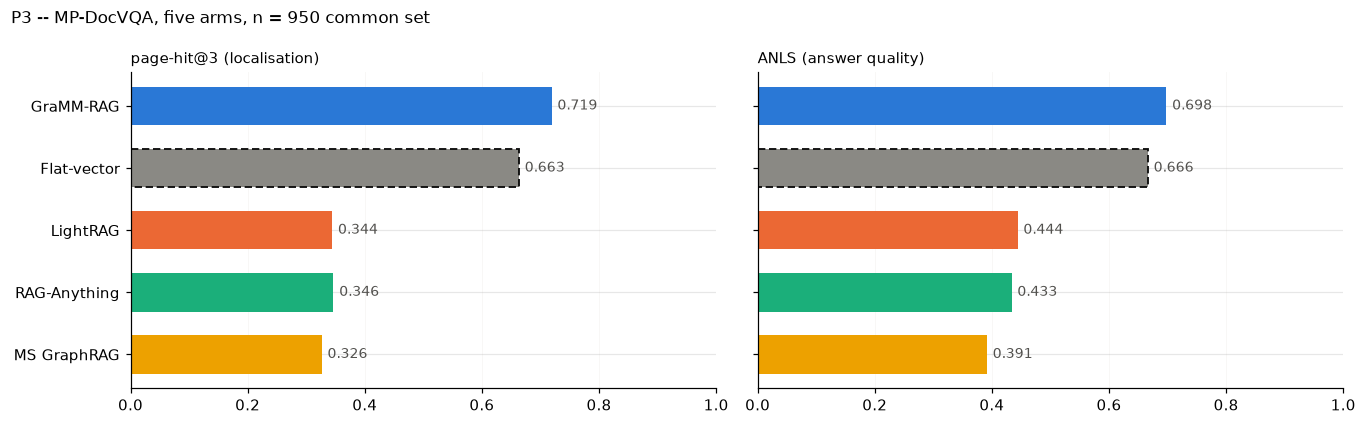

In [51]:
import json, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
P3 = Path('/work/gramm-rag-graphbracket/tier1/p3_mpdocvqa')
an = json.loads((P3/'p3_anls.json').read_text())
fa = json.loads((P3/'p4_failure_attribution.json').read_text())
LAB = {'GraMM-RAG':'GraMM-RAG','Flat-vector':'Flat-vector','LightRAG':'LightRAG 1.5.7',
       'RAG-Anything':'RAG-Anything 1.2.8','MS GraphRAG':'MS GraphRAG 2.7.2'}
ORDER = ['GraMM-RAG','Flat-vector','LightRAG','RAG-Anything','MS GraphRAG']
n = an['n_common']
print(f'five-arm common set n = {n}\n')
# hit@any is the recall comparison the attribution path does not contaminate, and is reported
# beside hit@3. NOT for GraMM: its retrieved_pages is the graph leg only, while its final context
# comes from hybrid fusion with a dense leg -- the two fields measure different stages.
loc = json.loads((P3/'p3_localisation_common950.json').read_text())
LK = {'GraMM-RAG':'gramm','Flat-vector':'flat','LightRAG':'lightrag','RAG-Anything':'s2','MS GraphRAG':'s5'}
print(f"{'arm':16s}{'page-hit@3':>11s}{'hit@any':>9s}{'ANLS':>8s}{'SD':>7s}{'img/q':>7s}")
hit, anls = {}, {}
for a in ORDER:
    c = fa['cells'][a]; hit[a] = (c['BOTH_OK']+c['CONVERSION_MISS'])/n
    assert abs(hit[a] - loc[LK[a]]['page_hit_at_3']) < 5e-4, f'{a}: P4 cells and n=950 localisation disagree'
    pa = an['per_arm'][a]; anls[a] = pa['anls']
    ha = '     —' if a == 'GraMM-RAG' else f"{loc[LK[a]]['hit_any']:.4f}"
    print(f"{a:16s}{hit[a]:>11.4f}{ha:>9s}{pa['anls']:>8.4f}{pa['sd']:>7.3f}{pa['images_per_question']:>7.2f}")
# C-80: the page-matched control. It has no P4 attribution cells (it postdates that run), so
# its row is read straight from the localisation and ANLS artefacts.
if 'flatk3' in loc:
    pa = an['per_arm']['Flat-vector (k=3)']
    print(f"{'Flat-vector (k=3)':16s}{loc['flatk3']['page_hit_at_3']:>11.4f}{'—':>9s}"
          f"{pa['anls']:>8.4f}{pa['sd']:>7.3f}{pa['images_per_question']:>7.2f}")
    g3 = an['contrasts']['GraMM-RAG - Flat-vector (k=3)']
    b3 = an['contrasts']['Flat-vector (k=3) - Flat-vector']
    print(f"\nPAGE-MATCHED CONTROL (C-80): GraMM - Flat(k=3) ANLS {g3['diff']:+.4f} "
          f"[{g3['lo']:+.4f}, {g3['hi']:+.4f}] -- not distinguishable from zero.")
    print(f"  The control's third page alone is worth {b3['diff']:+.4f} "
          f"[{b3['lo']:+.4f}, {b3['hi']:+.4f}] -- GraMM's published +0.0315 lead over the")
    print('  k=2 control was the page budget, not retrieval (FLAT_K3_PREREGISTRATION.md).')
c = an['contrasts']['RAG-Anything - LightRAG']
print(f"\nPRIMARY (pre-registered): RAG-Anything - LightRAG ANLS {c['diff']:+.4f} "
      f"[{c['lo']:+.4f}, {c['hi']:+.4f}] -- CI contains zero: prediction HELD")
print('Retrieval level: +0.0021 [-0.0074, +0.0116], n=950 -- both arms share one attribution')
print('path, so every attribution artefact cancels in this contrast.')
print('\nimg/q differs by arm under one k=3 cap: the cap equalises the CEILING, not the FILL.')

# Two panels, not a dual axis: localisation and answer quality are different measures.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True)
y = np.arange(len(ORDER))
for ax, vals, title in ((axes[0], hit, 'page-hit@3 (localisation)'),
                        (axes[1], anls, 'ANLS (answer quality)')):
    v = [vals[a] for a in ORDER]
    cols = [ARM_COL[LAB[a]] for a in ORDER]
    bars = ax.barh(y, v, height=0.62, color=cols, edgecolor=ARM_COL['Flat-vector'], linewidth=0)
    for b, a in zip(bars, ORDER):            # control carries a dashed outline (secondary enc.)
        if a == 'Flat-vector':
            b.set_edgecolor('#0b0b0b'); b.set_linewidth(1.2); b.set_linestyle((0,(4,2)))
    for yi, vi in zip(y, v):
        ax.text(vi + 0.01, yi, f'{vi:.3f}', va='center', fontsize=9, color='#52514e')
    ax.set_xlim(0, 1); ax.set_title(title, fontsize=10, loc='left')
    ax.grid(axis='x', color='#e6e5e0', linewidth=0.6); ax.set_axisbelow(True)
    for sp in ('top','right'): ax.spines[sp].set_visible(False)
axes[0].set_yticks(y); axes[0].set_yticklabels(ORDER); axes[0].invert_yaxis()
fig.suptitle(f'P3 -- MP-DocVQA, five arms, n = {n} common set', x=0.01, ha='left', fontsize=11)
plt.tight_layout(); plt.savefig(FIG/'pc_fig22_p3.png', bbox_inches='tight'); plt.show()

## 23. P4 — failure attribution: the conversion frontier, per corpus
Each failed question is coded by joining two facts already measured -- did the gold evidence
reach the generator's context, and was the answer right -- at no API cost. The frontier plots
localisation (x) against **conversion given a hit** (y).

**One panel per corpus, never pooled.** The x-axis is a different measurement in each: ctx-hit
on MMLongBench, quote-recall over the k=3 context on DocBench, page-hit@3 on MP-DocVQA.

**DocBench's y-axis is not like-for-like.** Its conversion is scored with ANLS at a 0.5 edit
threshold against free-form prose golds; DocBench's own headline metric is judge accuracy. Its
low conv|hit is partly a metric artefact and is marked as such, not read as a corpus property.

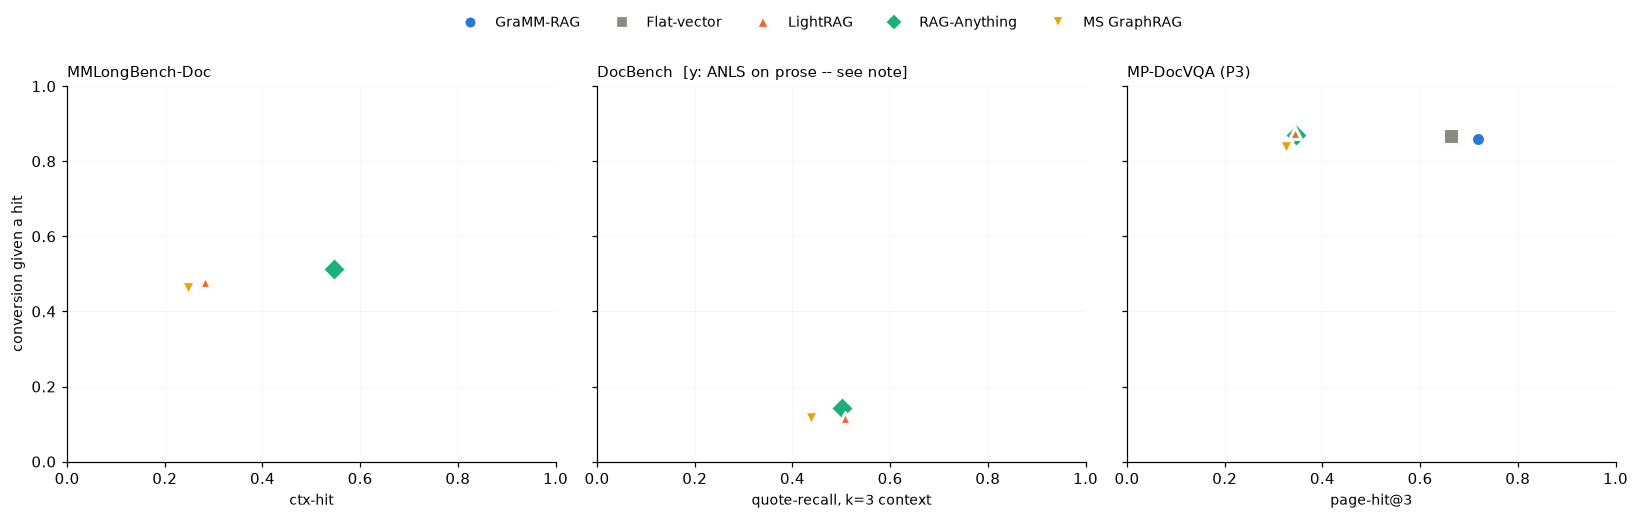


corpus            arm             localisation  conv|hit
MMLongBench-Doc   LightRAG              0.2816    0.4788
MMLongBench-Doc   RAG-Anything          0.5465    0.5131
MMLongBench-Doc   MS GraphRAG           0.2482    0.4615
DocBench          LightRAG              0.5068    0.1162
DocBench          RAG-Anything          0.5014    0.1421
DocBench          MS GraphRAG           0.4384    0.1156
MP-DocVQA (P3)    GraMM-RAG             0.7189    0.8594
MP-DocVQA (P3)    Flat-vector           0.6632    0.8667
MP-DocVQA (P3)    LightRAG              0.3442    0.8746
MP-DocVQA (P3)    RAG-Anything          0.3463    0.8693
MP-DocVQA (P3)    MS GraphRAG           0.3263    0.8387
Within a corpus, arms differ in LOCALISATION far more than in CONVERSION; across corpora
the conversion rate itself moves (0.46-0.51 MMLongBench, 0.84-0.88 MP-DocVQA). DocBench
is excluded from that comparison on the metric caveat above.


In [52]:
GB = Path('/work/gramm-rag-graphbracket/tier1')
mm = json.loads((GB/'p4_failure_mmlongbench.json').read_text())['arms']
db = json.loads((GB/'p4_failure_docbench.json').read_text())['arms']
PANELS = [
  ('MMLongBench-Doc', 'ctx-hit', {a: (d['ctx_hit'], d['conversion_given_hit']) for a, d in mm.items()}, False),
  ('DocBench', 'quote-recall, k=3 context',
   {a: (d['quote_recall_in_context_k3'], d['conversion_given_hit']) for a, d in db.items()}, True),
  ('MP-DocVQA (P3)', 'page-hit@3',
   {a: (hit[a], fa['conversion_given_hit'][a]) for a in ORDER}, False)]
# Direct labels COLLIDED on first render: on MP-DocVQA LightRAG (0.344, 0.875) and
# RAG-Anything (0.346, 0.869) nearly coincide, as do Flat-vector and GraMM; on DocBench
# MS GraphRAG sat under LightRAG. No label placement fixes genuinely coincident points, so
# identity moves to a shared legend plus a DISTINCT MARKER per arm (secondary encoding, so
# identity is never colour-alone). The printed table below is the exact-value view.
MARK = {'GraMM-RAG':'o', 'Flat-vector':'s', 'LightRAG':'^', 'RAG-Anything':'D', 'MS GraphRAG':'v'}
SIZE = {'RAG-Anything':125, 'Flat-vector':105, 'GraMM-RAG':85, 'LightRAG':60, 'MS GraphRAG':80}
ZO   = {'RAG-Anything':3, 'Flat-vector':3, 'GraMM-RAG':5, 'LightRAG':6, 'MS GraphRAG':4}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
seen = {}
for ax, (title, xl, pts, caveat) in zip(axes, PANELS):
    for a, (x, yv) in pts.items():
        # LightRAG and RAG-Anything nearly COINCIDE on MP-DocVQA -- that is the pre-registered
        # primary prediction made visible, not a plotting accident -- and on first render the
        # diamond hid the triangle completely. Larger markers draw first and smaller ones on
        # top, so a coincident pair reads as a ring around a point: both arms stay visible.
        h = ax.scatter([x], [yv], s=SIZE.get(a, 85), color=ARM_COL[LAB.get(a, a)],
                       edgecolor='#fcfcfb', linewidth=2, zorder=ZO.get(a, 3),
                       marker=MARK.get(a, 'o'), label=a)
        seen.setdefault(a, h)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel(xl, fontsize=9); ax.set_title(title + ('  [y: ANLS on prose -- see note]' if caveat else ''),
                                               fontsize=10, loc='left')
    ax.grid(color='#e6e5e0', linewidth=0.6); ax.set_axisbelow(True)
    for sp in ('top','right'): ax.spines[sp].set_visible(False)
axes[0].set_ylabel('conversion given a hit', fontsize=9)
order = [a for a in ORDER if a in seen]
# Marker SIZE varies in the plot only to un-occlude coincident points. Size reads as
# magnitude, so the legend must not inherit it -- uniform handles, identity by hue+shape.
from matplotlib.lines import Line2D
handles = [Line2D([], [], linestyle='none', marker=MARK.get(a,'o'), markersize=8,
                  markerfacecolor=ARM_COL[LAB.get(a,a)], markeredgecolor='#fcfcfb',
                  markeredgewidth=1.5) for a in order]
fig.legend(handles, order, loc='upper center', ncol=len(order),
           frameon=False, fontsize=9, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.savefig(FIG/'pc_fig23_conversion_frontier.png', bbox_inches='tight'); plt.show()
print(f"\n{'corpus':18s}{'arm':15s}{'localisation':>13s}{'conv|hit':>10s}")
for title, xl, pts, _ in PANELS:
    for a in ORDER:
        if a in pts:
            x, yv = pts[a]; print(f'{title:18s}{a:15s}{x:>13.4f}{yv:>10.4f}')
print('Within a corpus, arms differ in LOCALISATION far more than in CONVERSION; across corpora')
print('the conversion rate itself moves (0.46-0.51 MMLongBench, 0.84-0.88 MP-DocVQA). DocBench')
print('is excluded from that comparison on the metric caveat above.')